# RemixFormer++ + 7PCL-DirGM + CKTG + ARFP + **Novel Reliability-Gated Heuristic**

This corrected notebook keeps the existing paper-inspired downstream pipeline and adds an explicit, independently ablatable novelty module.

**Important research distinction:** the Wang et al. components are retained as the paper-inspired baseline. The new module below is a **proposed heuristic novelty**, not a claim that it appears in the 7PCL paper.

Novelty:
1. Attribute probability is reliability-gated using prediction confidence.
2. Graph support is computed from the directed CKTG neighborhood.
3. Contradiction is penalized when a melanoma prediction conflicts with the checklist evidence.
4. A nonlinear interaction bonus rewards coherent high-risk attribute combinations.
5. The final heuristic score is calibrated on the validation split only, then evaluated on the test split.
6. Ablations compare the full heuristic against probability-only, confidence-only, graph-only, and no-interaction variants.

The notebook assumes the already-trained RemixFormer++ checkpoint and the variables produced by the preceding cells are available.


## Non-zero heuristic calibration update

This version intentionally excludes `lambda = 0.0` from validation calibration.
The heuristic lambda is selected from positive values (`0.10` to `2.00`) using
validation macro-F1, and an assertion verifies that the selected lambda is non-zero.

**Research note:** this guarantees that the heuristic contributes mathematically,
but it does not guarantee that the heuristic improves performance. Report the
positive-lambda ablation against the neural baseline.

## Correction audit

This version fixes the main downstream issues: (1) all five diagnosis classes are represented in the 12-node graph; (2) RemixFormer++'s five 768-D tokens are preserved instead of collapsing everything into one vector; (3) GD-DDW token and attribute weights are used in the forward pass; (4) case-node features use soft probabilities rather than hard argmax predictions; (5) labeled adjacency matrices and edge tables are saved.

**Research caution:** the five-class graph and heuristic are a proposed extension of the melanoma-centered 7PCL formulation. Verify every equation against the source paper before reporting final scientific claims.


**Execution fix v2:** The evidence export uses the actual stored key `heuristic_attribute_evidence` rather than the nonexistent `heuristic_evidence` key.

In [1]:
import shutil
# 1. Install dependencies

!pip -q install timm scikit-learn seaborn
import re
import os
import json
import math
import time
import random
import warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode

import timm

from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore")

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.10.0+cu128
CUDA: True
GPU: Tesla T4


In [2]:
# 2. Configuration
from pathlib import Path

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Raw Derm7pt release supplied by the user
DATA_ROOT = Path("/kaggle/input/datasets/menakamohanakumar/derm7pt/release_v0")

# Kaggle input root for the two pretrained checkpoints
KAGGLE_INPUT_ROOT = Path("/kaggle/input")

OUTPUT_ROOT = Path("/kaggle/working/remixformerpp_full_verified")
CKPT_DIR = OUTPUT_ROOT / "checkpoints"
INTERMEDIATE_DIR = OUTPUT_ROOT / "intermediates"
PLOT_DIR = OUTPUT_ROOT / "plots"
REPORT_DIR = OUTPUT_ROOT / "reports"
for p in [CKPT_DIR, INTERMEDIATE_DIR, PLOT_DIR, REPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# Paper reports 200 supervised epochs. Reduce temporarily only for a smoke test.
EPOCHS_THIS_RUN = 50

# Kaggle memory controls
BATCH_SIZE = 1
GRAD_ACCUM_STEPS = 8
NUM_WORKERS = 0
AMP_ENABLED = torch.cuda.is_available()
USE_GRAD_CHECKPOINTING = True
DERM_WINDOW_CHUNK = 4
LOCAL_CROP_CHUNK = 2
CLIP_GRAD_NORM = 1.0

# Paper training settings
LR = 1e-4
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-4
CHECKLIST_LOSS_WEIGHT = 1.0  # joint checklist supervision used by this reimplementation
PAPER_MODE = True
ACCURACY_BOOST_MODE = False

# Paper dimensions
CLINICAL_SIZE = 896
GLOBAL_CLINICAL_SIZE = 384
LOCAL_PATCH_SIZE = 224
DERMOSCOPY_SIZE = 1024
DERM_WINDOW_SIZE = 256
NUM_DERM_WINDOWS = 16
LSM_K = 4

SWIN_EMBED_DIM = 96
SWIN_DEPTHS = (2, 2, 6, 2)
SWIN_HEADS = (3, 6, 12, 24)
SWIN_WINDOW = 7
SWIN_MLP_RATIO = 4.0

VIT_DIM = 384
VIT_DEPTH = 12
VIT_HEADS = 6
MSTA_TEMPLATES = 32

NUM_DIAG_CLASSES = 5
DIAG_NAMES = ["BCC", "Nev", "Mel", "SK", "Misc"]
assert len(DIAG_NAMES) == NUM_DIAG_CLASSES

# Metadata used as input to the metadata branch. Checklist columns are targets, not inputs.
METADATA_COLUMNS_CANDIDATES = [
    "seven_point_score",
    "level_of_diagnostic_difficulty",
    "elevation",
    "location",
    "sex",
    "management",
]

# Exact official split files are expected in the raw Derm7pt release.
SPLIT_FILES = {
    "train": "train_indexes.csv",
    "val": "valid_indexes.csv",
    "test": "test_indexes.csv",
}

# Do not guess checkpoint semantics. The audit cell discovers and classifies them.
PAD_CHECKPOINT_PATH = ""
ISIC_CHECKPOINT_PATH = ""

assert CLINICAL_SIZE == 896
assert GLOBAL_CLINICAL_SIZE == 384
assert LOCAL_PATCH_SIZE == 224
assert DERMOSCOPY_SIZE == 1024
assert DERM_WINDOW_SIZE == 256
assert NUM_DERM_WINDOWS == 16
assert LSM_K == 4
assert VIT_DIM == 384
assert VIT_DEPTH == 12
assert VIT_HEADS == 6
assert MSTA_TEMPLATES == 32
assert NUM_DIAG_CLASSES == 5
assert PAPER_MODE and not ACCURACY_BOOST_MODE

print("Device:", DEVICE)
print("Derm7pt root:", DATA_ROOT)
print("Epochs:", EPOCHS_THIS_RUN)
print("Paper mode:", PAPER_MODE)


# LSM settings
LSM_TRAIN_TEMPERATURE = 0.7
LSM_PROPOSAL_GRID_SIZE = 3  # 224px corresponds to roughly a 3x3 final-stage feature area
LSM_VISUALIZE_ONLY_AFTER_TRAINING = True

assert EPOCHS_THIS_RUN == 50
assert LSM_K == 4
assert LSM_PROPOSAL_GRID_SIZE == 3


Device: cuda
Derm7pt root: /kaggle/input/datasets/menakamohanakumar/derm7pt/release_v0
Epochs: 50
Paper mode: True


In [3]:
# 3. Load raw Derm7pt metadata + official split indexes
from sklearn.preprocessing import OneHotEncoder

META_PATH = DATA_ROOT / "meta" / "meta.csv"
if not META_PATH.exists():
    raise FileNotFoundError(f"Missing Derm7pt metadata: {META_PATH}")

df = pd.read_csv(META_PATH)
print("Metadata:", META_PATH, "rows:", len(df))
print("Columns:", df.columns.tolist())

# Official split files from the original Derm7pt release.
split_indices = {}
for split, filename in SPLIT_FILES.items():
    path = DATA_ROOT / "meta" / filename
    if not path.exists():
        raise FileNotFoundError(
            f"Missing official split file: {path}\n"
            "Do not invent a split for this reproduction. Upload the original train_indexes.csv, "
            "valid_indexes.csv and test_indexes.csv if they are absent."
        )
    idx_df = pd.read_csv(path)
    if "indexes" not in idx_df.columns:
        raise KeyError(f"{path} must contain an 'indexes' column.")
    split_indices[split] = idx_df["indexes"].astype(int).tolist()

df["_split"] = "unassigned"
for split, idxs in split_indices.items():
    df.loc[idxs, "_split"] = split

if (df["_split"] == "unassigned").any():
    raise RuntimeError("Some meta.csv rows are not present in the official split files.")
if len(set(split_indices["train"]) & set(split_indices["val"])):
    raise RuntimeError("Train/validation split overlap detected.")
if len(set(split_indices["train"]) & set(split_indices["test"])):
    raise RuntimeError("Train/test split overlap detected.")
if len(set(split_indices["val"]) & set(split_indices["test"])):
    raise RuntimeError("Validation/test split overlap detected.")

# Diagnosis mapping used by the five-class Derm7pt task.
def map_diagnosis(raw):
    s = str(raw).strip().lower()
    if "basal cell" in s:
        return 0
    if "nevus" in s or "naevus" in s:
        return 1
    if "melanoma" in s:
        return 2
    if "seborrheic keratosis" in s or "seborrhoeic keratosis" in s:
        return 3
    return 4

df["diagnosis_id"] = df["diagnosis"].map(map_diagnosis).astype(int)

# Resolve image paths from the raw release. The metadata's clinic/derm fields are used directly.
IMAGE_ROOT = DATA_ROOT / "images"

def resolve_image(value):
    raw = Path(str(value))
    candidates = [
        raw if raw.is_absolute() else DATA_ROOT / raw,
        IMAGE_ROOT / raw,
        IMAGE_ROOT / raw.name,
        DATA_ROOT / raw.name,
    ]
    for c in candidates:
        if c.is_file():
            return c
    matches = list(IMAGE_ROOT.rglob(raw.name))
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(
        f"Could not resolve image '{value}'. Searched under {IMAGE_ROOT}."
    )

df["clinical_path"] = df["clinic"].map(resolve_image)
df["dermoscopy_path"] = df["derm"].map(resolve_image)

print("\nOfficial split sizes:")
print(df["_split"].value_counts().reindex(["train","val","test"]))
print("\nDiagnosis distribution:")
print(pd.crosstab(df["_split"], df["diagnosis_id"]).rename(columns=dict(enumerate(DIAG_NAMES))))

assert len(df) == 1011, f"Expected 1011 Derm7pt cases, got {len(df)}"
assert all(df["clinical_path"].map(Path.is_file))
assert all(df["dermoscopy_path"].map(Path.is_file))


Metadata: /kaggle/input/datasets/menakamohanakumar/derm7pt/release_v0/meta/meta.csv rows: 1011
Columns: ['case_num', 'diagnosis', 'seven_point_score', 'pigment_network', 'streaks', 'pigmentation', 'regression_structures', 'dots_and_globules', 'blue_whitish_veil', 'vascular_structures', 'level_of_diagnostic_difficulty', 'elevation', 'location', 'sex', 'management', 'clinic', 'derm', 'case_id', 'notes']

Official split sizes:
_split
train    413
val      203
test     395
Name: count, dtype: int64

Diagnosis distribution:
diagnosis_id  BCC  Nev  Mel  SK  Misc
_split                               
test           16  219  101  19    40
train          19  256   90  16    32
val             7  100   61  10    25


In [4]:
# 4. Metadata + seven-point checklist targets
CHECKLIST_COLUMNS = {
    "PN": "pigment_network",
    "BWV": "blue_whitish_veil",
    "VS": "vascular_structures",
    "PIG": "pigmentation",
    "STR": "streaks",
    "DaG": "dots_and_globules",
    "RS": "regression_structures",
}

METADATA_COLUMNS = [c for c in METADATA_COLUMNS_CANDIDATES if c in df.columns]
if not METADATA_COLUMNS:
    raise RuntimeError("No metadata columns were found.")

# Fit one-hot ONLY on the official training split.
train_mask = df["_split"].eq("train")
for c in METADATA_COLUMNS:
    df[c] = df[c].astype("string").fillna("UNKNOWN").replace({"": "UNKNOWN"})

try:
    meta_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    meta_encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

meta_encoder.fit(df.loc[train_mask, METADATA_COLUMNS])
meta_matrix = meta_encoder.transform(df[METADATA_COLUMNS]).astype(np.float32)
META_DIM = meta_matrix.shape[1]
metadata_tensor_all = torch.tensor(meta_matrix, dtype=torch.float32)

CHECKLIST_SPECS = {}
for short_name, col in CHECKLIST_COLUMNS.items():
    raw = df[col].astype("string").str.strip()
    missing_tokens = {"", "nan", "none", "null", "na", "n/a", "missing", "unknown", "<na>"}
    raw = raw.mask(raw.str.lower().isin(missing_tokens))
    train_labels = sorted(raw.loc[train_mask].dropna().astype(str).unique().tolist())
    label_to_id = {v: i for i, v in enumerate(train_labels)}
    encoded = raw.map(label_to_id)
    target = encoded.fillna(-1).astype(int).to_numpy()
    mask = (target >= 0).astype(np.float32)
    CHECKLIST_SPECS[short_name] = {
        "column": col,
        "classes": train_labels,
        "num_classes": len(train_labels),
        "target": target,
        "mask": mask,
    }

df["_meta_row"] = np.arange(len(df))

print("Metadata columns:", METADATA_COLUMNS)
print("Metadata one-hot dimension:", META_DIM)
for name, spec in CHECKLIST_SPECS.items():
    print(f"{name}: {spec['num_classes']} classes -> {spec['classes']}")


Metadata columns: ['seven_point_score', 'level_of_diagnostic_difficulty', 'elevation', 'location', 'sex', 'management']
Metadata one-hot dimension: 30
PN: 3 classes -> ['absent', 'atypical', 'typical']
BWV: 2 classes -> ['absent', 'present']
VS: 8 classes -> ['absent', 'arborizing', 'comma', 'dotted', 'hairpin', 'linear irregular', 'within regression', 'wreath']
PIG: 4 classes -> ['absent', 'diffuse irregular', 'diffuse regular', 'localized irregular']
STR: 3 classes -> ['absent', 'irregular', 'regular']
DaG: 3 classes -> ['absent', 'irregular', 'regular']
RS: 4 classes -> ['absent', 'blue areas', 'combinations', 'white areas']


In [5]:
# 5. Dataset and paper-size transforms

class RandomRotation10(transforms.RandomRotation):
    """Paper-aligned rotation: uniformly choose 0..180 degrees in 10-degree steps."""
    def __init__(self):
        super().__init__((0, 180), interpolation=InterpolationMode.BILINEAR)

    @staticmethod
    def get_params(degrees):
        low, high = float(degrees[0]), float(degrees[1])
        choices = list(range(int(low), int(high) + 1, 10))
        angle = choices[random.randrange(len(choices))]
        return float(angle)

class PaperTrainTransform:
    """
    Implements the augmentation family reported in RemixFormer++:
    flip, random crop with area scaling 0.65..1.0, rotation 0..180 in
    multiples of 10, affine translation <=15%, shear -10..10,
    and brightness/contrast/saturation jitter 0.5..1.5.
    """
    def __init__(self, size):
        self.size = size

    def __call__(self, img):
        img = img.resize((self.size, self.size), Image.Resampling.BICUBIC)

        if random.random() < 0.5:
            img = transforms.functional.hflip(img)
        if random.random() < 0.5:
            img = transforms.functional.vflip(img)

        # Random crop with area scaling 0.65..1.0, then restore to target size.
        area_scale = random.uniform(0.65, 1.0)
        crop_size = max(1, int(round(self.size * math.sqrt(area_scale))))
        crop_size = min(crop_size, self.size)
        top = random.randint(0, self.size - crop_size)
        left = random.randint(0, self.size - crop_size)
        img = transforms.functional.crop(img, top, left, crop_size, crop_size)
        img = img.resize((self.size, self.size), Image.Resampling.BICUBIC)

        angle = RandomRotation10.get_params((0, 180))
        img = transforms.functional.rotate(
            img, angle, interpolation=InterpolationMode.BILINEAR
        )

        translate = (
            random.uniform(-0.15, 0.15) * self.size,
            random.uniform(-0.15, 0.15) * self.size
        )
        shear = (
            random.uniform(-10, 10),
            random.uniform(-10, 10)
        )
        img = transforms.functional.affine(
            img, angle=0.0, translate=translate, scale=1.0, shear=shear,
            interpolation=InterpolationMode.BILINEAR
        )

        img = transforms.ColorJitter(
            brightness=(0.5, 1.5),
            contrast=(0.5, 1.5),
            saturation=(0.5, 1.5)
        )(img)

        return transforms.functional.to_tensor(img)

class PaperEvalTransform:
    def __init__(self, size):
        self.size = size

    def __call__(self, img):
        img = img.resize((self.size, self.size), Image.Resampling.BICUBIC)
        return transforms.functional.to_tensor(img)

train_tf = PaperTrainTransform(CLINICAL_SIZE)
eval_tf = PaperEvalTransform(CLINICAL_SIZE)
train_derm_tf = PaperTrainTransform(DERMOSCOPY_SIZE)
eval_derm_tf = PaperEvalTransform(DERMOSCOPY_SIZE)

class Derm7ptDataset(Dataset):
    def __init__(self, frame, metadata_all, transform_c, transform_d):
        self.frame = frame.reset_index(drop=True).copy()
        self.metadata = metadata_all[self.frame["_meta_row"].to_numpy()].clone()
        self.transform_c = transform_c
        self.transform_d = transform_d

        self.check_targets = {}
        self.check_masks = {}
        for name, spec in CHECKLIST_SPECS.items():
            gi = self.frame["_meta_row"].to_numpy()
            self.check_targets[name] = torch.tensor(spec["target"][gi], dtype=torch.long)
            self.check_masks[name] = torch.tensor(spec["mask"][gi], dtype=torch.float32)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        c = self.transform_c(Image.open(row["clinical_path"]).convert("RGB"))
        d = self.transform_d(Image.open(row["dermoscopy_path"]).convert("RGB"))

        checklist, checklist_mask = {}, {}
        for name in CHECKLIST_SPECS:
            checklist[name] = self.check_targets[name][idx].clone()
            checklist_mask[name] = self.check_masks[name][idx].clone()

        return {
            "clinical": c,
            "dermoscopy": d,
            "metadata": self.metadata[idx].clone(),
            "diagnosis": torch.tensor(int(row["diagnosis_id"]), dtype=torch.long),
            "checklist": checklist,
            "checklist_mask": checklist_mask,
            "row_index": torch.tensor(int(row["_meta_row"]), dtype=torch.long),
        }

train_ds = Derm7ptDataset(df[df["_split"]=="train"], metadata_tensor_all, train_tf, train_derm_tf)
val_ds = Derm7ptDataset(df[df["_split"]=="val"], metadata_tensor_all, eval_tf, eval_derm_tf)
test_ds = Derm7ptDataset(df[df["_split"]=="test"], metadata_tensor_all, eval_tf, eval_derm_tf)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

print("Train:", len(train_ds), "Val:", len(val_ds), "Test:", len(test_ds))
print("Paper augmentation: enabled for training; validation/test use resize only.")


Train: 413 Val: 203 Test: 395
Paper augmentation: enabled for training; validation/test use resize only.


## 6. Modified Swin with CLS_WMSA

This is the central correction compared with the previous notebook.

The paper replaces ordinary Swin WMSA with CLS_WMSA. A class token participates in every local
window. The final-stage CLS-to-patch attention is used by LSM.

The implementation below keeps Swin-T's four stages and shifted windows, while adding a global
CLS token to every window attention operation.

In [6]:
# 6. Window helpers

def window_partition_padded(x, window_size):
    # x: [B,H,W,C]
    B, H, W, C = x.shape
    pad_h = (window_size - H % window_size) % window_size
    pad_w = (window_size - W % window_size) % window_size

    x_pad = F.pad(x, (0, 0, 0, pad_w, 0, pad_h))
    Hp, Wp = H + pad_h, W + pad_w

    windows = x_pad.view(
        B,
        Hp // window_size,
        window_size,
        Wp // window_size,
        window_size,
        C
    )
    windows = windows.permute(
        0, 1, 3, 2, 4, 5
    ).contiguous().view(
        -1, window_size * window_size, C
    )
    return windows, Hp, Wp, pad_h, pad_w

def window_reverse_padded(windows, window_size, B, H, W):
    Hp = math.ceil(H / window_size) * window_size
    Wp = math.ceil(W / window_size) * window_size

    x = windows.view(
        B,
        Hp // window_size,
        Wp // window_size,
        window_size,
        window_size,
        -1
    )
    x = x.permute(
        0, 1, 3, 2, 4, 5
    ).contiguous().view(B, Hp, Wp, -1)
    return x[:, :H, :W, :]

def build_shift_mask(H, W, window_size, shift_size, device):
    if shift_size == 0:
        return None

    Hp = math.ceil(H / window_size) * window_size
    Wp = math.ceil(W / window_size) * window_size

    img_mask = torch.zeros((1, Hp, Wp, 1), device=device)

    h_slices = (
        slice(0, -window_size),
        slice(-window_size, -shift_size),
        slice(-shift_size, None),
    )
    w_slices = (
        slice(0, -window_size),
        slice(-window_size, -shift_size),
        slice(-shift_size, None),
    )

    cnt = 0
    for h in h_slices:
        for w in w_slices:
            img_mask[:, h, w, :] = cnt
            cnt += 1

    mask_windows, _, _, _, _ = window_partition_padded(
        img_mask, window_size
    )
    mask_windows = mask_windows.view(
        -1,
        window_size * window_size
    )

    attn_mask = mask_windows.unsqueeze(1) - mask_windows.unsqueeze(2)
    attn_mask = attn_mask.masked_fill(attn_mask != 0, -100.0)
    attn_mask = attn_mask.masked_fill(attn_mask == 0, 0.0)
    return attn_mask

In [7]:
# 7. Relative-position CLS window attention

class CLSWindowAttention(nn.Module):
    def __init__(self, dim, num_heads, window_size=7, qkv_bias=True):
        super().__init__()
        self.dim = dim
        self.num_heads = num_heads
        self.window_size = window_size
        head_dim = dim // num_heads
        self.scale = head_dim ** -0.5

        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)
        self.proj = nn.Linear(dim, dim)

        relative_size = (2 * window_size - 1) ** 2
        self.relative_position_bias_table = nn.Parameter(
            torch.zeros(relative_size, num_heads)
        )

        coords_h = torch.arange(window_size)
        coords_w = torch.arange(window_size)
        coords = torch.stack(
            torch.meshgrid(coords_h, coords_w, indexing="ij")
        )
        coords_flatten = torch.flatten(coords, 1)
        relative = coords_flatten[:, :, None] - coords_flatten[:, None, :]
        relative = relative.permute(1, 2, 0).contiguous()
        relative[:, :, 0] += window_size - 1
        relative[:, :, 1] += window_size - 1
        relative[:, :, 0] *= 2 * window_size - 1
        relative_position_index = relative.sum(-1)
        self.register_buffer(
            "relative_position_index",
            relative_position_index,
            persistent=False
        )

        nn.init.trunc_normal_(self.relative_position_bias_table, std=0.02)

    def _relative_bias(self, n_tokens):
        if n_tokens == self.window_size * self.window_size:
            bias = self.relative_position_bias_table[
                self.relative_position_index.reshape(-1)
            ]
            bias = bias.view(
                self.window_size * self.window_size,
                self.window_size * self.window_size,
                -1
            ).permute(2, 0, 1).contiguous()
            return bias

        # Defensive interpolation for unusual window sizes.
        base = self.relative_position_bias_table.T.view(
            self.num_heads,
            2 * self.window_size - 1,
            2 * self.window_size - 1
        )
        target = int(math.sqrt(n_tokens))
        base = F.interpolate(
            base.unsqueeze(0),
            size=(2 * target - 1, 2 * target - 1),
            mode="bicubic",
            align_corners=False
        ).squeeze(0)
        coords = torch.arange(target, device=base.device)
        coords = torch.stack(
            torch.meshgrid(coords, coords, indexing="ij")
        )
        flat = coords.flatten(1)
        rel = flat[:, :, None] - flat[:, None, :]
        rel = rel.permute(1, 2, 0).contiguous()
        rel[:, :, 0] += target - 1
        rel[:, :, 1] += target - 1
        rel[:, :, 0] *= 2 * target - 1
        idx = rel.sum(-1).long()
        return base[:, idx.reshape(-1)].view(
            self.num_heads, target * target, target * target
        )

    def forward(self, patch_windows, cls_token, attn_mask=None):
        # patch_windows: [B*nW, N, C]
        # cls_token: [B, C]
        BNW, N, C = patch_windows.shape

        # Number of windows for this batch.
        B = cls_token.shape[0]
        nW = BNW // B

        cls_rep = cls_token[:, None, :].expand(
            B, nW, C
        ).reshape(BNW, 1, C)

        tokens = torch.cat([cls_rep, patch_windows], dim=1)
        qkv = self.qkv(tokens)
        qkv = qkv.reshape(
            BNW,
            N + 1,
            3,
            self.num_heads,
            C // self.num_heads
        ).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]

        q = q * self.scale
        logits = q @ k.transpose(-2, -1)

        rel = self._relative_bias(N)
        # Relative bias only applies to patch-patch pairs.
        logits[:, :, 1:, 1:] = logits[:, :, 1:, 1:] + rel.unsqueeze(0)

        if attn_mask is not None:
            logits_patch = logits[:, :, 1:, 1:]
            nW = attn_mask.shape[0]
            logits_patch = logits_patch.view(
                B, nW, self.num_heads, N, N
            )
            logits_patch = logits_patch + attn_mask.unsqueeze(0).unsqueeze(2)
            logits[:, :, 1:, 1:] = logits_patch.view(
                BNW, self.num_heads, N, N
            )

        attn = logits.softmax(dim=-1)

        out = attn @ v
        out = out.transpose(1, 2).reshape(BNW, N + 1, C)
        out = self.proj(out)

        cls_out = out[:, 0]
        patch_out = out[:, 1:]

        # Paper-style LSM score:
        # softmax(Q_cls K_patch^T) element-wise multiplied by
        # softmax((Q_patch K_cls^T)^T), averaged over heads.
        q_cls = q[:, :, 0:1, :]
        k_patch = k[:, :, 1:, :]
        q_patch = q[:, :, 1:, :]
        k_cls = k[:, :, 0:1, :]

        o1 = (q_cls @ k_patch.transpose(-2, -1)).squeeze(2)
        o2 = (q_patch @ k_cls.transpose(-2, -1)).squeeze(-1)

        s1 = F.softmax(o1, dim=-1)
        s2 = F.softmax(o2, dim=-1)
        score = (s1 * s2).mean(dim=1)

        # Keep the LSM score in window form here:
        # [B*nW, N]. The CLS-Swin block converts it back to the
        # spatial [B,H,W] feature-map layout after reversing windows.
        score = score.view(B, nW, N)

        # Aggregate repeated CLS outputs across windows.
        cls_out = cls_out.view(B, nW, C).mean(dim=1)

        if not self.training:
            score = score.detach()

        return patch_out, cls_out, score

In [8]:
# 8. CLS-Swin blocks, patch merging and pretrained-weight transfer

class Mlp(nn.Module):
    def __init__(self, dim, mlp_ratio=4.0):
        super().__init__()
        hidden = int(dim * mlp_ratio)
        self.fc1 = nn.Linear(dim, hidden)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden, dim)

    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))


class PatchMerging(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.reduction = nn.Linear(4 * dim, 2 * dim, bias=False)
        self.norm = nn.LayerNorm(4 * dim)

    def forward(self, x):
        B, H, W, C = x.shape

        pad_h = H % 2
        pad_w = W % 2
        if pad_h or pad_w:
            x = F.pad(x, (0, 0, 0, pad_w, 0, pad_h))
            H, W = H + pad_h, W + pad_w

        x0 = x[:, 0::2, 0::2, :]
        x1 = x[:, 1::2, 0::2, :]
        x2 = x[:, 0::2, 1::2, :]
        x3 = x[:, 1::2, 1::2, :]
        x = torch.cat([x0, x1, x2, x3], dim=-1)

        return self.reduction(self.norm(x))


class CLSSwinBlock(nn.Module):
    def __init__(
        self,
        dim,
        heads,
        window_size=7,
        shift_size=0,
        mlp_ratio=4.0
    ):
        super().__init__()

        self.dim = dim
        self.window_size = window_size
        self.shift_size = shift_size

        self.norm1 = nn.LayerNorm(dim)
        self.attn = CLSWindowAttention(
            dim,
            heads,
            window_size=window_size
        )

        self.norm2 = nn.LayerNorm(dim)
        self.mlp = Mlp(dim, mlp_ratio)

    def forward(self, x, cls_token):
        B, H, W, C = x.shape

        shortcut = x
        x_norm = self.norm1(x)

        if self.shift_size > 0:
            shifted = torch.roll(
                x_norm,
                shifts=(-self.shift_size, -self.shift_size),
                dims=(1, 2)
            )
        else:
            shifted = x_norm

        windows, Hp, Wp, pad_h, pad_w = window_partition_padded(
            shifted,
            self.window_size
        )

        attn_mask = build_shift_mask(
            H,
            W,
            self.window_size,
            self.shift_size,
            x.device
        )

        patch_out, cls_out, score_windows = self.attn(
            windows,
            cls_token,
            attn_mask=attn_mask
        )

        x = window_reverse_padded(
            patch_out,
            self.window_size,
            B,
            H,
            W
        )

        # Reconstruct the LSM attention score as a spatial map.
        # [B,nW,N] -> [B,Hp,Wp,1] -> [B,H,W].
        score_map = window_reverse_padded(
            score_windows.reshape(
                -1,
                self.window_size * self.window_size,
                1
            ),
            self.window_size,
            B,
            H,
            W
        ).squeeze(-1)

        if self.shift_size > 0:
            x = torch.roll(
                x,
                shifts=(self.shift_size, self.shift_size),
                dims=(1, 2)
            )
            score_map = torch.roll(
                score_map,
                shifts=(self.shift_size, self.shift_size),
                dims=(1, 2)
            )

        x = shortcut + x
        x = x + self.mlp(self.norm2(x))

        return x, cls_out, score_map


class CLSSwinStage(nn.Module):
    """
    One Swin stage.

    Important fix:
    The CLS token must always have the SAME feature width as the patch
    tokens entering CLSWindowAttention.

    Original v23 kept the CLS token at 96 dimensions after stage 1.
    Patch merging changed the patch width to 192, producing:
        target [B, nW, 192]
        source [B, 1, 96]

    Here, when a stage downsamples from C -> 2C, the CLS token is
    explicitly projected with cls_downsample: C -> 2C.
    """

    def __init__(
        self,
        dim,
        depth,
        heads,
        window_size=7,
        downsample=True,
        next_dim=None
    ):
        super().__init__()

        self.dim = dim

        self.blocks = nn.ModuleList([
            CLSSwinBlock(
                dim=dim,
                heads=heads,
                window_size=window_size,
                shift_size=0 if i % 2 == 0 else window_size // 2,
                mlp_ratio=SWIN_MLP_RATIO
            )
            for i in range(depth)
        ])

        self.downsample = (
            PatchMerging(dim)
            if downsample
            else None
        )

        # PatchMerging changes C -> 2C. The CLS token must follow it.
        if self.downsample is not None:
            target_dim = 2 * dim if next_dim is None else next_dim
            if target_dim != 2 * dim:
                raise ValueError(
                    f"PatchMerging expects next dim {2 * dim}, "
                    f"but received {target_dim}."
                )

            self.cls_downsample = nn.Linear(
                dim,
                target_dim,
                bias=True
            )
        else:
            self.cls_downsample = None

    def forward(self, x, cls_token):
        last_score = None

        for block in self.blocks:
            if USE_GRAD_CHECKPOINTING and self.training:

                # Bind the current block as a default argument so that
                # checkpointing cannot accidentally close over a later block.
                def block_fn(x_, c_, block_=block):
                    return block_(x_, c_)

                x, cls_token, last_score = torch.utils.checkpoint.checkpoint(
                    block_fn,
                    x,
                    cls_token,
                    use_reentrant=False
                )
            else:
                x, cls_token, last_score = block(
                    x,
                    cls_token
                )

        if self.downsample is not None:
            x = self.downsample(x)

            # Critical CLS-dimension transition:
            # 96 -> 192 -> 384 -> 768.
            cls_token = self.cls_downsample(cls_token)

        return x, cls_token, last_score


class PatchEmbed(nn.Module):
    # Named to match timm Swin-T keys: patch_embed.proj and patch_embed.norm.
    def __init__(self, in_chans=3, embed_dim=96):
        super().__init__()

        self.proj = nn.Conv2d(
            in_chans,
            embed_dim,
            kernel_size=4,
            stride=4
        )

        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = self.proj(x)
        x = x.permute(0, 2, 3, 1).contiguous()
        return self.norm(x)


class CLSSwinBackbone(nn.Module):
    def __init__(self, pretrained=True, share_stages=None):
        super().__init__()

        self.embed_dim = SWIN_EMBED_DIM
        self.dims = [
            SWIN_EMBED_DIM,
            SWIN_EMBED_DIM * 2,
            SWIN_EMBED_DIM * 4,
            SWIN_EMBED_DIM * 8,
        ]

        if share_stages is None:
            self.patch_embed = PatchEmbed(
                in_chans=3,
                embed_dim=SWIN_EMBED_DIM
            )

            # CLS starts at the same width as stage 1.
            self.cls_token = nn.Parameter(
                torch.zeros(1, 1, SWIN_EMBED_DIM)
            )

            self.layers = nn.ModuleList([
                CLSSwinStage(
                    self.dims[i],
                    SWIN_DEPTHS[i],
                    SWIN_HEADS[i],
                    window_size=SWIN_WINDOW,
                    downsample=(i < 3),
                    next_dim=(
                        self.dims[i + 1]
                        if i < 3
                        else None
                    )
                )
                for i in range(4)
            ])

            self.norm = nn.LayerNorm(self.dims[-1])

            nn.init.trunc_normal_(
                self.cls_token,
                std=0.02
            )

            if pretrained:
                self._load_pretrained_swin()

        else:
            # Local encoder:
            # shared patch embedding + first 3 stages,
            # independent fourth stage.
            self.patch_embed = share_stages.patch_embed
            self.cls_token = share_stages.cls_token

            self.layers = nn.ModuleList([
                share_stages.layers[0],
                share_stages.layers[1],
                share_stages.layers[2],
                CLSSwinStage(
                    self.dims[3],
                    SWIN_DEPTHS[3],
                    SWIN_HEADS[3],
                    window_size=SWIN_WINDOW,
                    downsample=False
                )
            ])

            self.norm = nn.LayerNorm(self.dims[-1])

    def _patch_embed(self, x):
        return self.patch_embed(x)

    def _load_pretrained_swin(self):
        print(
            "Loading ImageNet Swin-T weights where parameter "
            "shapes match..."
        )

        ref = timm.create_model(
            "swin_tiny_patch4_window7_224",
            pretrained=True,
            num_classes=0
        )

        ref_sd = ref.state_dict()
        own_sd = self.state_dict()

        copied = {}

        for k, v in ref_sd.items():
            if (
                k in own_sd
                and own_sd[k].shape == v.shape
            ):
                copied[k] = v

        missing = sorted(
            set(own_sd) - set(copied)
        )

        self.load_state_dict(
            copied,
            strict=False
        )

        print(
            f"Copied {len(copied)} pretrained tensors; "
            f"{len(missing)} new/modified tensors remain."
        )

        del ref

    def forward(self, x, return_sequence=True):
        x = self._patch_embed(x)
        B = x.shape[0]

        cls = self.cls_token.expand(
            B,
            -1,
            -1
        ).squeeze(1)

        last_score = None

        for stage in self.layers:
            x, cls, score = stage(
                x,
                cls
            )

            if score is not None:
                last_score = score

        x = self.norm(x)
        cls = self.norm(cls)

        patches = x.flatten(1, 2)

        # Final invariant:
        # CLS width == final patch width == 768.
        if cls.shape[-1] != patches.shape[-1]:
            raise RuntimeError(
                "CLS/patch dimension mismatch after Swin stages: "
                f"CLS={cls.shape[-1]}, patches={patches.shape[-1]}"
            )

        return {
            "cls": cls,
            "patches": patches,
            "map": x,
            "lsm_score": last_score
        }


## 9. Lesion Selection Module

The paper selects `Kp=4` salient regions and enlarges the selected regions to 224×224
from the original high-resolution 896×896 clinical image.

Training uses attention-distribution sampling. Evaluation uses deterministic top-K.

In [9]:
# 9. Corrected paper-aligned Lesion Selection Module

class LesionSelectionModule(nn.Module):
    """
    RemixFormer++ LSM.

    Paper behavior:
      1. obtain S_attn from final-stage CLS/patch Q-K interactions;
      2. Kp=4 largest attention values are used for lesion patches;
      3. attention is computed on the downsampled global feature map;
      4. the selected areas are enlarged to 224x224 on the original 896x896 image;
      5. during training, attention sampling is used to avoid a hard top-K gradient break.

    The paper does not publish the authors' exact sampler source code. We therefore use a
    straight-through Gumbel reparameterization as the differentiable Monte-Carlo approximation,
    while keeping the paper's categorical attention-distribution sampling interpretation.
    In evaluation there is no approximation: top-K over S_attn is used.
    """
    def __init__(self, k=4, crop_size=224):
        super().__init__()
        self.k = k
        self.crop_size = crop_size

    def _training_attention_sample(self, score):
        B, Hs, Ws = score.shape
        logits = score.flatten(1)
        probs = F.softmax(logits, dim=-1)

        hard_vectors = []
        indices = []

        for _ in range(self.k):
            one_hot = F.gumbel_softmax(
                logits,
                tau=LSM_TRAIN_TEMPERATURE,
                hard=True,
                dim=-1
            )
            hard_vectors.append(one_hot)
            indices.append(one_hot.argmax(dim=-1))

        sample_matrix = torch.stack(hard_vectors, dim=1)
        idx = torch.stack(indices, dim=1)
        return idx, probs, sample_matrix

    def _inference_topk(self, score):
        B, Hs, Ws = score.shape
        probs = F.softmax(score.flatten(1), dim=-1)
        k = min(self.k, Hs * Ws)
        idx = torch.topk(probs, k=k, dim=-1).indices
        sample_matrix = F.one_hot(
            idx, num_classes=Hs * Ws
        ).to(probs.dtype)
        return idx, probs, sample_matrix

    def _crop_grid(self, centers_y, centers_x, H, W, device):
        B, K = centers_y.shape
        half = self.crop_size / 2.0

        yy = torch.linspace(
            -half + 0.5, half - 0.5, self.crop_size, device=device
        )
        xx = torch.linspace(
            -half + 0.5, half - 0.5, self.crop_size, device=device
        )
        gy, gx = torch.meshgrid(yy, xx, indexing="ij")

        gy = gy[None, None] + centers_y[:, :, None, None]
        gx = gx[None, None] + centers_x[:, :, None, None]

        gy = gy / max(H - 1, 1) * 2 - 1
        gx = gx / max(W - 1, 1) * 2 - 1

        return torch.stack([gx, gy], dim=-1)

    def forward(self, image, score):
        B, C, H, W = image.shape
        B2, Hs, Ws = score.shape
        if B != B2:
            raise RuntimeError("LSM batch-size mismatch.")

        if self.training:
            idx, probs, sample_matrix = self._training_attention_sample(score)
        else:
            idx, probs, sample_matrix = self._inference_topk(score)

        # The final global Swin map is the map on which S_attn is computed.
        # Each token corresponds to H/Hs by W/Ws pixels in the original image.
        scale_y = H / float(Hs)
        scale_x = W / float(Ws)

        token_y = (
            torch.arange(Hs, device=image.device, dtype=torch.float32) + 0.5
        ) * scale_y
        token_x = (
            torch.arange(Ws, device=image.device, dtype=torch.float32) + 0.5
        ) * scale_x

        yy, xx = torch.meshgrid(token_y, token_x, indexing="ij")

        centers_y = torch.einsum(
            "bkn,n->bk", sample_matrix, yy.reshape(-1)
        )
        centers_x = torch.einsum(
            "bkn,n->bk", sample_matrix, xx.reshape(-1)
        )

        grid = self._crop_grid(
            centers_y, centers_x, H, W, image.device
        )

        crops = []
        K = grid.shape[1]

        for start in range(0, K, LOCAL_CROP_CHUNK):
            g = grid[:, start:start + LOCAL_CROP_CHUNK]
            b, kk = g.shape[:2]
            g = g.reshape(
                b * kk, self.crop_size, self.crop_size, 2
            )

            img_rep = image[:, None].expand(
                B, kk, C, H, W
            ).reshape(B * kk, C, H, W)

            crop = F.grid_sample(
                img_rep,
                g,
                mode="bilinear",
                padding_mode="border",
                align_corners=True
            )
            crops.append(crop)

        crops = torch.cat(crops, dim=0).view(
            B, K, C, self.crop_size, self.crop_size
        )

        # Keep exact centers for a transparent audit.
        centers = torch.stack([centers_x, centers_y], dim=-1)

        return crops, idx, probs, centers


## 10. Clinical branch

The first three Swin stages are shared between global and local encoders.
The fourth stage is independent, as described in the paper.

CSF performs bidirectional global↔local cross-attention and returns the aligned global
representation and local sequence.

In [10]:
# 10. Clinical branch with CLS_WMSA, LSM K=4 and CSF attention capture
class CrossScaleFusion(nn.Module):
    def __init__(self, dim=768, heads=8):
        super().__init__()
        self.norm_g = nn.LayerNorm(dim)
        self.norm_l = nn.LayerNorm(dim)
        self.g_from_l = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.l_from_g = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.g_proj = nn.Linear(dim, dim)
        self.l_proj = nn.Linear(dim, dim)

    def forward(self, global_seq, local_seq, capture=False):
        g = self.norm_g(global_seq)
        l = self.norm_l(local_seq)
        g_cross, g_attn = self.g_from_l(g,l,l,need_weights=capture,average_attn_weights=False)
        l_cross, l_attn = self.l_from_g(l,g,g,need_weights=capture,average_attn_weights=False)
        g_out = g + self.g_proj(g_cross)
        l_out = l + self.l_proj(l_cross)
        if capture:
            return g_out,l_out,g_attn,l_attn
        return g_out,l_out

class ClinicalBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.global_encoder = CLSSwinBackbone(pretrained=True)
        self.local_encoder = CLSSwinBackbone(pretrained=False, share_stages=self.global_encoder)
        self.lsm = LesionSelectionModule(k=LSM_K, crop_size=LOCAL_PATCH_SIZE)
        self.csf = CrossScaleFusion(dim=768, heads=8)
        self.last_lsm_score = None
        self.last_crop_indices = None
        self.last_crops = None
        self.last_crop_centers = None

    def forward(self,x,capture=False):
        x_global = F.interpolate(x,size=(GLOBAL_CLINICAL_SIZE,GLOBAL_CLINICAL_SIZE),
                                 mode="bicubic",align_corners=False)
        global_out = self.global_encoder(x_global)
        score = global_out["lsm_score"]
        if score is None:
            raise RuntimeError("CLS_WMSA did not return an LSM attention score.")

        crops,crop_idx,probs,crop_centers = self.lsm(x,score)
        self.last_lsm_score = score.detach()
        self.last_crop_indices = crop_idx.detach()
        self.last_crops = crops.detach()
        self.last_crop_centers = crop_centers.detach()

        B,K,C,H,W = crops.shape
        local_out = self.local_encoder(crops.reshape(B*K,C,H,W))
        local_cls = local_out["cls"].view(B,K,-1)
        local_patches = local_out["patches"].view(B,K,-1,768)
        local_seq = torch.cat([local_cls.unsqueeze(2),local_patches],dim=2).reshape(B,-1,768)
        global_seq = torch.cat([global_out["cls"].unsqueeze(1),global_out["patches"]],dim=1)

        if capture:
            g_fused,l_fused,g_attn,l_attn = self.csf(global_seq,local_seq,capture=True)
        else:
            g_fused,l_fused = self.csf(global_seq,local_seq,capture=False)
            g_attn=l_attn=None

        return {
            "global":g_fused[:,0],
            "global_tokens":g_fused,
            "local":l_fused,
            "local_tokens":l_fused,
            "lsm_score":score,
            "crop_indices":crop_idx,
            "crop_probs":probs,
            "crop_centers":crop_centers,
            "csf_global_to_local_attention":g_attn,
            "csf_local_to_global_attention":l_attn,
        }


## 11. Dermoscopy HRWE + MSTA + region encoder

The paper uses 1024×1024 → 16 windows of 256×256, a ViT-S/16 with 384 dimensions,
12 layers and 6 heads, 32 MSTA templates, then a region-level transformer with an image CLS.

In [11]:
# 11. MSTA with explicit texture attention capture

class MSTA(nn.Module):
    """
    Paper equation (15)-(17):
      a_jk = y_i,j dot t_k^T
      c_jk = exp(-s_k a_jk) / sum_l exp(-s_l a_jl)
      E_i,k^TE = sum_j c_jk y_i,j
      E_i^HRWE = E_i^WE + E_i^TE
    """
    def __init__(self, dim=384, num_templates=32):
        super().__init__()
        self.dim = dim
        self.num_templates = num_templates
        self.templates = nn.Parameter(torch.randn(num_templates, dim) * 0.02)
        self.scale = nn.Parameter(torch.ones(num_templates))
        self.proj = nn.Linear(num_templates * dim, dim)

    def forward(self, y, return_attention=False):
        # y: [B,W,N,D]
        # The paper uses direct dot-product similarity, not cosine-normalized similarity.
        a = torch.einsum("bwnd,kd->bwnk", y, self.templates)

        scale = self.scale.view(1, 1, 1, self.num_templates)
        c = F.softmax(-scale * a, dim=-1)

        texture = torch.einsum("bwnk,bwnd->bwkd", c, y)
        texture = texture.reshape(
            y.shape[0], y.shape[1], self.num_templates * self.dim
        )
        texture = self.proj(texture)

        if return_attention:
            return texture, a, c
        return texture


In [12]:
# 12. Dermoscopy branch: exact dimensions + explicit MSTA/region attention capture
class RegionTransformerBlock(nn.Module):
    def __init__(self, dim=384, heads=6, mlp_ratio=4.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, dropout=0.0, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, int(dim*mlp_ratio)),
            nn.GELU(),
            nn.Linear(int(dim*mlp_ratio), dim)
        )

    def forward(self, x, return_attention=False):
        q = self.norm1(x)
        a, w = self.attn(q, q, q, need_weights=return_attention, average_attn_weights=False)
        x = x + a
        x = x + self.mlp(self.norm2(x))
        return x, w

class DermoscopyBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.dim = VIT_DIM
        self.num_heads = VIT_HEADS

        self.hrwe = timm.create_model(
            "vit_small_patch16_224",
            pretrained=False,
            num_classes=0,
            global_pool="",
            img_size=DERM_WINDOW_SIZE,
            dynamic_img_size=True,
        )
        assert self.hrwe.num_features == VIT_DIM

        self.msta = MSTA(VIT_DIM, MSTA_TEMPLATES)

        self.region_cls = nn.Parameter(torch.zeros(1,1,VIT_DIM))
        self.region_pos = nn.Parameter(torch.zeros(1, NUM_DERM_WINDOWS+1, VIT_DIM))
        self.region_blocks = nn.ModuleList([
            RegionTransformerBlock(VIT_DIM, VIT_HEADS)
            for _ in range(VIT_DEPTH)
        ])
        self.region_norm = nn.LayerNorm(VIT_DIM)

        self.last = {}

    def split_windows(self, x):
        B,C,H,W = x.shape
        if (H,W) != (DERMOSCOPY_SIZE, DERMOSCOPY_SIZE):
            raise RuntimeError(f"Dermoscopy input must be 1024x1024, got {H}x{W}")
        z = x.unfold(2, DERM_WINDOW_SIZE, DERM_WINDOW_SIZE).unfold(3, DERM_WINDOW_SIZE, DERM_WINDOW_SIZE)
        z = z.permute(0,2,3,1,4,5).contiguous()
        return z.reshape(B, NUM_DERM_WINDOWS, C, DERM_WINDOW_SIZE, DERM_WINDOW_SIZE)

    def forward(self, x, capture=False):
        windows = self.split_windows(x)
        B, W, C, H, Wd = windows.shape
        cls_list, patch_list = [], []

        for start in range(0, W, DERM_WINDOW_CHUNK):
            chunk = windows[:, start:start+DERM_WINDOW_CHUNK]
            flat = chunk.reshape(B*chunk.shape[1], C, H, Wd)
            tokens = self.hrwe.forward_features(flat)
            if isinstance(tokens, tuple):
                tokens = tokens[0]
            if tokens.ndim != 3:
                raise RuntimeError(f"HRWE returned {tuple(tokens.shape)}")
            cls_list.append(tokens[:,0].view(B,chunk.shape[1],VIT_DIM))
            patch_list.append(tokens[:,1:].view(B,chunk.shape[1],tokens.shape[1]-1,VIT_DIM))

        window_cls = torch.cat(cls_list, dim=1)
        patch_tokens = torch.cat(patch_list, dim=1)

        texture, msta_similarity, msta_weights = self.msta(
            patch_tokens, return_attention=True
        )
        hrwe_windows = window_cls + texture
        hrwe_windows = F.layer_norm(hrwe_windows, (VIT_DIM,))

        cls = self.region_cls.expand(B,-1,-1)
        seq = torch.cat([cls, hrwe_windows], dim=1) + self.region_pos

        region_attn = []
        for block in self.region_blocks:
            seq, attn = block(seq, return_attention=capture)
            if capture:
                region_attn.append(attn.detach())

        seq = self.region_norm(seq)
        g_d = seq[:,0]
        l_d = seq[:,1:]

        if capture:
            self.last = {
                "window_cls": window_cls.detach(),
                "patch_tokens": patch_tokens.detach(),
                "msta_similarity": msta_similarity.detach(),
                "msta_weights": msta_weights.detach(),
                "window_embeddings": hrwe_windows.detach(),
                "region_tokens": seq.detach(),
                "region_attention": region_attn,
            }

        return {
            "global": g_d,
            "local": l_d,
            "window_embeddings": hrwe_windows,
            "msta_similarity": msta_similarity if capture else None,
            "msta_weights": msta_weights if capture else None,
            "region_tokens": seq,
            "region_attention": region_attn if capture else None,
        }

print("Dermoscopy branch ready: 1024 -> 16x256 -> ViT-S/16 -> MSTA-32 -> 17-token x 12-layer region encoder.")


Dermoscopy branch ready: 1024 -> 16x256 -> ViT-S/16 -> MSTA-32 -> 17-token x 12-layer region encoder.


## 12. Metadata branch

The paper explicitly specifies Linear → BatchNorm → ReLU.

`SafeBatchNorm1d` behaves exactly like BatchNorm when the physical batch contains at least
two examples. For a physical batch of one, it uses the running statistics rather than failing.
This is only an engineering safeguard for Kaggle's small-batch regime.

In [13]:
# 13. Metadata branch

class SafeBatchNorm1d(nn.BatchNorm1d):
    def forward(self, x):
        if self.training and x.shape[0] == 1:
            return F.batch_norm(
                x,
                self.running_mean,
                self.running_var,
                self.weight,
                self.bias,
                training=False,
                momentum=0.0,
                eps=self.eps
            )
        return super().forward(x)

class MetadataBranch(nn.Module):
    def __init__(self, input_dim, output_dim=768):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, output_dim),
            SafeBatchNorm1d(output_dim),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)

## 13. Cross-Modality Fusion

The final CMF follows the original RemixFormer formulation rather than a generic
five-token self-attention block.

For a target global feature, the other modality's local feature sequence supplies K and V,
while the target global feature supplies Q. The implementation below performs the cyclic
image-image and metadata-image exchanges described in the original CMF equations.

Because RemixFormer++ uses a 768-dimensional Swin-T clinical representation and a
384-dimensional ViT-S dermoscopy representation, a learned 384→768 projection is used before
CMF. The paper does not explicitly state this projection, so it is marked as an implementation
assumption.

In [14]:
# 14. Cyclic CMF with explicit attention capture, dimension-safe
class CyclicCMF(nn.Module):
    def __init__(self, fusion_dim=768, heads=8):
        super().__init__()
        self.dim = fusion_dim
        self.heads = heads

        # Dermoscopy branch is 384-D in the paper-aligned implementation.
        # CMF operates at 768-D, so both dermoscopy global and local features
        # are explicitly projected before LayerNorm/MHA.
        self.d_global_to_f = nn.Linear(384, fusion_dim)
        self.d_local_to_f = nn.Linear(384, fusion_dim)

        self.norm_q = nn.LayerNorm(fusion_dim)
        self.norm_kv = nn.LayerNorm(fusion_dim)

        self.attn_cd = nn.MultiheadAttention(fusion_dim, heads, batch_first=True)
        self.attn_dc = nn.MultiheadAttention(fusion_dim, heads, batch_first=True)
        self.attn_mc = nn.MultiheadAttention(fusion_dim, heads, batch_first=True)
        self.attn_md = nn.MultiheadAttention(fusion_dim, heads, batch_first=True)

        self.out_cd = nn.Linear(fusion_dim, fusion_dim)
        self.out_dc = nn.Linear(fusion_dim, fusion_dim)
        self.out_mc = nn.Linear(fusion_dim, fusion_dim)
        self.out_md = nn.Linear(fusion_dim, fusion_dim)

    def update(self, query, source_local, attn, out_proj, capture=False):
        # Both tensors entering LayerNorm are guaranteed to be [B, N, 768].
        if query.ndim != 3 or query.shape[-1] != self.dim:
            raise RuntimeError(
                f"CMF query must be [B,N,{self.dim}], got {tuple(query.shape)}"
            )
        if source_local.ndim != 3 or source_local.shape[-1] != self.dim:
            raise RuntimeError(
                f"CMF source must be [B,N,{self.dim}], got {tuple(source_local.shape)}"
            )

        q = self.norm_q(query)
        kv = self.norm_kv(source_local)

        cross, weights = attn(
            q, kv, kv,
            need_weights=capture,
            average_attn_weights=False
        )
        out = query + out_proj(cross)
        return out, weights

    def forward(self, clinical, dermoscopy, metadata, capture=False):
        g_c = clinical["global"].unsqueeze(1)                  # [B,1,768]
        l_c = clinical["local_tokens"]                         # [B,Nc,768]

        g_d = self.d_global_to_f(
            dermoscopy["global"]
        ).unsqueeze(1)                                         # [B,1,768]

        l_d_raw = dermoscopy["local"]
        if l_d_raw.ndim == 2:
            l_d_raw = l_d_raw.unsqueeze(1)
        l_d = self.d_local_to_f(l_d_raw)                       # [B,Nd,768]

        g_m = metadata.unsqueeze(1)                            # [B,1,768]

        # Explicit dimension audit before any LayerNorm.
        for name, tensor in {
            "clinical_global": g_c,
            "clinical_local": l_c,
            "dermoscopy_global_projected": g_d,
            "dermoscopy_local_projected": l_d,
            "metadata": g_m,
        }.items():
            assert tensor.ndim == 3 and tensor.shape[-1] == 768, (
                f"CMF dimension error for {name}: {tuple(tensor.shape)}"
            )

        g_c_fused, a_cd = self.update(
            g_c, l_d, self.attn_cd, self.out_cd, capture
        )
        g_d_fused, a_dc = self.update(
            g_d, l_c, self.attn_dc, self.out_dc, capture
        )
        g_m_from_c, a_mc = self.update(
            g_m, l_c, self.attn_mc, self.out_mc, capture
        )
        g_m_from_d, a_md = self.update(
            g_m, l_d, self.attn_md, self.out_md, capture
        )

        g_m_fused = 0.5 * (g_m_from_c + g_m_from_d)

        out = {
            "global_clinical": g_c_fused.squeeze(1),
            "local_clinical": l_c.mean(dim=1),
            "global_dermoscopy": g_d_fused.squeeze(1),
            "local_dermoscopy": l_d.mean(dim=1),
            "metadata": g_m_fused.squeeze(1),
        }

        if capture:
            out["attention"] = {
                "clinical_from_dermoscopy": a_cd.detach() if a_cd is not None else None,
                "dermoscopy_from_clinical": a_dc.detach() if a_dc is not None else None,
                "metadata_from_clinical": a_mc.detach() if a_mc is not None else None,
                "metadata_from_dermoscopy": a_md.detach() if a_md is not None else None,
            }

        return out


In [15]:
# 15. Complete RemixFormer++ model
class RemixFormerPP(nn.Module):
    def __init__(self, meta_dim, checklist_specs):
        super().__init__()
        self.clinical = ClinicalBranch()
        self.dermoscopy = DermoscopyBranch()
        self.metadata = MetadataBranch(input_dim=meta_dim, output_dim=768)
        self.cmf = CyclicCMF(fusion_dim=768, heads=8)

        self.classifier = nn.Sequential(
            nn.LayerNorm(768 * 5),
            nn.Linear(768 * 5, 1024),
            nn.GELU(),
            nn.Dropout(0.20),
            nn.Linear(1024, NUM_DIAG_CLASSES)
        )

        self.checklist_heads = nn.ModuleDict({
            name: nn.Linear(768*5, spec["num_classes"])
            for name, spec in checklist_specs.items()
        })

    def forward(self, clinical, dermoscopy, metadata, capture=False):
        c = self.clinical(clinical)
        d = self.dermoscopy(dermoscopy, capture=capture)
        m = self.metadata(metadata)
        fused = self.cmf(c, d, m, capture=capture)

        final_feature = torch.cat([
            fused["global_clinical"],
            fused["local_clinical"],
            fused["global_dermoscopy"],
            fused["local_dermoscopy"],
            fused["metadata"],
        ], dim=1)

        diagnosis = self.classifier(final_feature)
        checklist = {name: head(final_feature) for name, head in self.checklist_heads.items()}

        return {
            "diagnosis": diagnosis,
            "checklist": checklist,
            "clinical": c,
            "dermoscopy": d,
            "metadata": m,
            "fused": fused,
            "feature": final_feature
        }


In [16]:
# 16. Strict paper-style loss
def masked_cross_entropy(logits, target, mask):
    valid = mask > 0
    if valid.sum() == 0:
        return logits.sum() * 0.0
    return F.cross_entropy(logits[valid], target[valid])

def compute_total_loss(outputs, batch):
    diag_loss = F.cross_entropy(
        outputs["diagnosis"],
        batch["diagnosis"].to(DEVICE)
    )
    checklist_losses = {}
    total = diag_loss
    for name in CHECKLIST_SPECS:
        loss = masked_cross_entropy(
            outputs["checklist"][name],
            batch["checklist"][name].to(DEVICE),
            batch["checklist_mask"][name].to(DEVICE)
        )
        checklist_losses[name] = loss
        total = total + CHECKLIST_LOSS_WEIGHT * loss
    return total, diag_loss, checklist_losses

print("Loss: unweighted cross-entropy, label smoothing OFF, class weighting OFF.")


Loss: unweighted cross-entropy, label smoothing OFF, class weighting OFF.


## 17. Preflight checks

Before spending GPU hours, this section validates the fixed CLS-dimension transitions and:

* dataset tensor shapes
* clinical global/local sequence shapes
* exactly 4 LSM crops
* dermoscopy 16-window structure
* 384-dimensional HRWE embeddings
* 768-dimensional CMF inputs
* diagnosis and checklist heads
* finite training loss

If this cell fails, do not start Epoch 1.

# 18. RemixFormer++ → 7PCL CKTG → ARFP → GD-DDW

This notebook is the downstream research stage built on the user's **already trained RemixFormer++**.

### Paper-faithful design

**Upstream replacement**
- The trained RemixFormer++ replaces the original paper's CD-MFM visual feature extractor.
- The RemixFormer++ checkpoint is loaded without retraining the upstream model.

**Downstream reproduction from Wang et al., IEEE TNNLS 2026**
- BERT-based semantic encoding of the 7PCL/diagnosis node labels.
- 8 graph nodes: 7PCL attributes + Melanoma.
- Internal directed graph from training-set conditional co-occurrence.
- External directed graph between attributes and melanoma.
- Directed weighted graph with the paper's 1–3 edge constraint.
- ARFP k-order proximity with **k=3**.
- Multi-order graph feature construction.
- GD-DDW-style seven-attribute prediction followed by trainable data-driven attribute weighting for melanoma probability.
- Traditional 7PCL scoring is evaluated separately with thresholds 1–7.

### Important scientific note

This is a **hybrid extension**, not a claim of reproducing the original Wang et al. CD-MFM architecture. The paper explicitly uses BERT semantic embeddings, directed graph mining, ARFP, and GD-DDW; here the upstream visual representation is replaced by the user's trained RemixFormer++ as requested.


In [17]:
# 19. Downstream configuration and reproducibility
import os, re, json, math, time, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score, classification_report
)
from sklearn.decomposition import PCA
from sklearn.preprocessing import label_binarize

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DOWNSTREAM_ROOT = Path("/kaggle/working/remixformerpp_7pcl_paper_aligned")
PLOT_DIR = DOWNSTREAM_ROOT / "plots"
TABLE_DIR = DOWNSTREAM_ROOT / "tables"
ARRAY_DIR = DOWNSTREAM_ROOT / "arrays"
GRAPH_DIR = DOWNSTREAM_ROOT / "graphs"
AUDIT_DIR = DOWNSTREAM_ROOT / "intermediate_audit"
CKPT_OUT_DIR = DOWNSTREAM_ROOT / "checkpoints"
for p in [PLOT_DIR, TABLE_DIR, ARRAY_DIR, GRAPH_DIR, AUDIT_DIR, CKPT_OUT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# BEST.PT: upload your trained best.pt to Kaggle as a Dataset/input.
# Change only this line if Kaggle gives the Dataset a different folder name.
REMIX_CHECKPOINT_PATH = "/kaggle/input/models/priyadharshinik151/remix-model/pytorch/default/1/RemixFormerPP_FULL_best_model.pt"

# Paper settings
GRAPH_K = 3
GRAPH_ALPHA = 0.5
GRAPH_BETA = 0.5
MAX_EDGES_PER_NODE = 3
MIN_EDGES_PER_NODE = 1
BERT_MODEL_NAME = "bert-base-uncased"
GD_EPOCHS = 150
GD_LR = 1e-5
GD_WEIGHT_DECAY = 1e-4
GD_PATIENCE = 50
GD_LAMBDA_MEL = 1.0
FOCAL_GAMMA = 2.0
SAVE_EVERY_EPOCH = True

print("Device:", DEVICE)
print("Output root:", DOWNSTREAM_ROOT)
print("Graph order k:", GRAPH_K)
print("BERT:", BERT_MODEL_NAME)
print("GD-DDW epochs:", GD_EPOCHS)


Device: cuda
Output root: /kaggle/working/remixformerpp_7pcl_paper_aligned
Graph order k: 3
BERT: bert-base-uncased
GD-DDW epochs: 150


In [18]:
# 20. Restore the user's already-trained BEST.PT RemixFormer++ checkpoint

# No RemixFormer++ training occurs in this notebook.

def _load_ckpt(path):
    try:
        return torch.load(path, map_location=DEVICE, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=DEVICE)

remix_ckpt_path = Path(REMIX_CHECKPOINT_PATH)
if not remix_ckpt_path.exists():
    exact = [p for p in Path("/kaggle/input").rglob("best.pt") if p.is_file()]
    if len(exact) == 1:
        remix_ckpt_path = exact[0]
    elif len(exact) == 0:
        raise FileNotFoundError("best.pt not found. Upload the already-trained best.pt to Kaggle, then set REMIX_CHECKPOINT_PATH to its exact /kaggle/input/.../best.pt path.")
    else:
        raise RuntimeError("Multiple best.pt files found. Set REMIX_CHECKPOINT_PATH explicitly:\n" + "\n".join(map(str, exact)))

print("Using trained RemixFormer++ checkpoint:", remix_ckpt_path)
ckpt = _load_ckpt(remix_ckpt_path)
print("Checkpoint object type:", type(ckpt).__name__)
if not isinstance(ckpt, dict):
    raise TypeError("Expected the trained RemixFormer++ checkpoint to be a dict.")
print("Checkpoint keys:", list(ckpt.keys()))

# IMPORTANT: instantiate the model BEFORE load_state_dict().
# The checkpoint already stores the exact metadata dimension and checklist specifications.
if "meta_dim" not in ckpt:
    raise KeyError("Checkpoint is missing 'meta_dim'.")
if "checklist_specs" not in ckpt:
    raise KeyError("Checkpoint is missing 'checklist_specs'.")

CKPT_META_DIM = int(ckpt["meta_dim"])
CKPT_CHECKLIST_SPECS = ckpt["checklist_specs"]

print("Checkpoint meta_dim:", CKPT_META_DIM)
print("Checkpoint checklist specs:")
for _name, _spec in CKPT_CHECKLIST_SPECS.items():
    print(f"  {_name}: {_spec['num_classes']} classes -> {_spec['classes']}")

# Build the SAME RemixFormerPP architecture used to create the checkpoint.
model = RemixFormerPP(
    meta_dim=CKPT_META_DIM,
    checklist_specs=CKPT_CHECKLIST_SPECS
).to(DEVICE)
print("RemixFormerPP model instantiated successfully.")

if isinstance(ckpt, dict) and "model_state_dict" in ckpt:
    state_dict = ckpt["model_state_dict"]
elif isinstance(ckpt, dict) and "state_dict" in ckpt:
    state_dict = ckpt["state_dict"]
elif isinstance(ckpt, dict):
    state_dict = ckpt
else:
    raise TypeError("best.pt is not a supported state-dict checkpoint. Inspect the checkpoint format before continuing.")

if state_dict and all(str(k).startswith("module.") for k in state_dict.keys()):
    state_dict = {str(k)[7:]: v for k, v in state_dict.items()}

missing, unexpected = model.load_state_dict(state_dict, strict=False)
print("Missing keys:", len(missing))
print("Unexpected keys:", len(unexpected))
if missing or unexpected:
    print("First missing:", missing[:15])
    print("First unexpected:", unexpected[:15])
    raise RuntimeError("best.pt does not exactly match this RemixFormer++ architecture. Refusing partial loading.")

model = model.to(DEVICE)
model.eval()
checkpoint_info = {
    "checkpoint_path": str(remix_ckpt_path),
    "filename": remix_ckpt_path.name,
    "epoch": ckpt.get("epoch") if isinstance(ckpt, dict) else None,
    "best_f1": ckpt.get("best_f1") if isinstance(ckpt, dict) else None,
    "num_state_tensors": len(state_dict),
}
(TABLE_DIR / "remix_best_pt_info.json").write_text(json.dumps(checkpoint_info, indent=2))
print(json.dumps(checkpoint_info, indent=2))


Using trained RemixFormer++ checkpoint: /kaggle/input/models/priyadharshinik151/remix-model/pytorch/default/1/RemixFormerPP_FULL_best_model.pt
Checkpoint object type: dict
Checkpoint keys: ['model_state_dict', 'meta_dim', 'checklist_specs', 'diagnosis_names', 'config', 'transfer_audit']
Checkpoint meta_dim: 30
Checkpoint checklist specs:
  PN: 3 classes -> ['absent', 'atypical', 'typical']
  BWV: 2 classes -> ['absent', 'present']
  VS: 8 classes -> ['absent', 'arborizing', 'comma', 'dotted', 'hairpin', 'linear irregular', 'within regression', 'wreath']
  PIG: 4 classes -> ['absent', 'diffuse irregular', 'diffuse regular', 'localized irregular']
  STR: 3 classes -> ['absent', 'irregular', 'regular']
  DaG: 3 classes -> ['absent', 'irregular', 'regular']
  RS: 4 classes -> ['absent', 'blue areas', 'combinations', 'white areas']
Loading ImageNet Swin-T weights where parameter shapes match...


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

Copied 162 pretrained tensors; 16 new/modified tensors remain.
RemixFormerPP model instantiated successfully.
Missing keys: 0
Unexpected keys: 0
{
  "checkpoint_path": "/kaggle/input/models/priyadharshinik151/remix-model/pytorch/default/1/RemixFormerPP_FULL_best_model.pt",
  "filename": "RemixFormerPP_FULL_best_model.pt",
  "epoch": null,
  "best_f1": null,
  "num_state_tensors": 733
}


In [19]:
# 21. Final upstream architecture sanity check after restoring best checkpoint
batch = next(iter(test_loader))
with torch.no_grad():
    out = model(
        batch["clinical"].to(DEVICE),
        batch["dermoscopy"].to(DEVICE),
        batch["metadata"].to(DEVICE),
        capture=True
    )

print("Clinical global:", tuple(out["clinical"]["global"].shape))
print("Clinical local tokens:", tuple(out["clinical"]["local_tokens"].shape))
print("Clinical LSM:", tuple(out["clinical"]["lsm_score"].shape))
print("Dermoscopy windows:", tuple(out["dermoscopy"]["window_embeddings"].shape))
print("Dermoscopy region tokens:", tuple(out["dermoscopy"]["region_tokens"].shape))
print("Metadata:", tuple(out["metadata"].shape))
print("Remix final feature:", tuple(out["feature"].shape))
print("Diagnosis:", tuple(out["diagnosis"].shape))
print("7PCL:", {k: tuple(v.shape) for k, v in out["checklist"].items()})

assert out["feature"].shape[-1] == 3840
assert out["diagnosis"].shape[-1] == 5
assert all(v.ndim == 2 for v in out["checklist"].values())
assert torch.isfinite(out["feature"]).all()
assert torch.isfinite(out["diagnosis"]).all()

print("\nPASS: trained RemixFormer++ checkpoint and all major outputs are finite.")


Clinical global: (1, 768)
Clinical local tokens: (1, 200, 768)
Clinical LSM: (1, 12, 12)
Dermoscopy windows: (1, 16, 384)
Dermoscopy region tokens: (1, 17, 384)
Metadata: (1, 768)
Remix final feature: (1, 3840)
Diagnosis: (1, 5)
7PCL: {'PN': (1, 3), 'BWV': (1, 2), 'VS': (1, 8), 'PIG': (1, 4), 'STR': (1, 3), 'DaG': (1, 3), 'RS': (1, 4)}

PASS: trained RemixFormer++ checkpoint and all major outputs are finite.


Official split sizes:


,count
_split,
train,413
val,203
test,395


Diagnosis distribution:


,BCC,Nev,Mel,SK,Misc
_split,,,,,
train,19,256,90,16,32
val,7,100,61,10,25
test,16,219,101,19,40


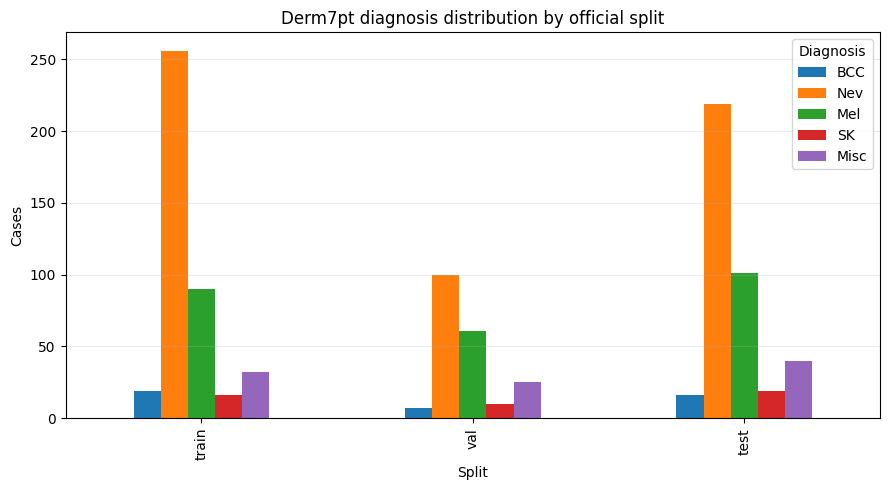

In [20]:
# 22. Dataset distributions and official split audit
split_counts = df["_split"].value_counts().reindex(["train", "val", "test"])
split_counts.to_csv(TABLE_DIR / "split_counts.csv")

diag_dist = pd.crosstab(df["_split"], df["diagnosis_id"]).reindex(
    index=["train", "val", "test"], columns=range(5), fill_value=0
)
diag_dist.columns = DIAG_NAMES
diag_dist.to_csv(TABLE_DIR / "diagnosis_distribution_by_split.csv")

print("Official split sizes:")
display(split_counts.to_frame("count"))

print("Diagnosis distribution:")
display(diag_dist)

fig, ax = plt.subplots(figsize=(9, 5))
diag_dist.plot(kind="bar", ax=ax)
ax.set_title("Derm7pt diagnosis distribution by official split")
ax.set_xlabel("Split")
ax.set_ylabel("Cases")
ax.legend(title="Diagnosis")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(PLOT_DIR / "01_diagnosis_distribution_by_split.png", dpi=220, bbox_inches="tight")
plt.show()

assert split_counts.tolist() == [413, 203, 395]


,PN,BWV,VS,PIG,STR,DaG,RS
split,,,,,,,
train,0.225182,0.179177,0.159806,0.280872,0.244552,0.418886,0.232446
val,0.216749,0.226601,0.197044,0.320197,0.275862,0.482759,0.251232
test,0.235443,0.189873,0.207595,0.313924,0.237975,0.448101,0.268354


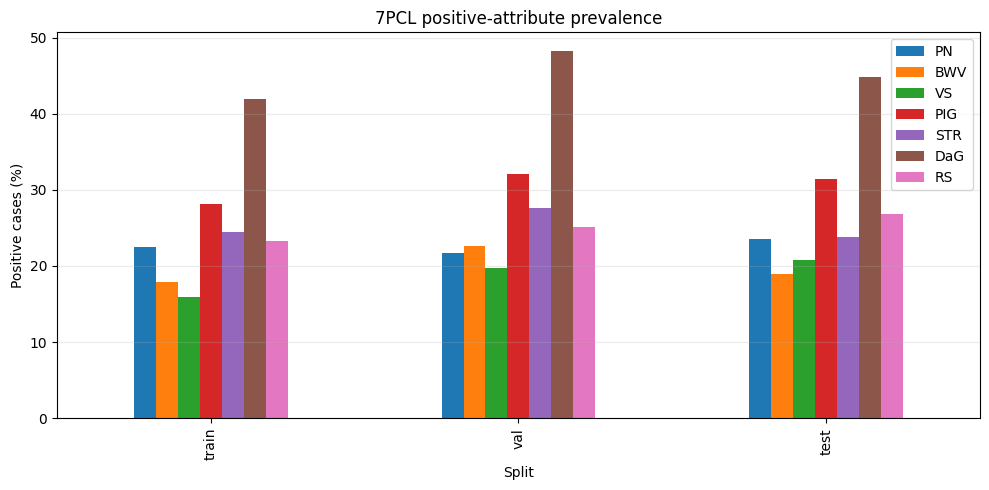

In [21]:
# 23. Convert the seven multiclass 7PCL annotations into the paper's binary clinical attributes
# The Wang et al. formulation uses a binary indicator vector for the seven checklist attributes.
# The mapping below follows the classical 7PCL positive criteria.

POSITIVE_RULES = {
    "PN": lambda s: str(s).strip().lower() == "atypical",
    "BWV": lambda s: str(s).strip().lower() == "present",
    "VS": lambda s: str(s).strip().lower() not in {"absent", "nan", "none", ""},
    "PIG": lambda s: str(s).strip().lower() == "diffuse irregular" or str(s).strip().lower() == "localized irregular",
    "STR": lambda s: str(s).strip().lower() == "irregular",
    "DaG": lambda s: str(s).strip().lower() == "irregular",
    "RS": lambda s: str(s).strip().lower() not in {"absent", "nan", "none", ""},
}

binary_7pcl = np.zeros((len(df), 7), dtype=np.float32)
for j, name in enumerate(CHECKLIST_COLUMNS.keys()):
    col = CHECKLIST_COLUMNS[name]
    binary_7pcl[:, j] = df[col].apply(POSITIVE_RULES[name]).astype(np.float32)

BINARY_NAMES = list(CHECKLIST_COLUMNS.keys())
binary_df = pd.DataFrame(binary_7pcl, columns=BINARY_NAMES)
binary_df["split"] = df["_split"].values
binary_prev = binary_df.groupby("split")[BINARY_NAMES].mean().reindex(["train", "val", "test"])
binary_prev.to_csv(TABLE_DIR / "7pcl_binary_prevalence.csv")

display(binary_prev)

fig, ax = plt.subplots(figsize=(10, 5))
(binary_prev * 100).plot(kind="bar", ax=ax)
ax.set_title("7PCL positive-attribute prevalence")
ax.set_xlabel("Split")
ax.set_ylabel("Positive cases (%)")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(PLOT_DIR / "02_7pcl_positive_prevalence.png", dpi=220, bbox_inches="tight")
plt.show()


In [22]:
# 24. Extract RemixFormer++ outputs while preserving the five 768-D Remix tokens
# The trained RemixFormer++ final feature is [global_clinical, local_clinical,
# global_dermoscopy, local_dermoscopy, metadata] = 5 x 768.

@torch.no_grad()
def extract_split(loader, split_name):
    model.eval()
    feats, tokens, diag_probs, diag_true, row_ids = [], [], [], [], []
    check_probs = {k: [] for k in CHECKLIST_SPECS}
    check_true = {k: [] for k in CHECKLIST_SPECS}
    check_mask = {k: [] for k in CHECKLIST_SPECS}

    for step, batch in enumerate(loader, 1):
        c = batch["clinical"].to(DEVICE, non_blocking=True)
        d = batch["dermoscopy"].to(DEVICE, non_blocking=True)
        m = batch["metadata"].to(DEVICE, non_blocking=True)
        outputs = model(c, d, m, capture=False)
        f = outputs["feature"].float()
        assert f.shape[-1] == 3840, f"Expected 3840-D Remix feature, got {tuple(f.shape)}"
        feats.append(f.cpu().numpy())
        tokens.append(f.reshape(f.shape[0], 5, 768).cpu().numpy())
        diag_probs.append(F.softmax(outputs["diagnosis"], dim=-1).float().cpu().numpy())
        diag_true.append(batch["diagnosis"].numpy())
        row_ids.append(batch["row_index"].numpy())
        for name, logits in outputs["checklist"].items():
            check_probs[name].append(F.softmax(logits, dim=-1).float().cpu().numpy())
            check_true[name].append(batch["checklist"][name].numpy())
            check_mask[name].append(batch["checklist_mask"][name].numpy())
        if step % 25 == 0 or step == len(loader):
            print(f"{split_name}: {step:4d}/{len(loader)}")

    result = {
        "feature": np.concatenate(feats),
        "tokens": np.concatenate(tokens),
        "diag_prob": np.concatenate(diag_probs),
        "diag_true": np.concatenate(diag_true),
        "row_id": np.concatenate(row_ids),
        "check_prob": {k: np.concatenate(v) for k, v in check_probs.items()},
        "check_true": {k: np.concatenate(v) for k, v in check_true.items()},
        "check_mask": {k: np.concatenate(v) for k, v in check_mask.items()},
    }
    np.save(ARRAY_DIR / f"{split_name}_remix_feature_3840.npy", result["feature"])
    np.save(ARRAY_DIR / f"{split_name}_remix_tokens_5x768.npy", result["tokens"])
    np.save(ARRAY_DIR / f"{split_name}_diagnosis_prob.npy", result["diag_prob"])
    np.save(ARRAY_DIR / f"{split_name}_diagnosis_true.npy", result["diag_true"])
    np.save(ARRAY_DIR / f"{split_name}_row_id.npy", result["row_id"])
    for k in CHECKLIST_SPECS:
        np.save(ARRAY_DIR / f"{split_name}_{k}_prob.npy", result["check_prob"][k])
        np.save(ARRAY_DIR / f"{split_name}_{k}_true.npy", result["check_true"][k])
        np.save(ARRAY_DIR / f"{split_name}_{k}_mask.npy", result["check_mask"][k])
    return result

extracted = {s: extract_split(loader, s) for s, loader in
             [("train", train_loader), ("val", val_loader), ("test", test_loader)]}
print({s: (v["feature"].shape, v["tokens"].shape) for s,v in extracted.items()})


train:   25/413
train:   50/413
train:   75/413
train:  100/413
train:  125/413
train:  150/413
train:  175/413
train:  200/413
train:  225/413
train:  250/413
train:  275/413
train:  300/413
train:  325/413
train:  350/413
train:  375/413
train:  400/413
train:  413/413
val:   25/203
val:   50/203
val:   75/203
val:  100/203
val:  125/203
val:  150/203
val:  175/203
val:  200/203
val:  203/203
test:   25/395
test:   50/395
test:   75/395
test:  100/395
test:  125/395
test:  150/395
test:  175/395
test:  200/395
test:  225/395
test:  250/395
test:  275/395
test:  300/395
test:  325/395
test:  350/395
test:  375/395
test:  395/395
{'train': ((413, 3840), (413, 5, 768)), 'val': ((203, 3840), (203, 5, 768)), 'test': ((395, 3840), (395, 5, 768))}


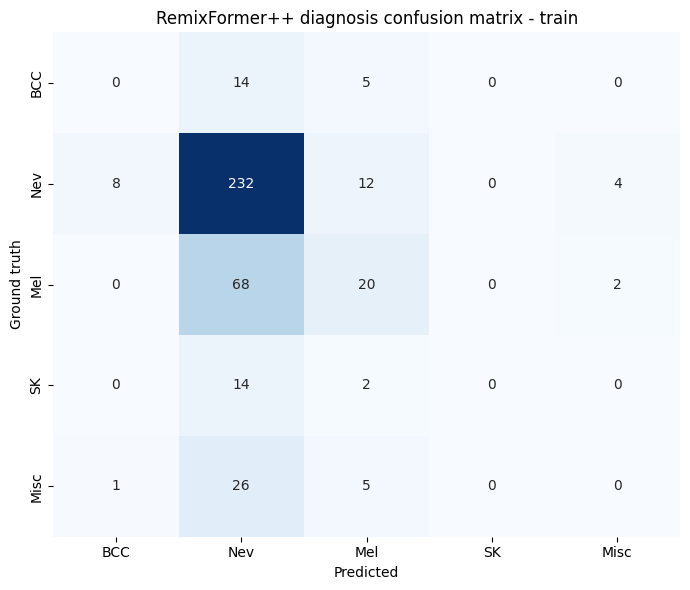

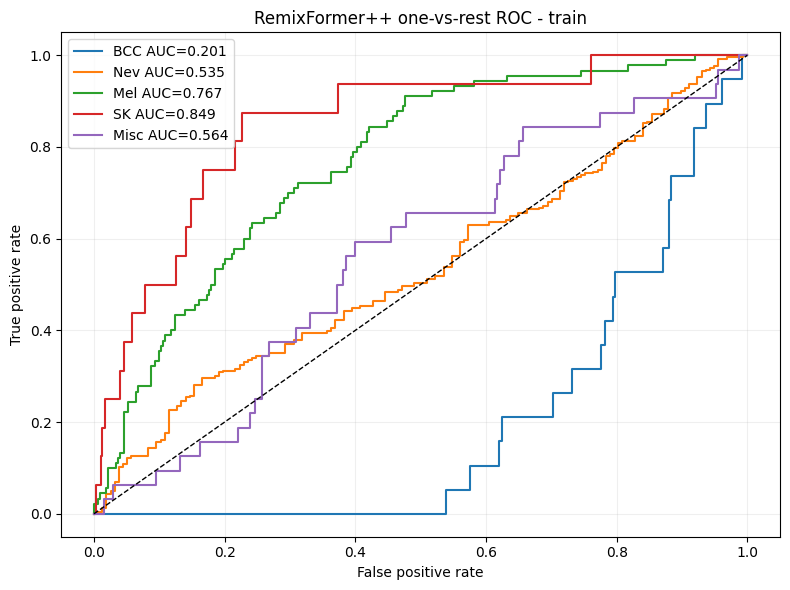

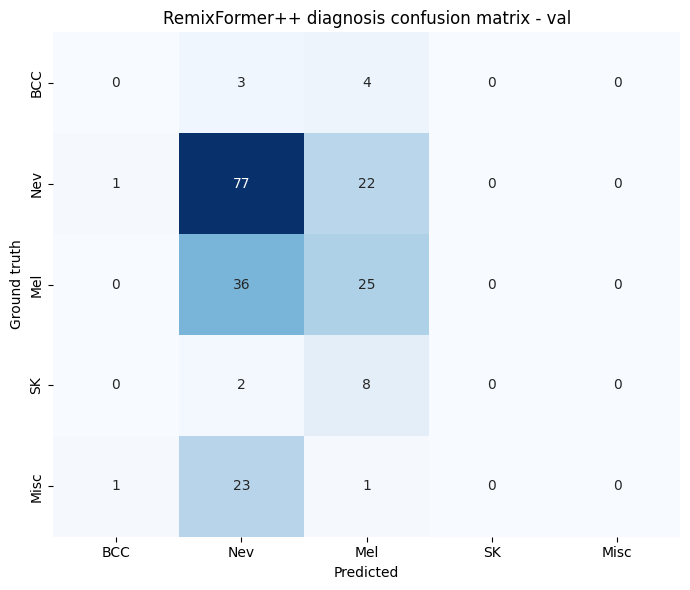

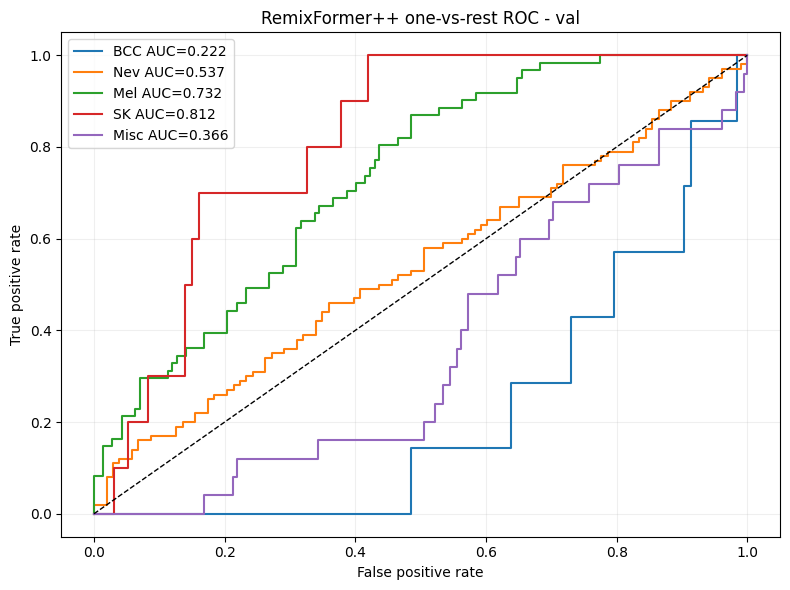

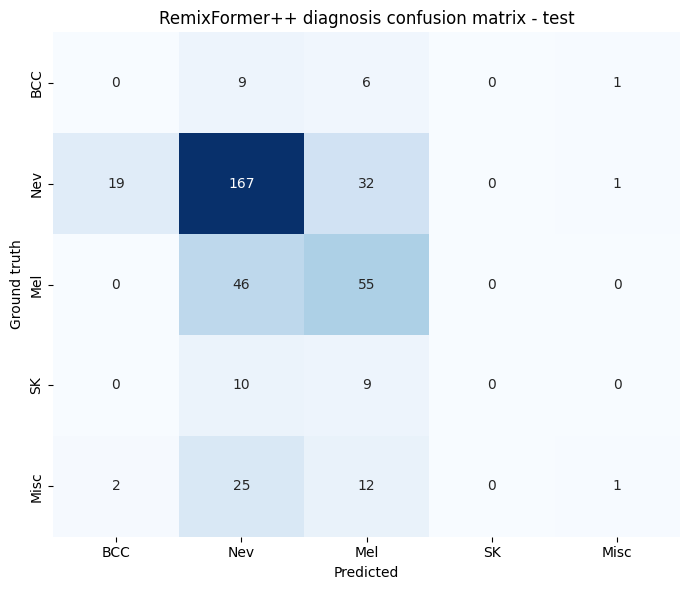

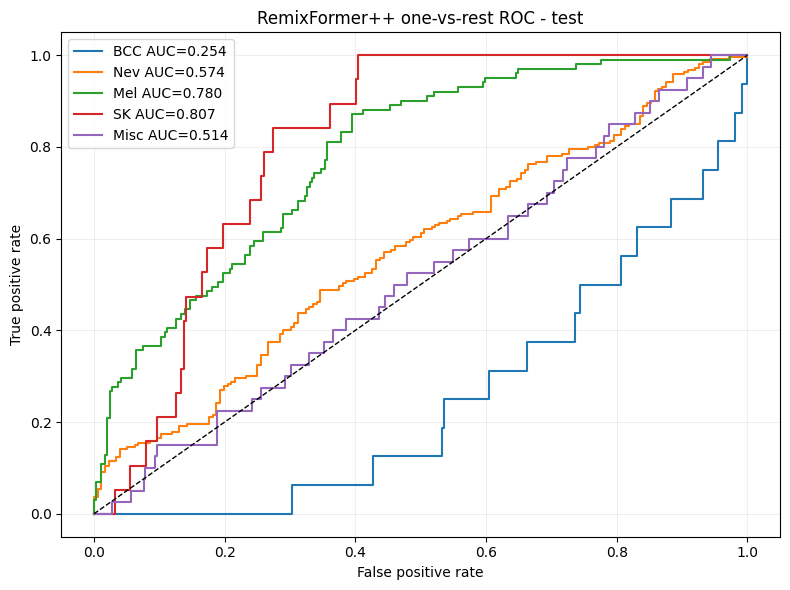

,split,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,macro_specificity,macro_auc_ovr
0,train,0.610169,0.225694,0.221983,0.225694,0.211833,0.536546,0.822007,0.582954
1,val,0.502463,0.235967,0.192553,0.235967,0.210445,0.438951,0.824392,0.533619
2,test,0.564557,0.266422,0.293119,0.266422,0.251964,0.524564,0.845383,0.586013


In [23]:
# 25. Baseline RemixFormer++ diagnosis metrics, confusion matrix, ROC and PR
def multiclass_specificity(cm):
    specs = []
    for i in range(cm.shape[0]):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - tp - fn - fp
        specs.append(tn / (tn + fp) if (tn + fp) else np.nan)
    return np.asarray(specs)

def save_multiclass_metrics(split_name, result):
    y = result["diag_true"]
    p = result["diag_prob"]
    pred = p.argmax(1)
    cm = confusion_matrix(y, pred, labels=np.arange(5))
    spec = multiclass_specificity(cm)

    row = {
        "split": split_name,
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "macro_precision": precision_score(y, pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y, pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y, pred, average="weighted", zero_division=0),
        "macro_specificity": np.nanmean(spec),
        "macro_auc_ovr": roc_auc_score(y, p, multi_class="ovr"),
    }
    pd.DataFrame([row]).to_csv(TABLE_DIR / f"{split_name}_remix_diagnosis_metrics.csv", index=False)

    cm_df = pd.DataFrame(cm, index=DIAG_NAMES, columns=DIAG_NAMES)
    cm_df.to_csv(TABLE_DIR / f"{split_name}_remix_confusion_matrix.csv")

    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"RemixFormer++ diagnosis confusion matrix - {split_name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Ground truth")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"03_{split_name}_remix_confusion_matrix.png", dpi=220, bbox_inches="tight")
    plt.show()

    # One-vs-rest ROC and PR
    y_bin = label_binarize(y, classes=np.arange(5))
    fig, ax = plt.subplots(figsize=(8, 6))
    for i, name in enumerate(DIAG_NAMES):
        fpr, tpr, _ = roc_curve(y_bin[:, i], p[:, i])
        auc = roc_auc_score(y_bin[:, i], p[:, i])
        ax.plot(fpr, tpr, label=f"{name} AUC={auc:.3f}")
    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set_title(f"RemixFormer++ one-vs-rest ROC - {split_name}")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"04_{split_name}_remix_multiclass_roc.png", dpi=220, bbox_inches="tight")
    plt.show()

    return row

baseline_rows = [save_multiclass_metrics(s, extracted[s]) for s in ["train", "val", "test"]]
display(pd.DataFrame(baseline_rows))


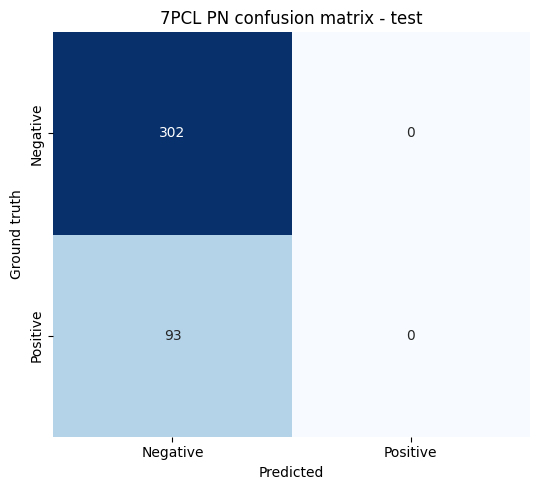

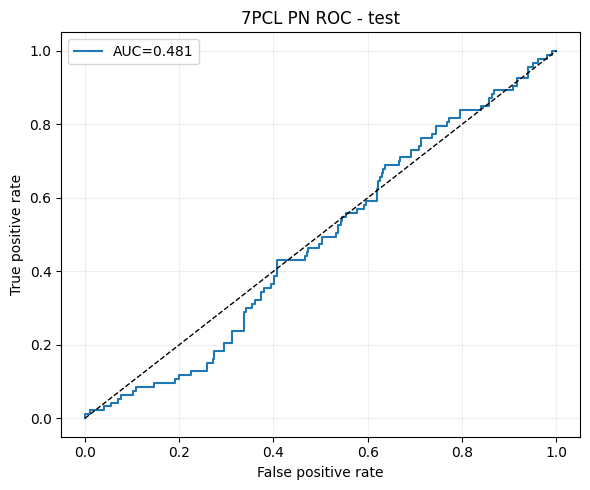

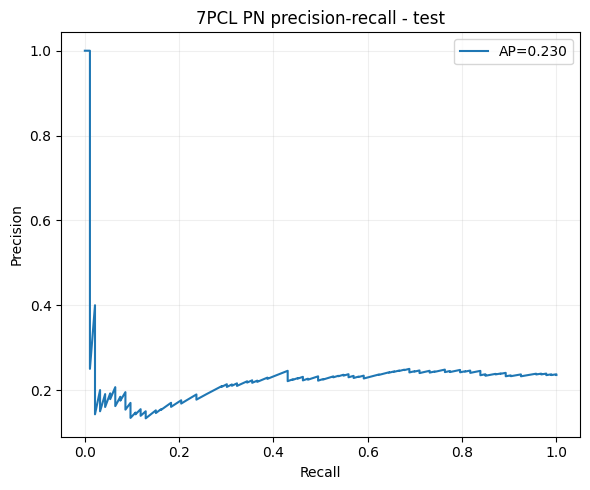

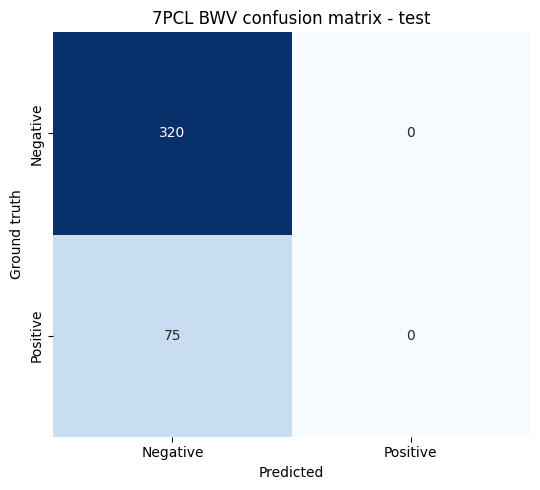

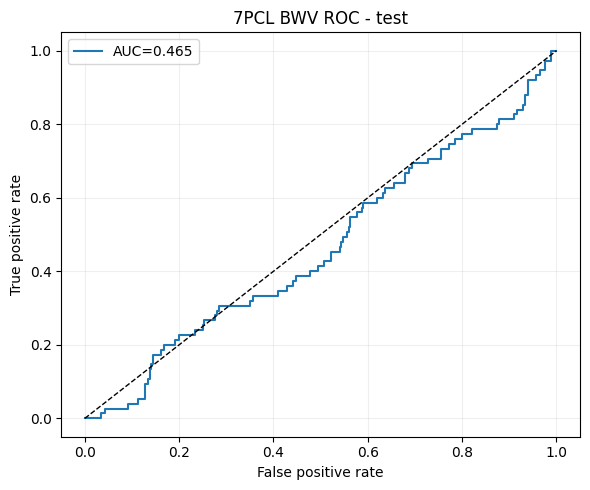

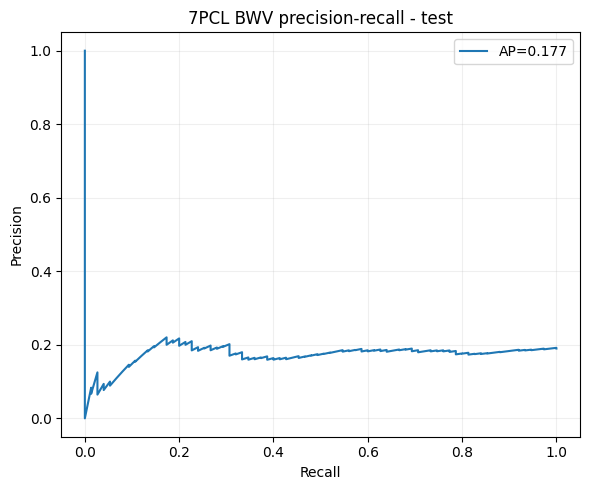

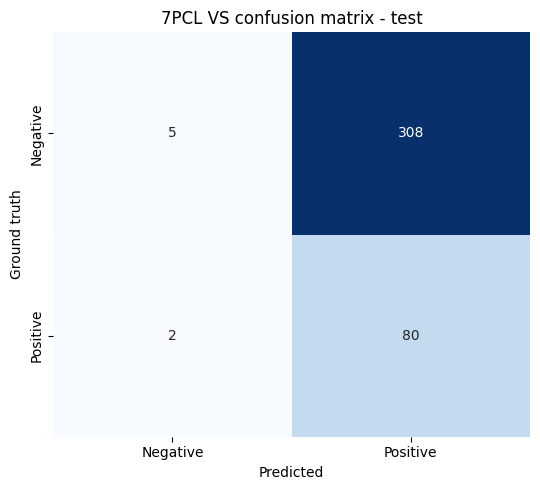

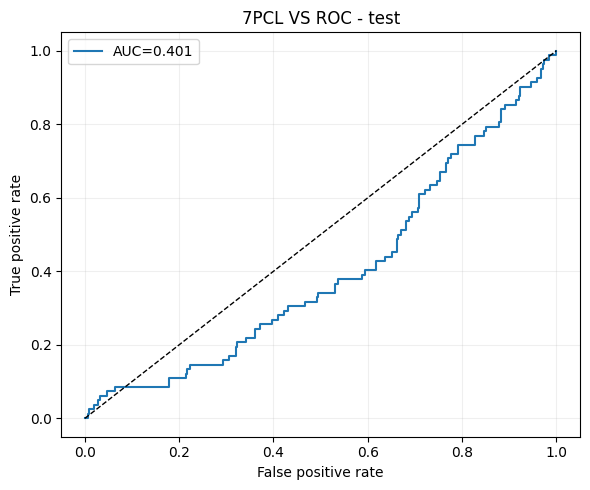

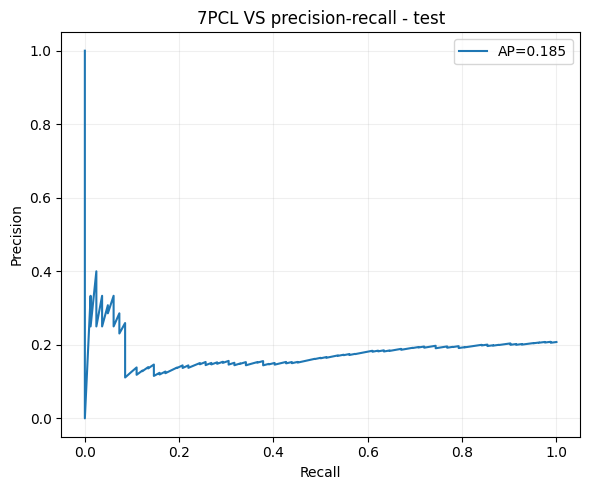

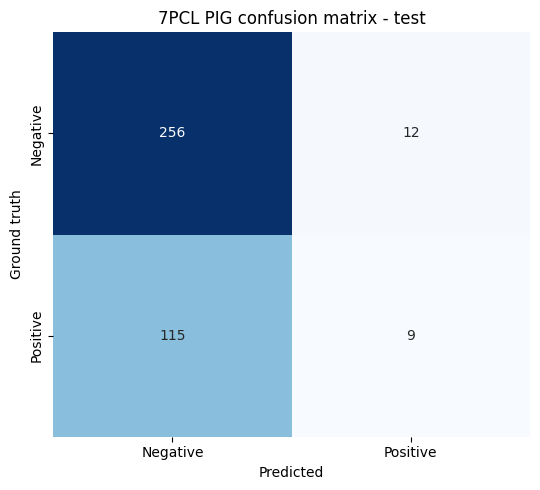

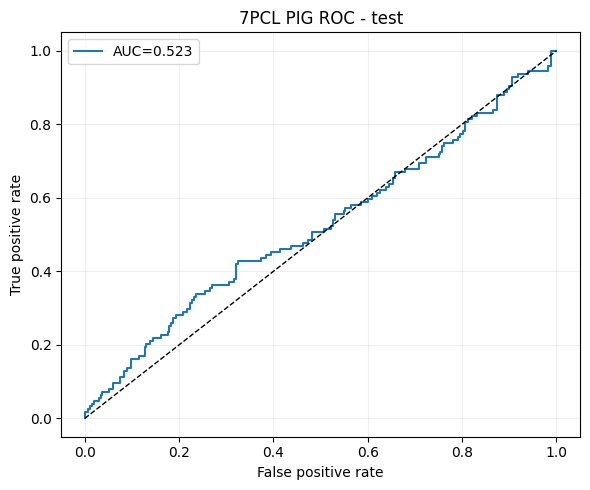

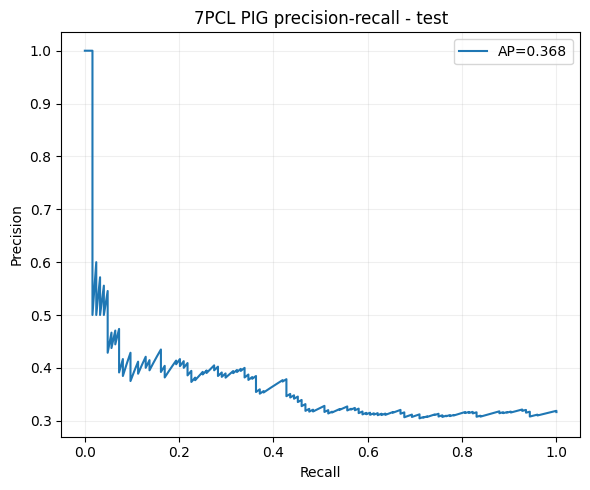

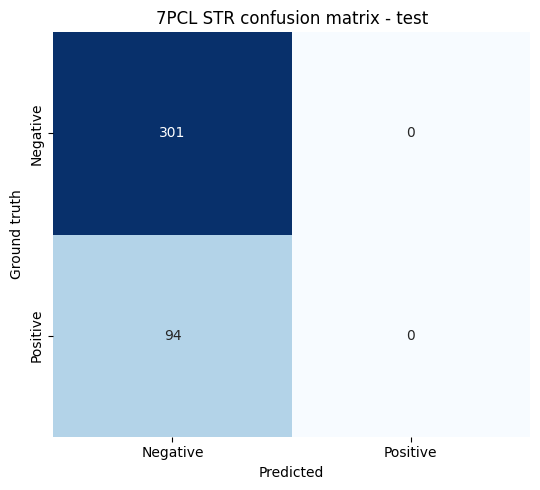

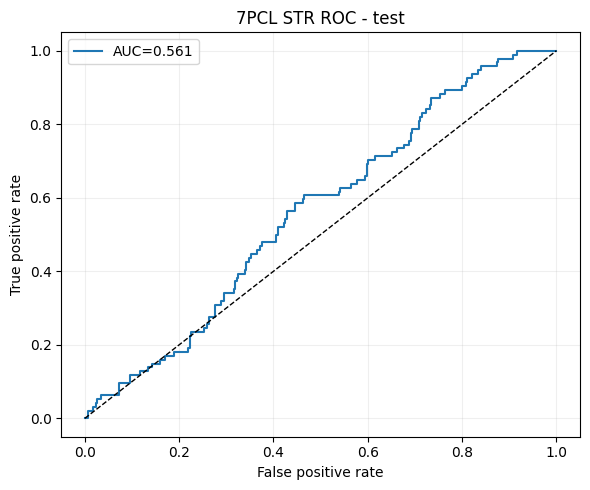

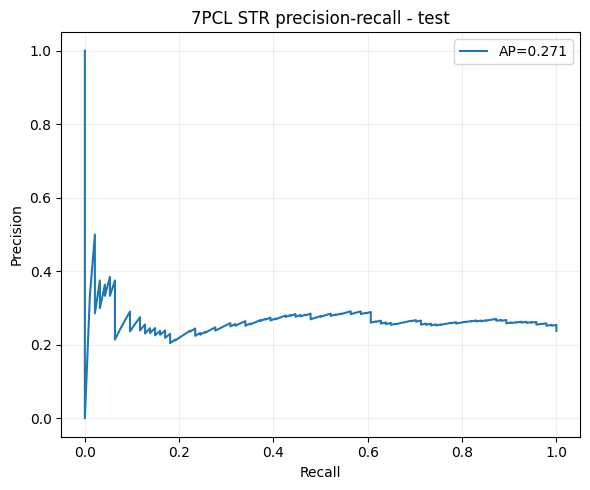

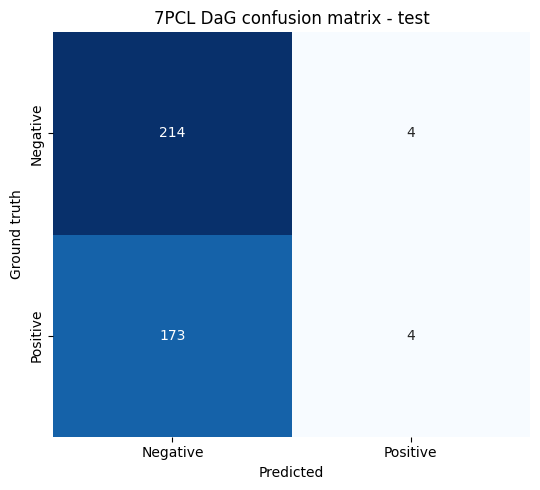

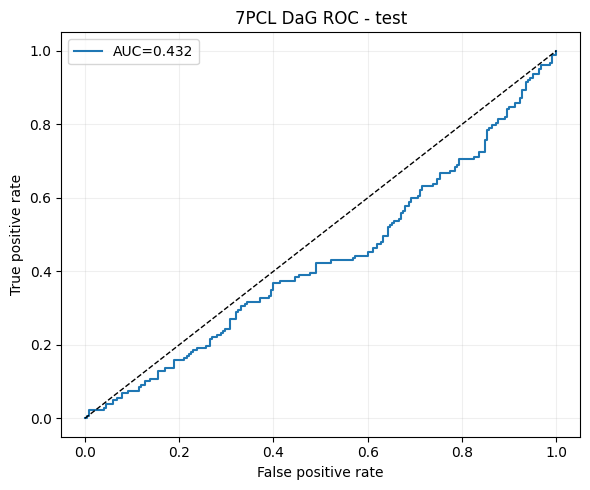

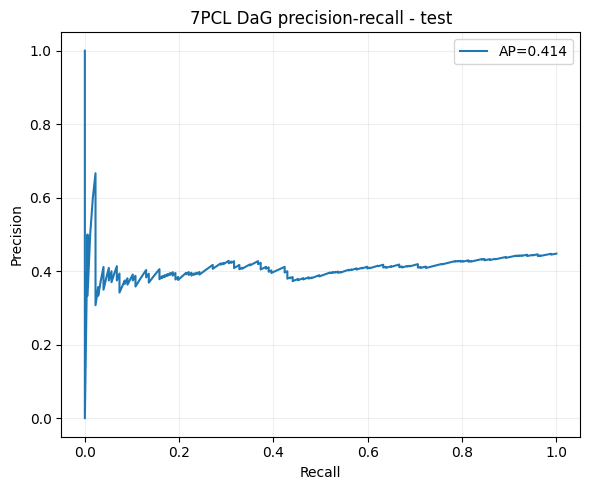

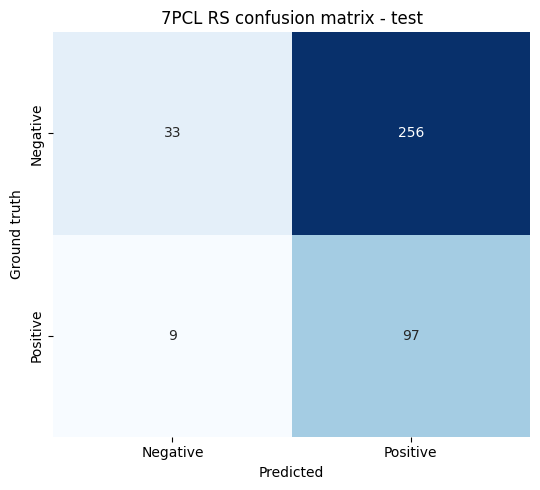

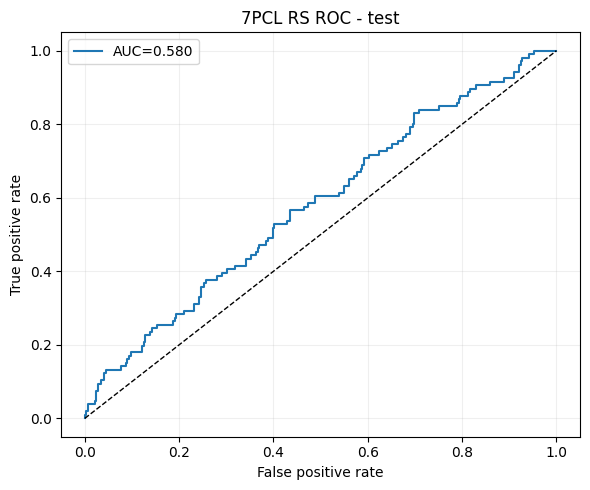

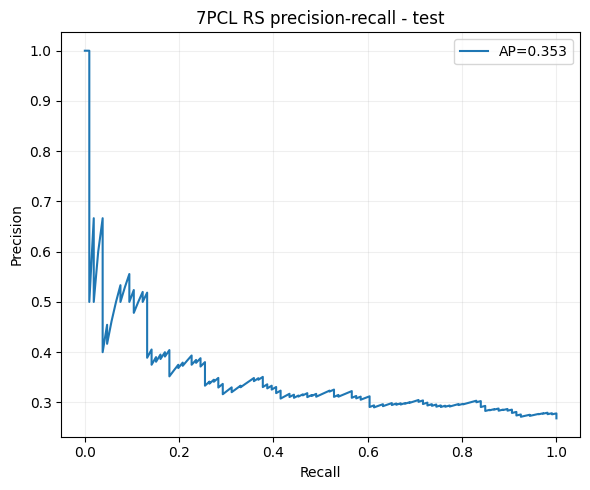

,n,accuracy,precision,recall_sensitivity,specificity,f1,auroc,auprc,tn,fp,fn,tp,split,attribute
0,413,0.774818,0.000000,0.000000,1.000000,0.000000,0.442305,0.189958,320,0,93,0,train,PN
1,413,0.820823,0.000000,0.000000,1.000000,0.000000,0.510404,0.172046,339,0,74,0,train,BWV
2,413,0.176755,0.157500,0.954545,0.028818,0.270386,0.422845,0.144110,10,337,3,63,train,VS
3,413,0.723971,0.666667,0.034483,0.993266,0.065574,0.520347,0.325888,295,2,112,4,train,PIG
4,413,0.755448,0.000000,0.000000,1.000000,0.000000,0.638709,0.338490,312,0,101,0,train,STR
5,413,0.537530,0.125000,0.017341,0.912500,0.030457,0.391305,0.350284,219,21,170,3,train,DaG
6,413,0.259080,0.233503,0.958333,0.047319,0.375510,0.635712,0.352448,15,302,4,92,train,RS
7,203,0.783251,0.000000,0.000000,1.000000,0.000000,0.389937,0.171772,159,0,44,0,val,PN
8,203,0.773399,0.000000,0.000000,1.000000,0.000000,0.483107,0.216035,157,0,46,0,val,BWV
9,203,0.197044,0.194030,0.975000,0.006135,0.323651,0.414110,0.172731,1,162,1,39,val,VS


In [24]:
# 26. Seven 7PCL prediction metrics and ROC/PR curves from the trained RemixFormer++ heads
def binary_metrics(y, p, mask):
    keep = mask > 0
    y = y[keep].astype(int)
    p = p[keep]
    pred = (p >= 0.5).astype(int)
    cm = confusion_matrix(y, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn) if tp + fn else np.nan
    spec = tn / (tn + fp) if tn + fp else np.nan
    return {
        "n": len(y),
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall_sensitivity": sens,
        "specificity": spec,
        "f1": f1_score(y, pred, zero_division=0),
        "auroc": roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan,
        "auprc": average_precision_score(y, p) if len(np.unique(y)) == 2 else np.nan,
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    }

all_rows = []
for split_name in ["train", "val", "test"]:
    r = extracted[split_name]
    for name in CHECKLIST_SPECS:
        # Convert the multiclass Remix head into the classical binary 7PCL probability.
        classes = CHECKLIST_SPECS[name]["classes"]
        probs = r["check_prob"][name]
        pos_idx = []
        for idx, cls in enumerate(classes):
            positive = POSITIVE_RULES[name](cls)
            if positive:
                pos_idx.append(idx)
        p_pos = probs[:, pos_idx].sum(axis=1) if pos_idx else np.zeros(len(probs))
        m = r["check_mask"][name]
        y_binary = np.array([1 if POSITIVE_RULES[name](classes[int(t)]) else 0 if int(t) >= 0 else 0 for t in r["check_true"][name]])
        valid = r["check_true"][name] >= 0
        m = m * valid.astype(np.float32)

        met = binary_metrics(y_binary, p_pos, m)
        met.update({"split": split_name, "attribute": name})
        all_rows.append(met)

        if split_name == "test":
            keep = m > 0
            yv, pv = y_binary[keep], p_pos[keep]
            pred = (pv >= 0.5).astype(int)
            cm = confusion_matrix(yv, pred, labels=[0, 1])
            cm_df = pd.DataFrame(cm, index=["Negative", "Positive"], columns=["Negative", "Positive"])
            cm_df.to_csv(TABLE_DIR / f"test_7pcl_{name}_confusion_matrix.csv")

            fig, ax = plt.subplots(figsize=(5.5, 5))
            sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
            ax.set_title(f"7PCL {name} confusion matrix - test")
            ax.set_xlabel("Predicted")
            ax.set_ylabel("Ground truth")
            fig.tight_layout()
            fig.savefig(PLOT_DIR / f"05_test_7pcl_{name}_confusion_matrix.png", dpi=220, bbox_inches="tight")
            plt.show()

            if len(np.unique(yv)) == 2:
                fpr, tpr, _ = roc_curve(yv, pv)
                precision, recall, _ = precision_recall_curve(yv, pv)
                auc = roc_auc_score(yv, pv)
                ap = average_precision_score(yv, pv)

                fig, ax = plt.subplots(figsize=(6, 5))
                ax.plot(fpr, tpr, label=f"AUC={auc:.3f}")
                ax.plot([0,1], [0,1], "k--", linewidth=1)
                ax.set_title(f"7PCL {name} ROC - test")
                ax.set_xlabel("False positive rate")
                ax.set_ylabel("True positive rate")
                ax.legend()
                ax.grid(alpha=0.2)
                fig.tight_layout()
                fig.savefig(PLOT_DIR / f"06_test_7pcl_{name}_roc.png", dpi=220, bbox_inches="tight")
                plt.show()

                fig, ax = plt.subplots(figsize=(6, 5))
                ax.plot(recall, precision, label=f"AP={ap:.3f}")
                ax.set_title(f"7PCL {name} precision-recall - test")
                ax.set_xlabel("Recall")
                ax.set_ylabel("Precision")
                ax.legend()
                ax.grid(alpha=0.2)
                fig.tight_layout()
                fig.savefig(PLOT_DIR / f"07_test_7pcl_{name}_pr.png", dpi=220, bbox_inches="tight")
                plt.show()

metrics_7pcl_df = pd.DataFrame(all_rows)
metrics_7pcl_df.to_csv(TABLE_DIR / "7pcl_binary_metrics_all_splits.csv", index=False)
display(metrics_7pcl_df)


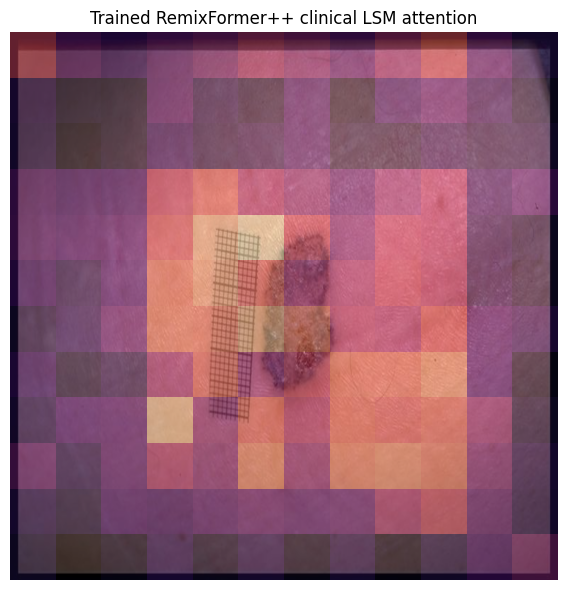

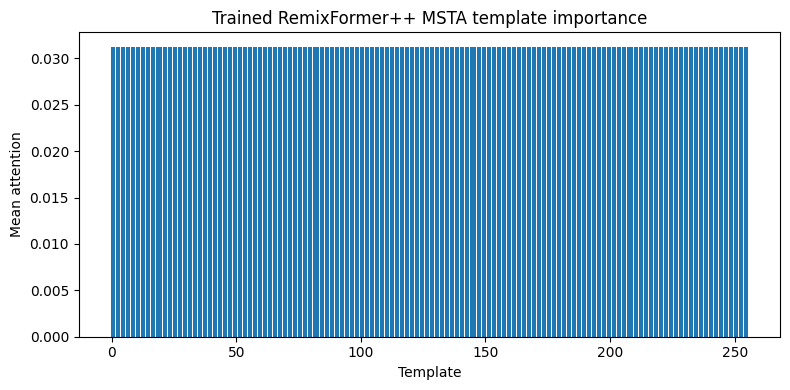

Saved trained-model attention audit.


In [25]:
# 27. Save one publication-style intermediate RemixFormer++ attention audit
# This is performed only after restoring the trained checkpoint.

sample = test_ds[0]
with torch.no_grad():
    sample_out = model(
        sample["clinical"].unsqueeze(0).to(DEVICE),
        sample["dermoscopy"].unsqueeze(0).to(DEVICE),
        sample["metadata"].unsqueeze(0).to(DEVICE),
        capture=True
    )

# Clinical LSM
clinical_img = sample["clinical"].permute(1,2,0).numpy()
clinical_img = np.clip(clinical_img, 0, 1)
lsm = sample_out["clinical"]["lsm_score"][0].detach().cpu().numpy()

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(clinical_img)
ax.imshow(lsm, cmap="magma", alpha=0.45, extent=(0, clinical_img.shape[1], clinical_img.shape[0], 0))
ax.set_title("Trained RemixFormer++ clinical LSM attention")
ax.axis("off")
fig.tight_layout()
fig.savefig(AUDIT_DIR / "trained_clinical_lsm_attention.png", dpi=220, bbox_inches="tight")
plt.show()

# MSTA weights
msta = sample_out["dermoscopy"]["msta_weights"][0].detach().cpu().numpy()
msta_mean = msta.mean(axis=(0, 2))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(np.arange(len(msta_mean)), msta_mean)
ax.set_title("Trained RemixFormer++ MSTA template importance")
ax.set_xlabel("Template")
ax.set_ylabel("Mean attention")
fig.tight_layout()
fig.savefig(AUDIT_DIR / "trained_msta_template_importance.png", dpi=220, bbox_inches="tight")
plt.show()

np.save(AUDIT_DIR / "sample_lsm_score.npy", lsm)
np.save(AUDIT_DIR / "sample_msta_weights.npy", msta)
json.dump(
    {
        "row_id": int(sample["row_index"]),
        "diagnosis_probabilities": F.softmax(sample_out["diagnosis"], dim=-1)[0].cpu().numpy().tolist(),
        "checklist_probabilities": {
            k: F.softmax(v, dim=-1)[0].cpu().numpy().tolist()
            for k, v in sample_out["checklist"].items()
        }
    },
    open(AUDIT_DIR / "sample_prediction_audit.json", "w"),
    indent=2
)
print("Saved trained-model attention audit.")



# Corrected five-class CKTG graph

This downstream section replaces the original melanoma-only graph. It uses **12 nodes**:

- Seven 7PCL attributes: `PN, BWV, VS, PIG, STR, DaG, RS`
- Five diagnosis classes: `BCC, Nev, Mel, SK, Misc`

All graph statistics are estimated from the **official training split only**. The original paper's melanoma-centered external graph is extended here to a five-class diagnosis graph as a clearly identified research modification.



## Downstream configuration

The pretrained RemixFormer++ checkpoint is frozen initially. The trainable downstream model contains:

1. BERT/deterministic semantic node features;
2. 12-node directed graph;
3. ARFP proximity matrices `P(0)...P(K)`;
4. multi-order graph convolution;
5. graph-conditioned feature fusion;
6. GD-DDW-style trainable channel and attribute weights;
7. five-class diagnosis head;
8. seven-point multilabel head;
9. validation-tuned reliability-gated heuristic;
10. complete JSON/CSV/NPY/PNG/PDF/model export.


In [26]:

# 29A. Corrected five-class downstream configuration
import os, json, math, time, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report, roc_auc_score
)

CLASS_NAMES = ["BCC", "Nev", "Mel", "SK", "Misc"]
ATTR_NAMES = ["PN", "BWV", "VS", "PIG", "STR", "DaG", "RS"]
GRAPH_NODES = ATTR_NAMES + CLASS_NAMES
NUM_ATTR = len(ATTR_NAMES)
NUM_CLASSES = len(CLASS_NAMES)
NUM_NODES = len(GRAPH_NODES)
GRAPH_K = int(globals().get("GRAPH_K", 3))
GRAPH_HIDDEN = 256
DOWNSTREAM_EPOCHS = int(globals().get("GD_EPOCHS", 30))
DOWNSTREAM_LR = float(globals().get("GD_LR", 1e-4))
DOWNSTREAM_WD = float(globals().get("GD_WEIGHT_DECAY", 1e-4))
# Non-zero heuristic calibration:
# Zero is intentionally excluded because the project requires the graph-integrated
# heuristic to contribute to the final decision. The selected value is still chosen
# from validation macro-F1 among positive lambda values.
MIN_HEURISTIC_LAMBDA = 0.10
MAX_HEURISTIC_LAMBDA = 2.00
HEURISTIC_LAMBDA_GRID = np.linspace(MIN_HEURISTIC_LAMBDA, MAX_HEURISTIC_LAMBDA, 20)

ROOT = Path(globals().get("DOWNSTREAM_ROOT", Path("/kaggle/working/remixformerpp_7pcl_corrected_5class")))
PLOT_DIR, TABLE_DIR, ARRAY_DIR, GRAPH_DIR, AUDIT_DIR, CKPT_DIR = [ROOT/x for x in ["plots","tables","arrays","graphs","intermediate_audit","checkpoints"]]
for p in [ROOT,PLOT_DIR,TABLE_DIR,ARRAY_DIR,GRAPH_DIR,AUDIT_DIR,CKPT_DIR]: p.mkdir(parents=True, exist_ok=True)

print("Corrected graph:", NUM_NODES, "nodes")
print(GRAPH_NODES)
print("Output root:", ROOT)


Corrected graph: 12 nodes
['PN', 'BWV', 'VS', 'PIG', 'STR', 'DaG', 'RS', 'BCC', 'Nev', 'Mel', 'SK', 'Misc']
Output root: /kaggle/working/remixformerpp_7pcl_paper_aligned


In [27]:

# 29B. Build aligned labels from the extracted row IDs
# This uses only the official dataframe and preserves the extracted ordering.
def aligned_targets(split_name):
    ids = extracted[split_name]["row_id"].astype(int)
    y_diag = df.loc[ids, "diagnosis_id"].to_numpy().astype(int)
    y_attr = binary_7pcl[ids].astype(np.float32)
    return ids, y_diag, y_attr

TARGETS = {}
for split in ["train", "val", "test"]:
    ids, y_diag, y_attr = aligned_targets(split)
    TARGETS[split] = {"row_id": ids, "y_diag": y_diag, "y_attr": y_attr}
    np.save(ARRAY_DIR/f"{split}_diagnosis_targets.npy", y_diag)
    np.save(ARRAY_DIR/f"{split}_7pcl_binary_targets.npy", y_attr)
    print(split, "diagnosis", y_diag.shape, "attributes", y_attr.shape)


train diagnosis (413,) attributes (413, 7)
val diagnosis (203,) attributes (203, 7)
test diagnosis (395,) attributes (395, 7)


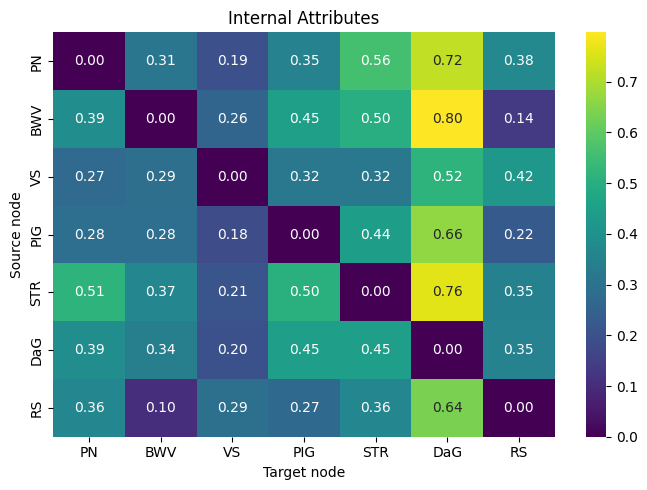

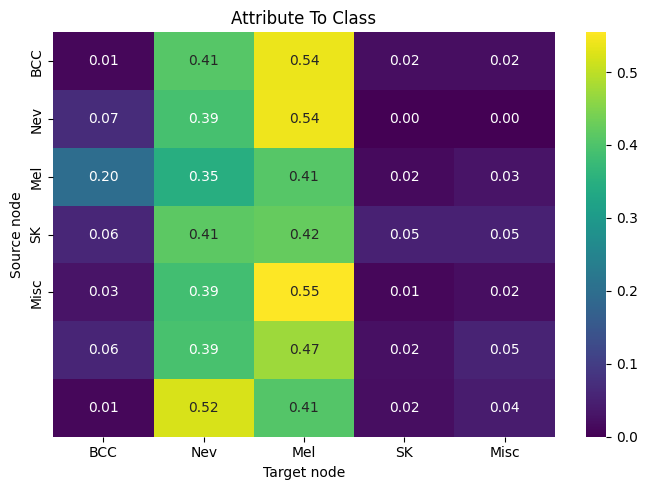

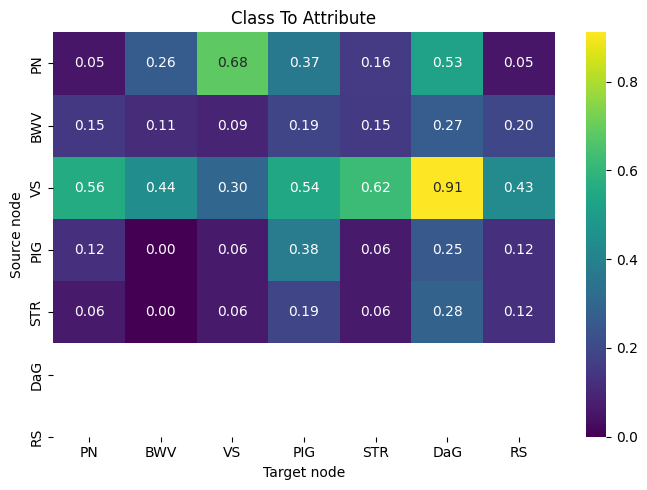

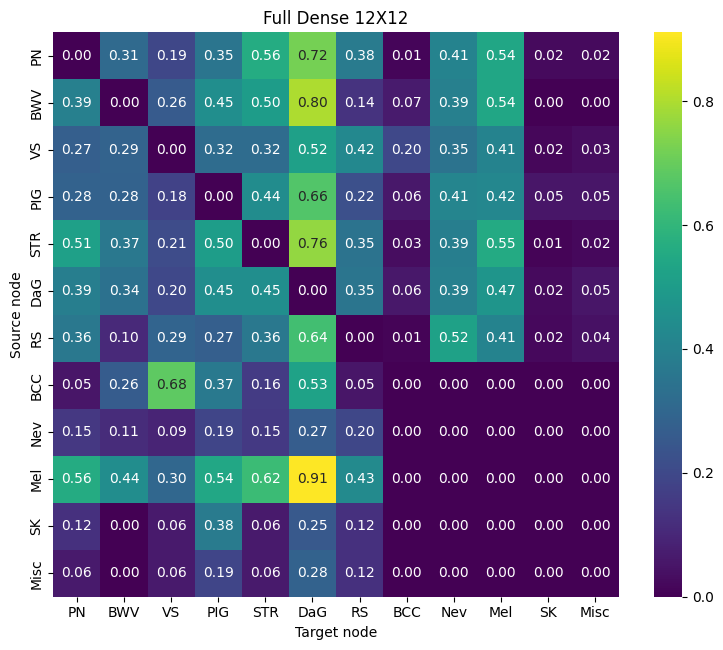

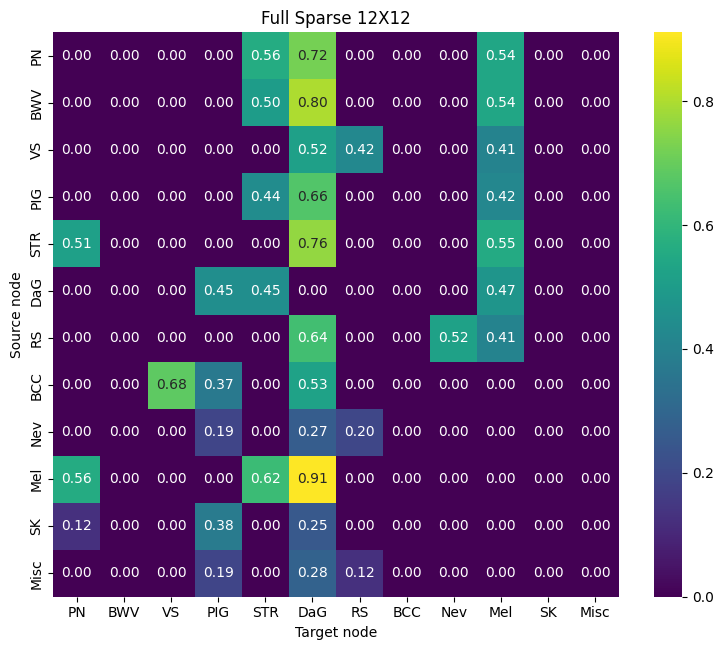

A_full: (12, 12) A_sparse: (12, 12)


,PN,BWV,VS,PIG,STR,DaG,RS,BCC,Nev,Mel,SK,Misc
PN,0.0000,0.3118,0.1935,0.3548,0.5591,0.7204,0.3763,0.0108,0.4086,0.5376,0.0215,0.0215
BWV,0.3919,0.0000,0.2568,0.4459,0.5000,0.7973,0.1351,0.0676,0.3919,0.5405,0.0000,0.0000
VS,0.2727,0.2879,0.0000,0.3182,0.3182,0.5152,0.4242,0.1970,0.3485,0.4091,0.0152,0.0303
PIG,0.2845,0.2845,0.1810,0.0000,0.4397,0.6638,0.2241,0.0603,0.4138,0.4224,0.0517,0.0517
STR,0.5149,0.3663,0.2079,0.5050,0.0000,0.7624,0.3465,0.0297,0.3861,0.5545,0.0099,0.0198
DaG,0.3873,0.3410,0.1965,0.4451,0.4451,0.0000,0.3526,0.0578,0.3931,0.4740,0.0231,0.0520
RS,0.3646,0.1042,0.2917,0.2708,0.3646,0.6354,0.0000,0.0104,0.5208,0.4062,0.0208,0.0417
BCC,0.0526,0.2632,0.6842,0.3684,0.1579,0.5263,0.0526,0.0000,0.0000,0.0000,0.0000,0.0000
Nev,0.1484,0.1133,0.0898,0.1875,0.1523,0.2656,0.1953,0.0000,0.0000,0.0000,0.0000,0.0000
Mel,0.5556,0.4444,0.3000,0.5444,0.6222,0.9111,0.4333,0.0000,0.0000,0.0000,0.0000,0.0000


In [28]:

# 29C. Five-class graph statistics from TRAIN ONLY
# Internal attribute edge: P(attribute_q=1 | attribute_p=1)
# Attribute -> class: P(class=c | attribute_p=1)
# Class -> attribute: P(attribute_p=1 | class=c)

def safe_conditional(num, den):
    return float(num / den) if den > 0 else 0.0

train_attr = TARGETS["train"]["y_attr"].astype(int)
train_diag = TARGETS["train"]["y_diag"]
A_internal = np.zeros((NUM_ATTR, NUM_ATTR), dtype=np.float64)
for p in range(NUM_ATTR):
    den = train_attr[:, p].sum()
    for q in range(NUM_ATTR):
        if p != q:
            A_internal[p, q] = safe_conditional(np.logical_and(train_attr[:,p]==1, train_attr[:,q]==1).sum(), den)

A_attr_to_class = np.zeros((NUM_ATTR, NUM_CLASSES), dtype=np.float64)
A_class_to_attr = np.zeros((NUM_CLASSES, NUM_ATTR), dtype=np.float64)
for c in range(NUM_CLASSES):
    class_mask = train_diag == c
    class_count = class_mask.sum()
    for p in range(NUM_ATTR):
        attr_count = train_attr[:,p].sum()
        both = np.logical_and(train_attr[:,p]==1, train_diag==c).sum()
        A_attr_to_class[p,c] = safe_conditional(both, attr_count)
        A_class_to_attr[c,p] = safe_conditional(train_attr[class_mask,p].sum(), class_count)

A_full = np.zeros((NUM_NODES, NUM_NODES), dtype=np.float64)
A_full[:NUM_ATTR,:NUM_ATTR] = A_internal
A_full[:NUM_ATTR,NUM_ATTR:] = A_attr_to_class
A_full[NUM_ATTR:,:NUM_ATTR] = A_class_to_attr

# Keep the strongest outgoing edges while preserving at least one edge where possible.
def sparsify_outgoing(A, min_edges=1, max_edges=3):
    S = np.zeros_like(A)
    for i in range(A.shape[0]):
        candidates = [(j,float(A[i,j])) for j in range(A.shape[1]) if i != j and A[i,j] > 0]
        candidates.sort(key=lambda x:x[1], reverse=True)
        if candidates:
            keep_n = min(max_edges, max(min_edges, len(candidates)))
            for j,w in candidates[:keep_n]: S[i,j] = w
    return S

A_sparse = sparsify_outgoing(A_full, int(globals().get("MIN_EDGES_PER_NODE",1)), int(globals().get("MAX_EDGES_PER_NODE",3)))

for name, arr, labels in [
    ("internal_attributes", A_internal, ATTR_NAMES),
    ("attribute_to_class", A_attr_to_class, [*CLASS_NAMES]),
    ("class_to_attribute", A_class_to_attr, ATTR_NAMES),
    ("full_dense_12x12", A_full, GRAPH_NODES),
    ("full_sparse_12x12", A_sparse, GRAPH_NODES),
]:
    np.save(GRAPH_DIR/f"{name}.npy", arr)
    pd.DataFrame(arr).to_csv(GRAPH_DIR/f"{name}.csv", index=False)
    plt.figure(figsize=(max(7, len(arr)*0.65), max(5, len(arr)*0.55)))
    sns.heatmap(arr, annot=True, fmt=".2f", cmap="viridis", xticklabels=(CLASS_NAMES if name=="attribute_to_class" else labels), yticklabels=labels)
    plt.title(name.replace("_"," ").title())
    plt.xlabel("Target node"); plt.ylabel("Source node"); plt.tight_layout()
    plt.savefig(PLOT_DIR/f"graph_{name}.png", dpi=220); plt.show()

print("A_full:", A_full.shape, "A_sparse:", A_sparse.shape)
display(pd.DataFrame(A_full, index=GRAPH_NODES, columns=GRAPH_NODES).round(4))


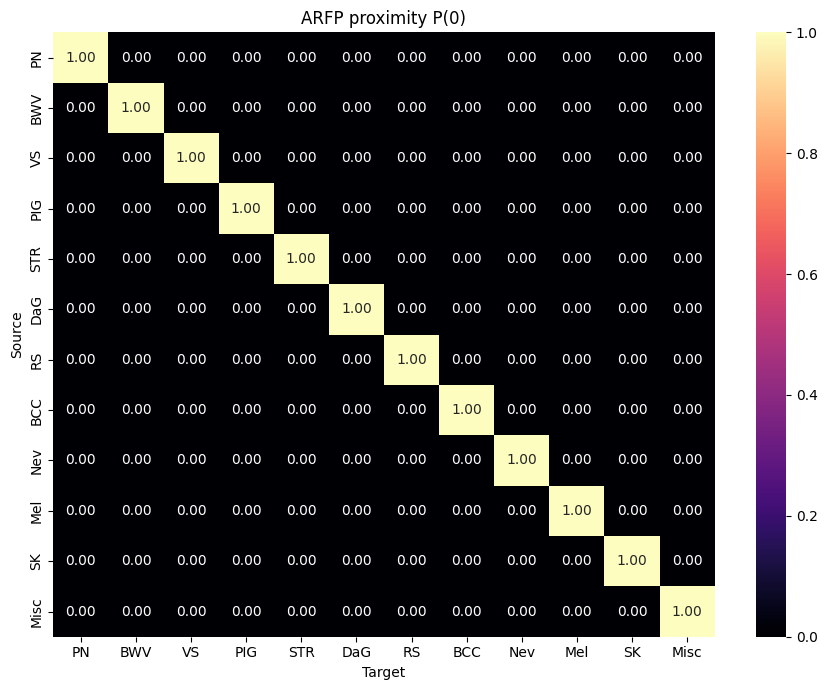

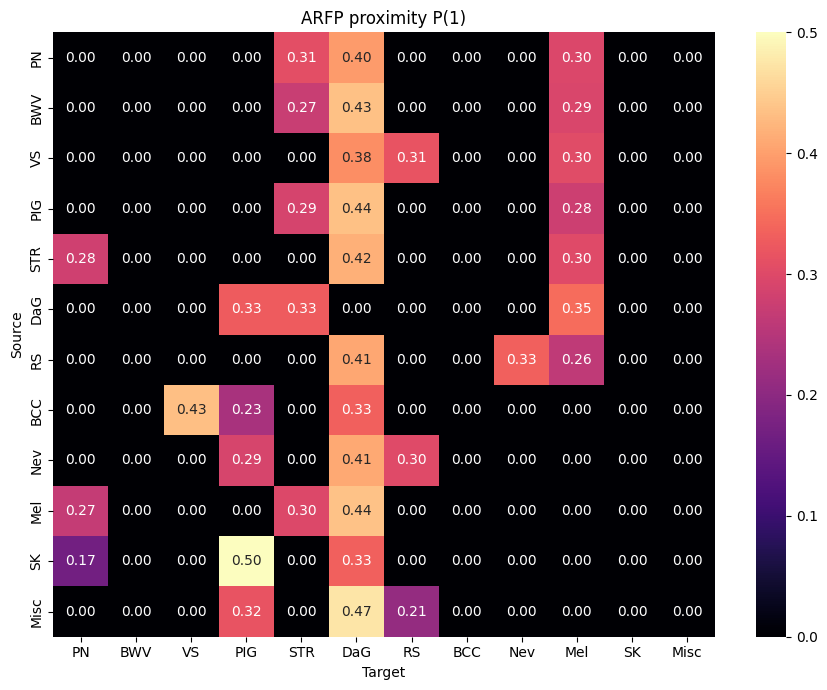

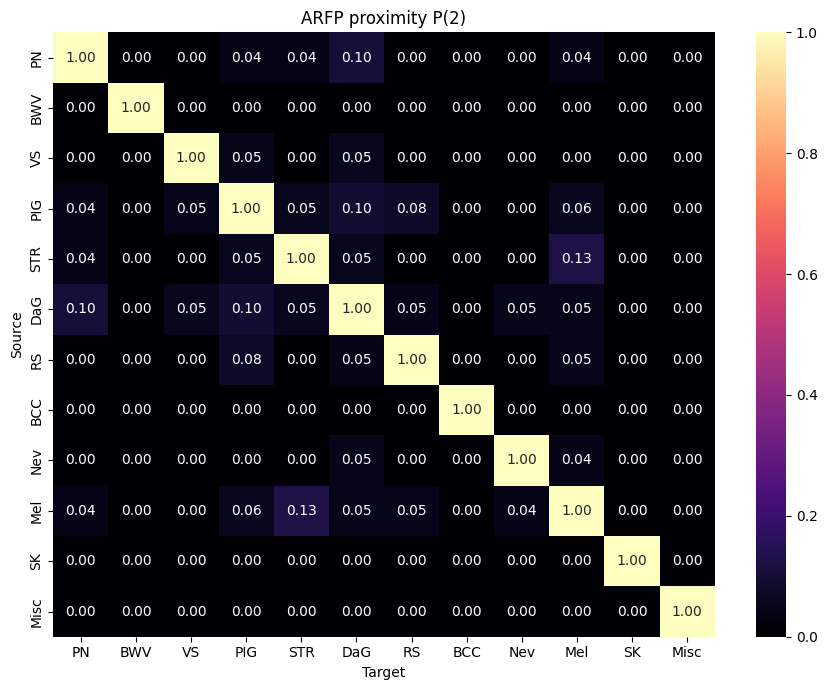

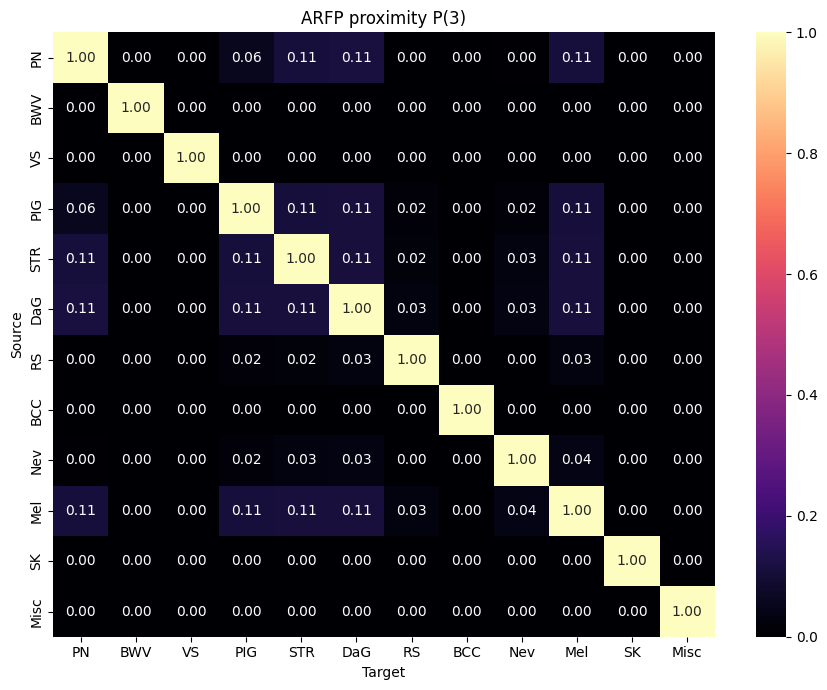

In [29]:

# 29D. ARFP proximity matrices P(0)...P(K)
def row_normalize(A):
    d = A.sum(axis=1)
    out = np.zeros_like(A, dtype=np.float64)
    for i,v in enumerate(d):
        if v > 0: out[i] = A[i] / v
    return out

P = {0: np.eye(NUM_NODES, dtype=np.float64)}
P[1] = row_normalize(A_sparse)
for k in range(2, GRAPH_K+1):
    left = np.linalg.matrix_power(P[1], k-1) @ np.linalg.matrix_power(P[1].T, k-1)
    right = np.linalg.matrix_power(P[1].T, k-1) @ np.linalg.matrix_power(P[1], k-1)
    P[k] = np.minimum(left, right) / 2.0
    np.fill_diagonal(P[k], 1.0)

for k,mat in P.items():
    np.save(GRAPH_DIR/f"ARFP_P{k}.npy", mat)
    pd.DataFrame(mat,index=GRAPH_NODES,columns=GRAPH_NODES).to_csv(GRAPH_DIR/f"ARFP_P{k}.csv")
    plt.figure(figsize=(9,7)); sns.heatmap(mat, annot=True, fmt=".2f", cmap="magma", xticklabels=GRAPH_NODES, yticklabels=GRAPH_NODES)
    plt.title(f"ARFP proximity P({k})"); plt.xlabel("Target"); plt.ylabel("Source"); plt.tight_layout()
    plt.savefig(PLOT_DIR/f"ARFP_P{k}.png", dpi=220); plt.show()



## Semantic node features

The graph uses one semantic vector per node. BERT is attempted first; if pretrained weights cannot be downloaded in the execution environment, a deterministic local embedding is used so the notebook remains runnable. The fallback is an engineering fallback, not a claim that it is equivalent to BERT.


In [30]:
import hashlib

# 29E. BERT semantic embeddings with deterministic fallback
SEM_DIM = 768
semantic_text = {
    "PN": "pigment network in a skin lesion",
    "BWV": "blue whitish veil in a skin lesion",
    "VS": "vascular structures in a skin lesion",
    "PIG": "irregular pigmentation in a skin lesion",
    "STR": "streaks in a skin lesion",
    "DaG": "dots and globules in a skin lesion",
    "RS": "regression structures in a skin lesion",
    "BCC": "basal cell carcinoma skin lesion diagnosis",
    "Nev": "benign melanocytic nevus skin lesion diagnosis",
    "Mel": "melanoma skin lesion diagnosis",
    "SK": "seborrheic keratosis skin lesion diagnosis",
    "Misc": "other miscellaneous skin lesion diagnosis",
}

def deterministic_embedding(text, dim=SEM_DIM):
    seed = int.from_bytes(hashlib.sha256(text.encode("utf-8")).digest()[:4], "little")
    rng = np.random.default_rng(seed)
    v = rng.normal(0,1,size=dim).astype(np.float32)
    return v / (np.linalg.norm(v)+1e-8)

semantic_vectors = {}
try:
    from transformers import AutoTokenizer, AutoModel
    tokenizer = AutoTokenizer.from_pretrained(globals().get("BERT_MODEL_NAME","bert-base-uncased"))
    bert = AutoModel.from_pretrained(globals().get("BERT_MODEL_NAME","bert-base-uncased")).to(DEVICE).eval()
    with torch.no_grad():
        for node,text in semantic_text.items():
            tok = tokenizer(text, return_tensors="pt", truncation=True, padding=True).to(DEVICE)
            h = bert(**tok).last_hidden_state[:,0,:].squeeze(0).cpu().numpy().astype(np.float32)
            semantic_vectors[node] = h / (np.linalg.norm(h)+1e-8)
    del bert
    print("Semantic encoder: BERT")
except Exception as e:
    warnings.warn(f"BERT unavailable; using deterministic fallback embeddings: {e}")
    semantic_vectors = {node: deterministic_embedding(text) for node,text in semantic_text.items()}
    print("Semantic encoder: deterministic fallback")

semantic_matrix = np.stack([semantic_vectors[n] for n in GRAPH_NODES]).astype(np.float32)
np.save(GRAPH_DIR/"semantic_node_matrix.npy", semantic_matrix)
pd.DataFrame(semantic_matrix, index=GRAPH_NODES).to_csv(GRAPH_DIR/"semantic_node_matrix.csv")
print("Semantic matrix:", semantic_matrix.shape)


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Semantic encoder: BERT
Semantic matrix: (12, 768)


In [31]:
# 29F. Case-specific node features using SOFT probabilities, not argmax labels.
# This avoids a non-differentiable hard prediction shortcut. The graph receives
# probability-weighted semantic vectors for all five diagnoses and all seven attributes.

def soft_state_embedding(prob, names, base_name):
    # prob: [B, number_of_states]; returns [B, SEM_DIM]
    vecs = []
    for state_name in names:
        vecs.append(torch.tensor(deterministic_embedding(f"{base_name}: {state_name}"), dtype=torch.float32))
    E = torch.stack(vecs, dim=0)  # [S,D]
    return torch.as_tensor(prob, dtype=torch.float32) @ E

def make_case_node_features(result):
    n = len(result["row_id"])
    X = np.zeros((n, NUM_NODES, SEM_DIM), dtype=np.float32)
    # Attribute nodes: probability-weighted state semantics.
    for j, name in enumerate(ATTR_NAMES):
        spec = CHECKLIST_SPECS[name]
        X[:, j] = soft_state_embedding(result["check_prob"][name], spec["classes"], name).numpy()
    # Diagnosis nodes: keep one separate node per diagnosis class.
    # X[:, NUM_ATTR:] has shape [B, 5, SEM_DIM], whereas
    # result["diag_prob"] @ diag_E has shape [B, SEM_DIM].
    # Therefore, assign each class node independently.
    diag_prob = np.asarray(result["diag_prob"], dtype=np.float32)
    if diag_prob.ndim != 2 or diag_prob.shape[1] != len(CLASS_NAMES):
        raise ValueError(
            f"diag_prob must have shape [N, {len(CLASS_NAMES)}], "
            f"but received {diag_prob.shape}"
        )
    diag_E = np.stack(
        [np.asarray(semantic_vectors[c], dtype=np.float32) for c in CLASS_NAMES],
        axis=0,
    )
    if diag_E.shape != (len(CLASS_NAMES), SEM_DIM):
        raise ValueError(
            f"Diagnosis semantic matrix must have shape "
            f"[{len(CLASS_NAMES)}, {SEM_DIM}], but received {diag_E.shape}"
        )
    for k in range(len(CLASS_NAMES)):
        # [N, 1] * [1, SEM_DIM] -> [N, SEM_DIM]
        X[:, NUM_ATTR + k, :] = diag_prob[:, k:k+1] * diag_E[k:k+1, :]
    return X

for split in ["train", "val", "test"]:
    Xn = make_case_node_features(extracted[split])
    np.save(ARRAY_DIR / f"{split}_case_node_features.npy", Xn)
    print(split, Xn.shape)


train (413, 12, 768)
val (203, 12, 768)
test (395, 12, 768)


In [32]:
# Shape validation for case-specific graph node features
for _split in ["train", "val", "test"]:
    _shape = np.load(ARRAY_DIR / f"{_split}_case_node_features.npy").shape
    assert _shape[1:] == (NUM_NODES, SEM_DIM), ( _split, _shape )
    print(f"{_split}: {_shape} OK")


train: (413, 12, 768) OK
val: (203, 12, 768) OK
test: (395, 12, 768) OK


In [33]:
# 29G. Differentiable multi-order graph encoder
class MultiOrderGraphEncoder(nn.Module):
    def __init__(self, in_dim=SEM_DIM, hidden=GRAPH_HIDDEN, orders=GRAPH_K):
        super().__init__()
        self.orders = orders
        self.proj = nn.Linear(in_dim, hidden)
        self.order_layers = nn.ModuleList([nn.Linear(hidden, hidden) for _ in range(orders + 1)])
        self.norm = nn.LayerNorm(hidden)
        self.out = nn.Linear(hidden, hidden)

    def forward(self, x, proximity):
        # x [B,N,D], P[k] [N,N]. P(0) is identity.
        h0 = F.gelu(self.proj(x))
        pieces = [self.order_layers[0](h0)]
        for k in range(1, self.orders + 1):
            pk = proximity[k].to(device=x.device, dtype=x.dtype)
            hk = torch.einsum("ij,bjd->bid", pk, h0)
            pieces.append(self.order_layers[k](hk))
        h = torch.stack(pieces, dim=0).mean(dim=0)
        return self.out(F.gelu(self.norm(h)))

proximity_tensors = {k: torch.tensor(v, dtype=torch.float32, device=DEVICE) for k,v in P.items()}
graph_encoder = MultiOrderGraphEncoder().to(DEVICE)
print("Graph encoder parameters:", sum(p.numel() for p in graph_encoder.parameters()))


Graph encoder parameters: 526336


In [34]:
# 29H. Corrected five-class GD-DDW fusion
# Five RemixFormer++ tokens are retained separately:
# 0 global clinical, 1 local clinical, 2 global dermoscopy, 3 local dermoscopy, 4 metadata.
# GD-DDW learns a normalized weight for each token and a normalized weight for each
# seven-point attribute. Every learned weight participates in the forward pass.

class CorrectedHybrid7PCL(nn.Module):
    def __init__(self, token_dim=768, graph_dim=GRAPH_HIDDEN, hidden=256,
                 num_tokens=5, num_classes=5, num_attr=7):
        super().__init__()
        self.num_tokens = num_tokens
        self.num_attr = num_attr
        self.token_adapters = nn.ModuleList([
            nn.Sequential(nn.LayerNorm(token_dim), nn.Linear(token_dim, hidden), nn.GELU())
            for _ in range(num_tokens)
        ])
        self.graph_adapter = nn.Sequential(nn.LayerNorm(graph_dim), nn.Linear(graph_dim, hidden), nn.GELU())
        self.token_graph_fuse = nn.Sequential(nn.LayerNorm(hidden * 2), nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(0.10))
        self.classifier = nn.Linear(hidden, num_classes)
        self.attribute_classifier = nn.Linear(hidden, num_attr)
        self.attr_node_classifier = nn.Linear(hidden, 1)
        self.raw_token_weights = nn.Parameter(torch.zeros(num_tokens))
        self.raw_attribute_weights = nn.Parameter(torch.zeros(num_attr))
        self.node_attention = nn.Linear(hidden, 1)

    def forward(self, remix_tokens, graph_nodes):
        # remix_tokens [B,5,768], graph_nodes [B,12,H]
        token_w = F.softmax(self.raw_token_weights, dim=0)
        attr_w = F.softmax(self.raw_attribute_weights, dim=0)
        token_features = torch.stack([self.token_adapters[i](remix_tokens[:, i]) for i in range(self.num_tokens)], dim=1)
        # Graph pooling is attention-based over the full 12-node graph.
        node_scores = self.node_attention(graph_nodes).squeeze(-1)
        node_alpha = F.softmax(node_scores, dim=1)
        graph_global = torch.sum(node_alpha.unsqueeze(-1) * graph_nodes, dim=1)
        g = self.graph_adapter(graph_global)
        # Each Remix token is explicitly conditioned on the graph.
        conditioned = []
        for i in range(self.num_tokens):
            conditioned.append(self.token_graph_fuse(torch.cat([token_features[:, i], g], dim=-1)))
        conditioned = torch.stack(conditioned, dim=1)
        z = torch.sum(conditioned * token_w.view(1, -1, 1), dim=1)
        # Attribute evidence is predicted from the seven attribute node embeddings.
        attr_nodes = graph_nodes[:, :self.num_attr]
        attr_logits = self.attr_node_classifier(attr_nodes).squeeze(-1)
        # The learned attribute weights are used to create a graph evidence vector.
        weighted_attr = torch.sum(torch.sigmoid(attr_logits) * attr_w.view(1, -1), dim=1, keepdim=True)
        z_aug = z + weighted_attr * torch.tanh(z)
        diag_logits = self.classifier(z_aug)
        # Auxiliary attribute head from the fused representation.
        aux_attr_logits = self.attribute_classifier(z_aug)
        return {
            "feature": z_aug,
            "diagnosis_logits": diag_logits,
            "attribute_logits": aux_attr_logits,
            "graph_attribute_logits": attr_logits,
            "diagnosis_prob": F.softmax(diag_logits, dim=-1),
            "attribute_prob": torch.sigmoid(aux_attr_logits),
            "graph_attribute_prob": torch.sigmoid(attr_logits),
            "token_weights": token_w,
            "attribute_weights": attr_w,
            "node_attention": node_alpha,
        }

hybrid = CorrectedHybrid7PCL().to(DEVICE)
print("Hybrid parameters:", sum(p.numel() for p in hybrid.parameters()))


Hybrid parameters: 1194266


In [35]:
# 29I. Dataset, losses, and optimizer
class HybridDataset(Dataset):
    def __init__(self, split):
        self.tokens = extracted[split]["tokens"].astype(np.float32)
        self.nodes = np.load(ARRAY_DIR / f"{split}_case_node_features.npy").astype(np.float32)
        self.y_diag = TARGETS[split]["y_diag"].astype(np.int64)
        self.y_attr = TARGETS[split]["y_attr"].astype(np.float32)
    def __len__(self): return len(self.y_diag)
    def __getitem__(self, i):
        return (torch.from_numpy(self.tokens[i]), torch.from_numpy(self.nodes[i]),
                torch.tensor(self.y_diag[i]), torch.from_numpy(self.y_attr[i]))

loaders = {s: DataLoader(HybridDataset(s), batch_size=32, shuffle=(s=="train"), num_workers=0)
           for s in ["train", "val", "test"]}

def focal_multiclass(logits, target, gamma=2.0):
    ce = F.cross_entropy(logits, target, reduction="none")
    pt = torch.exp(-ce)
    return (((1 - pt) ** gamma) * ce).mean()

def focal_binary(logits, target, gamma=2.0):
    bce = F.binary_cross_entropy_with_logits(logits, target, reduction="none")
    p = torch.sigmoid(logits)
    pt = target * p + (1 - target) * (1 - p)
    return (((1 - pt) ** gamma) * bce).mean()

optimizer = torch.optim.AdamW(
    list(hybrid.parameters()) + list(graph_encoder.parameters()),
    lr=DOWNSTREAM_LR, weight_decay=DOWNSTREAM_WD
)


Epoch 001 | train 0.8840 | val 0.9866 | val F1 0.1320
Epoch 002 | train 0.7703 | val 0.9817 | val F1 0.1320
Epoch 003 | train 0.7271 | val 0.9495 | val F1 0.1320
Epoch 004 | train 0.7065 | val 0.9275 | val F1 0.1320
Epoch 005 | train 0.6994 | val 0.9148 | val F1 0.1320
Epoch 006 | train 0.6842 | val 0.9065 | val F1 0.1320
Epoch 007 | train 0.6734 | val 0.8866 | val F1 0.1320
Epoch 008 | train 0.6621 | val 0.8760 | val F1 0.1320
Epoch 009 | train 0.6544 | val 0.8731 | val F1 0.1389
Epoch 010 | train 0.6441 | val 0.8634 | val F1 0.1521
Epoch 011 | train 0.6331 | val 0.8456 | val F1 0.1645
Epoch 012 | train 0.6253 | val 0.8384 | val F1 0.1704
Epoch 013 | train 0.6096 | val 0.8327 | val F1 0.1704
Epoch 014 | train 0.6020 | val 0.8253 | val F1 0.1704
Epoch 015 | train 0.5963 | val 0.8081 | val F1 0.1974
Epoch 016 | train 0.5858 | val 0.8076 | val F1 0.2024
Epoch 017 | train 0.5764 | val 0.7930 | val F1 0.2204
Epoch 018 | train 0.5693 | val 0.7817 | val F1 0.2369
Epoch 019 | train 0.5585 | v

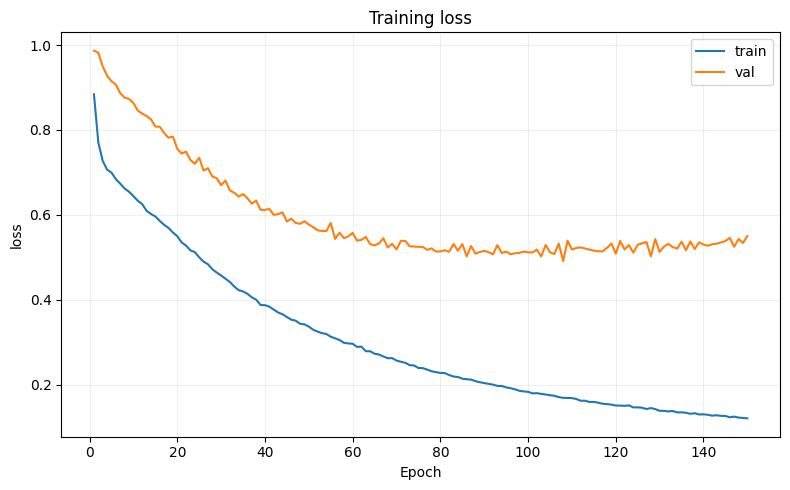

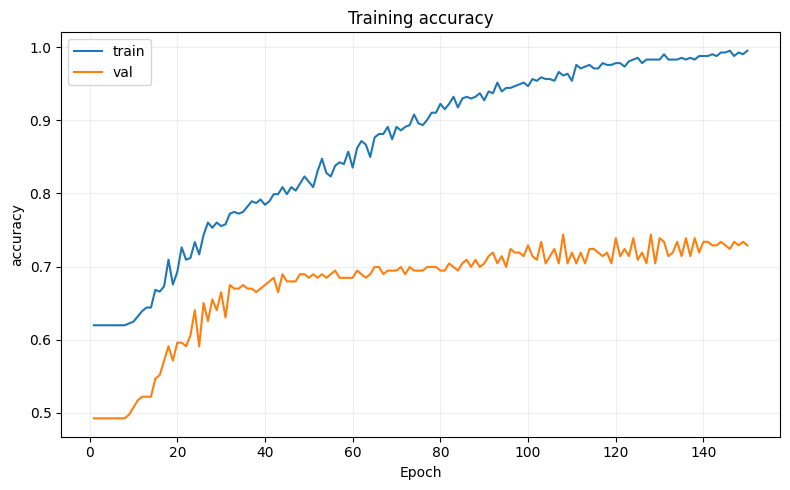

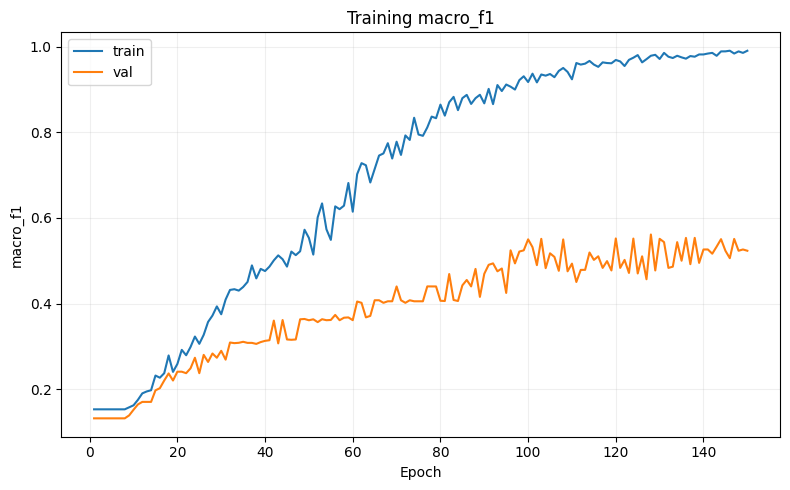

In [36]:
# 29J. Train with checkpointing and complete history
history=[]; best_val=float("inf"); best_state=None; patience=0
for epoch in range(1, DOWNSTREAM_EPOCHS + 1):
    row={"epoch": epoch}
    for split in ["train", "val"]:
        hybrid.train(split == "train"); graph_encoder.train(split == "train")
        losses=[]; ys=[]; ps=[]
        for tokens, nodes, yc, ya in loaders[split]:
            tokens, nodes = tokens.to(DEVICE), nodes.to(DEVICE)
            yc, ya = yc.to(DEVICE), ya.to(DEVICE)
            with torch.set_grad_enabled(split == "train"):
                gn = graph_encoder(nodes, proximity_tensors)
                out = hybrid(tokens, gn)
                loss_diag = focal_multiclass(out["diagnosis_logits"], yc)
                loss_attr = focal_binary(out["attribute_logits"], ya)
                loss_graph_attr = focal_binary(out["graph_attribute_logits"], ya)
                # Auxiliary graph attribute supervision makes the graph attribute branch useful.
                loss = loss_diag + 0.5 * loss_attr + 0.25 * loss_graph_attr
                if split == "train":
                    optimizer.zero_grad(set_to_none=True)
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(list(hybrid.parameters()) + list(graph_encoder.parameters()), 5.0)
                    optimizer.step()
            losses.append(float(loss.detach().cpu()))
            ys.extend(yc.detach().cpu().numpy()); ps.extend(out["diagnosis_prob"].argmax(1).detach().cpu().numpy())
        row[f"{split}_loss"] = float(np.mean(losses))
        row[f"{split}_accuracy"] = float(accuracy_score(ys, ps))
        row[f"{split}_macro_f1"] = float(f1_score(ys, ps, average="macro", zero_division=0))
    history.append(row)
    print(f"Epoch {epoch:03d} | train {row['train_loss']:.4f} | val {row['val_loss']:.4f} | val F1 {row['val_macro_f1']:.4f}")
    if row["val_loss"] < best_val:
        best_val = row["val_loss"]; patience = 0
        best_state = {"hybrid": {k:v.detach().cpu().clone() for k,v in hybrid.state_dict().items()},
                      "graph": {k:v.detach().cpu().clone() for k,v in graph_encoder.state_dict().items()},
                      "epoch": epoch, "val_loss": best_val}
        torch.save(best_state, CKPT_DIR / "best_corrected_5class_GDDW_downstream.pt")
    else:
        patience += 1
    if patience >= int(globals().get("GD_PATIENCE", 20)):
        print("Early stopping"); break
history_df = pd.DataFrame(history)
history_df.to_csv(TABLE_DIR / "training_history.csv", index=False)
for metric in ["loss", "accuracy", "macro_f1"]:
    plt.figure(figsize=(8,5)); plt.plot(history_df.epoch, history_df[f"train_{metric}"], label="train"); plt.plot(history_df.epoch, history_df[f"val_{metric}"], label="val")
    plt.title(f"Training {metric}"); plt.xlabel("Epoch"); plt.ylabel(metric); plt.legend(); plt.grid(alpha=.2); plt.tight_layout(); plt.savefig(PLOT_DIR / f"training_{metric}.png", dpi=220); plt.show()


In [37]:
# 29K. Restore best downstream state and collect all intermediate outputs
best_state = torch.load(CKPT_DIR / "best_corrected_5class_GDDW_downstream.pt", map_location=DEVICE)
hybrid.load_state_dict(best_state["hybrid"]); graph_encoder.load_state_dict(best_state["graph"])
hybrid.eval(); graph_encoder.eval()

def predict_split(split):
    all_diag=[]; all_attr=[]; all_graph_attr=[]; all_feat=[]; all_gnodes=[]; all_token_w=[]; all_node_alpha=[]
    with torch.no_grad():
        for tokens, nodes, yc, ya in loaders[split]:
            tokens, nodes = tokens.to(DEVICE), nodes.to(DEVICE)
            gn = graph_encoder(nodes, proximity_tensors); out = hybrid(tokens, gn)
            all_diag.append(out["diagnosis_prob"].cpu().numpy())
            all_attr.append(out["attribute_prob"].cpu().numpy())
            all_graph_attr.append(out["graph_attribute_prob"].cpu().numpy())
            all_feat.append(out["feature"].cpu().numpy()); all_gnodes.append(gn.cpu().numpy())
            all_node_alpha.append(out["node_attention"].cpu().numpy())
    return {"diag_prob":np.concatenate(all_diag), "attr_prob":np.concatenate(all_attr),
            "graph_attr_prob":np.concatenate(all_graph_attr), "feature":np.concatenate(all_feat),
            "graph_nodes":np.concatenate(all_gnodes), "node_attention":np.concatenate(all_node_alpha),
            "y_diag":TARGETS[split]["y_diag"], "y_attr":TARGETS[split]["y_attr"], "row_id":TARGETS[split]["row_id"]}

predictions = {s: predict_split(s) for s in ["train", "val", "test"]}
for s,r in predictions.items():
    for key in ["diag_prob", "attr_prob", "graph_attr_prob", "graph_nodes", "feature", "node_attention"]:
        np.save(ARRAY_DIR / f"{s}_{key}.npy", r[key])
print({s:r["diag_prob"].shape for s,r in predictions.items()})


{'train': (413, 5), 'val': (203, 5), 'test': (395, 5)}


In [38]:

# 29L. Five-class metrics and numeric matrices (not only plots)
def multiclass_metrics(r):
    y=r["y_diag"]; p=r["diag_prob"]; pred=p.argmax(1); cm=confusion_matrix(y,pred,labels=np.arange(NUM_CLASSES))
    result={"accuracy":accuracy_score(y,pred),"balanced_accuracy":balanced_accuracy_score(y,pred),"macro_precision":precision_score(y,pred,average="macro",zero_division=0),"macro_recall":recall_score(y,pred,average="macro",zero_division=0),"macro_f1":f1_score(y,pred,average="macro",zero_division=0),"weighted_f1":f1_score(y,pred,average="weighted",zero_division=0)}
    return result,cm,pred
metric_rows=[]
for s in ["train","val","test"]:
    met,cm,pred=multiclass_metrics(predictions[s]); met["split"]=s; metric_rows.append(met)
    pd.DataFrame(cm,index=CLASS_NAMES,columns=CLASS_NAMES).to_csv(TABLE_DIR/f"{s}_five_class_confusion_values.csv")
    pd.DataFrame(predictions[s]["diag_prob"],columns=CLASS_NAMES).to_csv(TABLE_DIR/f"{s}_five_class_probability_matrix.csv",index=False)
    print("\n",s,met); display(pd.DataFrame(cm,index=CLASS_NAMES,columns=CLASS_NAMES))
    print(classification_report(predictions[s]["y_diag"],pred,labels=np.arange(NUM_CLASSES),target_names=CLASS_NAMES,zero_division=0))
metrics_df=pd.DataFrame(metric_rows); metrics_df.to_csv(TABLE_DIR/"five_class_metrics.csv",index=False); display(metrics_df)

# Per-class probability distributions and numeric class metrics
per_class=[]
for c,name in enumerate(CLASS_NAMES):
    y=(predictions["test"]["y_diag"]==c).astype(int); p=predictions["test"]["diag_prob"][:,c]; pr=(p>=0.5).astype(int)
    per_class.append({"class":name,"precision":precision_score(y,pr,zero_division=0),"recall":recall_score(y,pr,zero_division=0),"f1":f1_score(y,pr,zero_division=0),"support":int(y.sum())})
per_class_df=pd.DataFrame(per_class); per_class_df.to_csv(TABLE_DIR/"test_per_class_metrics.csv",index=False); display(per_class_df)



 train {'accuracy': 0.42857142857142855, 'balanced_accuracy': np.float64(0.18609375), 'macro_precision': 0.18573529411764705, 'macro_recall': 0.18609375, 'macro_f1': 0.18584685310270815, 'weighted_f1': 0.428212382341284, 'split': 'train'}


,BCC,Nev,Mel,SK,Misc
BCC,0,10,5,2,2
Nev,13,155,62,13,13
Mel,2,58,18,1,11
SK,0,10,6,0,0
Misc,0,22,5,1,4


              precision    recall  f1-score   support

         BCC       0.00      0.00      0.00        19
         Nev       0.61      0.61      0.61       256
         Mel       0.19      0.20      0.19        90
          SK       0.00      0.00      0.00        16
        Misc       0.13      0.12      0.13        32

    accuracy                           0.43       413
   macro avg       0.19      0.19      0.19       413
weighted avg       0.43      0.43      0.43       413


 val {'accuracy': 0.7438423645320197, 'balanced_accuracy': np.float64(0.5159765807962529), 'macro_precision': 0.6597285067873303, 'macro_recall': 0.5159765807962529, 'macro_f1': 0.5498906128196746, 'weighted_f1': 0.7194851512523502, 'split': 'val'}


,BCC,Nev,Mel,SK,Misc
BCC,3,0,3,1,0
Nev,0,95,3,0,2
Mel,3,14,44,0,0
SK,0,3,1,2,4
Misc,0,18,0,0,7


              precision    recall  f1-score   support

         BCC       0.50      0.43      0.46         7
         Nev       0.73      0.95      0.83       100
         Mel       0.86      0.72      0.79        61
          SK       0.67      0.20      0.31        10
        Misc       0.54      0.28      0.37        25

    accuracy                           0.74       203
   macro avg       0.66      0.52      0.55       203
weighted avg       0.74      0.74      0.72       203


 test {'accuracy': 0.8050632911392405, 'balanced_accuracy': np.float64(0.62126485089028), 'macro_precision': 0.7959643040575244, 'macro_recall': 0.62126485089028, 'macro_f1': 0.6444468919705886, 'weighted_f1': 0.789791445581235, 'split': 'test'}


,BCC,Nev,Mel,SK,Misc
BCC,11,3,2,0,0
Nev,1,197,18,0,3
Mel,3,10,87,0,1
SK,1,8,1,3,6
Misc,0,18,2,0,20


              precision    recall  f1-score   support

         BCC       0.69      0.69      0.69        16
         Nev       0.83      0.90      0.87       219
         Mel       0.79      0.86      0.82       101
          SK       1.00      0.16      0.27        19
        Misc       0.67      0.50      0.57        40

    accuracy                           0.81       395
   macro avg       0.80      0.62      0.64       395
weighted avg       0.81      0.81      0.79       395



,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,split
0,0.428571,0.186094,0.185735,0.186094,0.185847,0.428212,train
1,0.743842,0.515977,0.659729,0.515977,0.549891,0.719485,val
2,0.805063,0.621265,0.795964,0.621265,0.644447,0.789791,test


,class,precision,recall,f1,support
0,BCC,0.833333,0.312500,0.454545,16
1,Nev,0.877934,0.853881,0.865741,219
2,Mel,0.840909,0.732673,0.783069,101
3,SK,0.000000,0.000000,0.000000,19
4,Misc,0.800000,0.400000,0.533333,40


,attribute,accuracy,precision,recall,f1,prevalence
0,PN,0.794937,0.620000,0.333333,0.433566,0.235443
1,BWV,0.843038,0.724138,0.280000,0.403846,0.189873
2,VS,0.832911,0.900000,0.219512,0.352941,0.207595
3,PIG,0.731646,0.595745,0.451613,0.513761,0.313924
4,STR,0.812658,0.638889,0.489362,0.554217,0.237975
5,DaG,0.777215,0.751412,0.751412,0.751412,0.448101
6,RS,0.749367,0.705882,0.113208,0.195122,0.268354


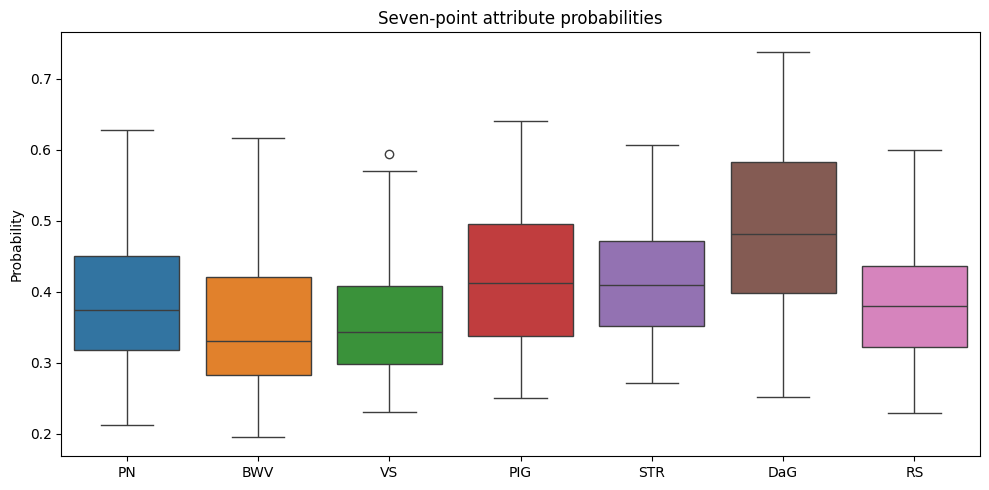

In [39]:

# 29M. Seven-attribute numeric outputs and plots
attr_rows=[]
for j,name in enumerate(ATTR_NAMES):
    y=predictions["test"]["y_attr"][:,j].astype(int); p=predictions["test"]["attr_prob"][:,j]; pr=(p>=0.5).astype(int)
    attr_rows.append({"attribute":name,"accuracy":accuracy_score(y,pr),"precision":precision_score(y,pr,zero_division=0),"recall":recall_score(y,pr,zero_division=0),"f1":f1_score(y,pr,zero_division=0),"prevalence":float(y.mean())})
attr_metrics_df=pd.DataFrame(attr_rows); attr_metrics_df.to_csv(TABLE_DIR/"test_7pcl_attribute_metrics.csv",index=False); display(attr_metrics_df)
plt.figure(figsize=(10,5)); sns.boxplot(data=pd.DataFrame(predictions["test"]["attr_prob"],columns=ATTR_NAMES)); plt.title("Seven-point attribute probabilities"); plt.ylabel("Probability"); plt.tight_layout(); plt.savefig(PLOT_DIR/"seven_attribute_probability_boxplot.png",dpi=220); plt.show()


## Graph-integrated heuristic

The heuristic is integrated with the trained graph outputs rather than operating only on the auxiliary attribute probabilities. It combines reliability-gated attribute likelihood, directed CKTG attribute-to-class support, graph-node embedding support, contradiction penalties, and nonlinear attribute interaction bonuses. The lambda value is selected on validation data only.


In [40]:
# 29N. Graph-integrated reliability-gated clinical heuristic
# This module explicitly consumes graph outputs from the trained 7PCL graph branch.
EPS = 1e-4

# Training-only class/attribute priors.
class_attr_prior = np.zeros((NUM_CLASSES, NUM_ATTR), dtype=np.float64)
for c in range(NUM_CLASSES):
    mask = TARGETS["train"]["y_diag"] == c
    class_attr_prior[c] = ((TARGETS["train"]["y_attr"][mask].sum(axis=0) + 1.0) /
                           (mask.sum() + 2.0)) if mask.sum() else 0.5

# Pairwise attribute co-occurrence prior for nonlinear interaction bonuses.
attr_pair_prior = np.zeros((NUM_CLASSES, NUM_ATTR, NUM_ATTR), dtype=np.float64)
for c in range(NUM_CLASSES):
    mask = TARGETS["train"]["y_diag"] == c
    yy = TARGETS["train"]["y_attr"][mask].astype(np.float64)
    if len(yy):
        attr_pair_prior[c] = (yy.T @ yy + 1.0) / (len(yy) + 2.0)
    else:
        attr_pair_prior[c] = 0.5

# Validation reliability gate.
reliability = []
for j in range(NUM_ATTR):
    yj = TARGETS["val"]["y_attr"][:, j]
    pj = predictions["val"]["attr_prob"][:, j]
    reliability.append(abs(np.corrcoef(yj, pj)[0, 1]) if np.std(yj) > 0 and np.std(pj) > 0 else 0.0)
reliability = np.nan_to_num(np.asarray(reliability), nan=0.0)
reliability = (reliability + 0.05) / (reliability.sum() + 0.05 * NUM_ATTR)

# Directed attribute-to-class graph support. A_attr_to_class is created earlier in the notebook.
_attr_class = np.asarray(A_attr_to_class, dtype=np.float64)
if _attr_class.shape != (NUM_ATTR, NUM_CLASSES):
    _attr_class = np.ones((NUM_ATTR, NUM_CLASSES), dtype=np.float64)
_attr_class = np.maximum(_attr_class, 0.0)
_attr_class = _attr_class / np.maximum(_attr_class.sum(axis=0, keepdims=True), EPS)

# Explicit contradiction rules: strong predicted attribute probability against a low prior
# creates a penalty. This remains soft and differentiable at the scoring level.
contradiction_mask = (class_attr_prior < 0.25).astype(np.float64)

def _safe_softmax(x):
    x = x - np.max(x, axis=1, keepdims=True)
    e = np.exp(np.clip(x, -50, 50))
    return e / np.maximum(e.sum(axis=1, keepdims=True), EPS)

def graph_integrated_heuristic_probs(diag_prob, attr_prob, graph_attr_prob=None,
                                     graph_nodes=None, node_attention=None, lam=1.0,
                                     graph_weight=0.35, contradiction_weight=0.20,
                                     interaction_weight=0.10):
    """
    Graph-integrated heuristic.

    Inputs are outputs of the trained neural/graph pipeline:
      diag_prob:       [B, C] neural diagnosis probabilities
      attr_prob:       [B, A] auxiliary attribute probabilities
      graph_attr_prob: [B, A] graph-attribute probabilities
      graph_nodes:     [B, N, H] graph encoder node embeddings
      node_attention:  [B, N] learned graph node attention

    Terms:
      1) reliability-gated attribute likelihood evidence
      2) directed CKTG attribute-to-class graph support
      3) graph embedding support using attribute/class node similarity
      4) contradiction penalty
      5) nonlinear pairwise attribute interaction bonus
    """
    p = np.clip(np.asarray(diag_prob, dtype=np.float64), EPS, 1.0 - EPS)
    a = np.clip(np.asarray(attr_prob, dtype=np.float64), EPS, 1.0 - EPS)
    ga = a if graph_attr_prob is None else np.clip(np.asarray(graph_attr_prob, dtype=np.float64), EPS, 1.0 - EPS)
    B = len(p)

    # Fuse the auxiliary attribute head and the graph attribute head.
    fused_attr = 0.5 * (a + ga)
    logp = np.log(p)
    evidence = np.zeros((B, NUM_CLASSES), dtype=np.float64)
    graph_support = np.zeros_like(evidence)
    contradiction = np.zeros_like(evidence)
    interaction = np.zeros_like(evidence)

    for c in range(NUM_CLASSES):
        q = np.clip(class_attr_prior[c], EPS, 1.0 - EPS)
        attr_ll = fused_attr * np.log(q) + (1.0 - fused_attr) * np.log(1.0 - q)
        evidence[:, c] = (attr_ll * reliability[None, :]).sum(axis=1)

        # Directed CKTG support: attribute evidence routed through graph edges to class c.
        edge_w = _attr_class[:, c][None, :]
        graph_support[:, c] = (fused_attr * edge_w * reliability[None, :]).sum(axis=1)

        # Penalize attributes that are strongly present but unlikely for class c.
        contradiction[:, c] = ((fused_attr * contradiction_mask[c][None, :]) * reliability[None, :]).sum(axis=1)

        # Pairwise nonlinear bonus for co-occurring attributes.
        for i in range(NUM_ATTR):
            for j in range(i + 1, NUM_ATTR):
                expected = attr_pair_prior[c, i, j]
                interaction[:, c] += (fused_attr[:, i] * fused_attr[:, j]) * expected * reliability[i] * reliability[j]

    # Graph embedding support: compare attribute-node and class-node representations.
    if graph_nodes is not None:
        gn = np.asarray(graph_nodes, dtype=np.float64)
        if gn.ndim == 3 and gn.shape[1] >= NUM_ATTR + NUM_CLASSES:
            attr_g = gn[:, :NUM_ATTR, :]
            class_g = gn[:, NUM_ATTR:NUM_ATTR + NUM_CLASSES, :]
            attr_g = attr_g / np.maximum(np.linalg.norm(attr_g, axis=-1, keepdims=True), EPS)
            class_g = class_g / np.maximum(np.linalg.norm(class_g, axis=-1, keepdims=True), EPS)
            sim = np.einsum('bah,bch->bac', attr_g, class_g)
            if node_attention is not None:
                na = np.asarray(node_attention, dtype=np.float64)[:, :NUM_ATTR]
                na = np.exp(na - na.max(axis=1, keepdims=True))
                na = na / np.maximum(na.sum(axis=1, keepdims=True), EPS)
                sim = sim * na[:, :, None]
            graph_support += 0.5 * np.sum(sim * fused_attr[:, :, None], axis=1)

    logits = logp + float(lam) * (evidence + graph_weight * graph_support
                                  - contradiction_weight * contradiction
                                  + interaction_weight * interaction)
    return _safe_softmax(logits), {
        "attribute_evidence": evidence,
        "graph_support": graph_support,
        "contradiction_penalty": contradiction,
        "interaction_bonus": interaction,
        "combined_score": evidence + graph_weight * graph_support
                          - contradiction_weight * contradiction
                          + interaction_weight * interaction
    }

# Validation-only positive-lambda tuning.
# Zero is excluded deliberately so that the graph-integrated heuristic is always
# active in the final calibrated model. The least harmful / best-performing
# positive value is selected using validation macro-F1.
val_y = predictions["val"]["y_diag"]
best_lam = float(HEURISTIC_LAMBDA_GRID[0])
best_score = -np.inf
lambda_rows = []
for lam in HEURISTIC_LAMBDA_GRID:
    hp, _ = graph_integrated_heuristic_probs(
        predictions["val"]["diag_prob"], predictions["val"]["attr_prob"],
        predictions["val"]["graph_attr_prob"], predictions["val"]["graph_nodes"],
        predictions["val"]["node_attention"], lam=lam)
    pred = hp.argmax(1)
    score = f1_score(val_y, pred, average="macro", zero_division=0)
    lambda_rows.append({"lambda": float(lam), "val_macro_f1": float(score),
                        "val_accuracy": float(accuracy_score(val_y, pred))})
    if score > best_score:
        best_score, best_lam = score, float(lam)

if not (best_lam > 0.0):
    raise RuntimeError(f"Non-zero heuristic calibration failed: best_lam={best_lam}")

lambda_df = pd.DataFrame(lambda_rows)
lambda_df.to_csv(TABLE_DIR / "graph_integrated_heuristic_lambda_sweep.csv", index=False)
print(f"Selected non-zero heuristic lambda: {best_lam:.4f}")
display(lambda_df)

for split in ["train", "val", "test"]:
    hp, terms = graph_integrated_heuristic_probs(
        predictions[split]["diag_prob"], predictions[split]["attr_prob"],
        predictions[split]["graph_attr_prob"], predictions[split]["graph_nodes"],
        predictions[split]["node_attention"], lam=best_lam)
    predictions[split]["heuristic_prob"] = hp
    predictions[split]["heuristic_pred"] = hp.argmax(1)
    for name, arr in terms.items():
        predictions[split][f"heuristic_{name}"] = arr
        np.save(ARRAY_DIR / f"{split}_heuristic_{name}.npy", arr)
    np.save(ARRAY_DIR / f"{split}_graph_integrated_heuristic_probability.npy", hp)

base = predictions["test"]["diag_prob"].argmax(1)
heur = predictions["test"]["heuristic_pred"]
y = predictions["test"]["y_diag"]
comparison = pd.DataFrame([
    {"model": "neural", "accuracy": accuracy_score(y, base),
     "balanced_accuracy": balanced_accuracy_score(y, base),
     "macro_f1": f1_score(y, base, average="macro", zero_division=0)},
    {"model": "neural_plus_graph_integrated_heuristic", "accuracy": accuracy_score(y, heur),
     "balanced_accuracy": balanced_accuracy_score(y, heur),
     "macro_f1": f1_score(y, heur, average="macro", zero_division=0)},
])
comparison.to_csv(TABLE_DIR / "neural_vs_graph_integrated_heuristic.csv", index=False)
display(comparison)
print("Best validation lambda:", best_lam)


Selected non-zero heuristic lambda: 0.1000


,lambda,val_macro_f1,val_accuracy
0,0.1,0.549891,0.743842
1,0.2,0.549891,0.743842
2,0.3,0.540356,0.738916
3,0.4,0.540356,0.738916
4,0.5,0.530534,0.733990
5,0.6,0.502710,0.719212
6,0.7,0.502710,0.719212
7,0.8,0.475726,0.714286
8,0.9,0.475726,0.714286
9,1.0,0.475726,0.714286


,model,accuracy,balanced_accuracy,macro_f1
0,neural,0.805063,0.621265,0.644447
1,neural_plus_graph_integrated_heuristic,0.807595,0.623245,0.649991


Best validation lambda: 0.1


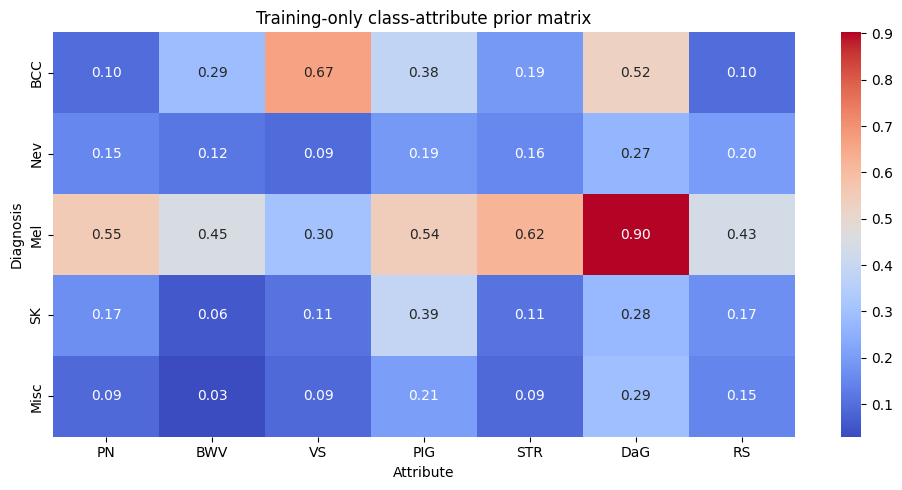

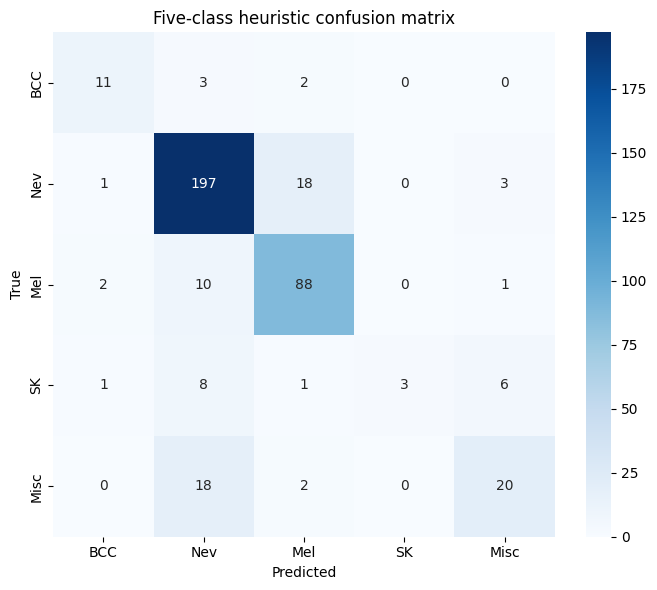

In [41]:

# 29O. Heuristic numeric matrices and plots
pd.DataFrame(class_attr_prior,index=CLASS_NAMES,columns=ATTR_NAMES).to_csv(TABLE_DIR/"train_class_attribute_prior.csv")
pd.DataFrame(class_attr_prior,index=CLASS_NAMES,columns=ATTR_NAMES).to_csv(GRAPH_DIR/"class_attribute_prior_matrix.csv")
plt.figure(figsize=(10,5)); sns.heatmap(class_attr_prior,annot=True,fmt=".2f",cmap="coolwarm",xticklabels=ATTR_NAMES,yticklabels=CLASS_NAMES); plt.title("Training-only class-attribute prior matrix"); plt.xlabel("Attribute"); plt.ylabel("Diagnosis"); plt.tight_layout(); plt.savefig(PLOT_DIR/"class_attribute_prior_matrix.png",dpi=220); plt.show()

cmh=confusion_matrix(y,heur,labels=np.arange(NUM_CLASSES)); pd.DataFrame(cmh,index=CLASS_NAMES,columns=CLASS_NAMES).to_csv(TABLE_DIR/"test_heuristic_confusion_values.csv")
plt.figure(figsize=(7,6)); sns.heatmap(cmh,annot=True,fmt="d",cmap="Blues",xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES); plt.title("Five-class heuristic confusion matrix"); plt.xlabel("Predicted"); plt.ylabel("True"); plt.tight_layout(); plt.savefig(PLOT_DIR/"five_class_heuristic_confusion_matrix.png",dpi=220); plt.show()

# Per-sample evidence table
sample_evidence=pd.DataFrame(predictions["test"]["heuristic_attribute_evidence"],columns=CLASS_NAMES); sample_evidence.insert(0,"row_id",predictions["test"]["row_id"]); sample_evidence.to_csv(TABLE_DIR/"test_heuristic_class_evidence.csv",index=False)



## Corrected 12-node directed graph visualization

This figure explicitly displays all seven attributes and all five diagnosis classes. Orange edges are attribute/diagnosis relations; gray edges are internal attribute relations. The matrix used for the figure is the exact saved 12 × 12 sparse matrix.


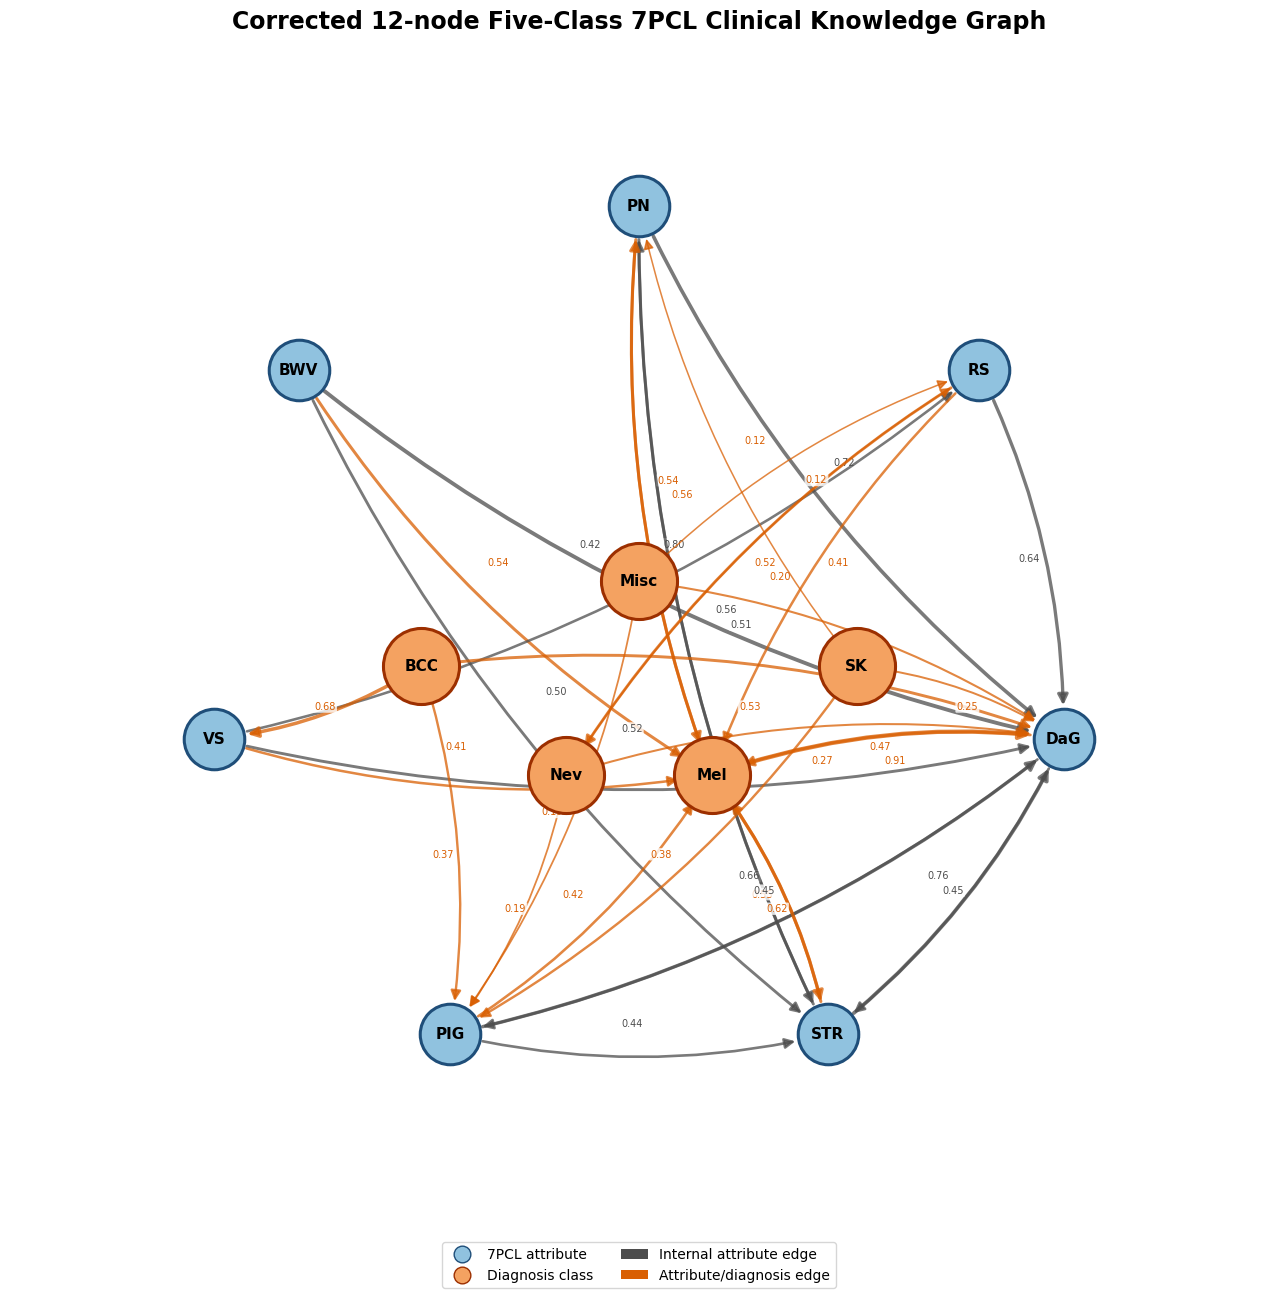

In [42]:

# 29P. Corrected 12-node graph plot
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
A_plot=A_sparse
angles=np.linspace(0,2*np.pi,NUM_ATTR,endpoint=False)+np.pi/2
positions={ATTR_NAMES[i]:(1.8*np.cos(angles[i]),1.8*np.sin(angles[i])) for i in range(NUM_ATTR)}
class_pos={"BCC":(-0.9,-0.1),"Nev":(-0.3,-0.55),"Mel":(0.3,-0.55),"SK":(0.9,-0.1),"Misc":(0,0.25)}
positions.update(class_pos)
fig,ax=plt.subplots(figsize=(15,13)); ax.set_aspect("equal"); ax.axis("off"); ax.set_title("Corrected 12-node Five-Class 7PCL Clinical Knowledge Graph",fontsize=17,fontweight="bold")
edge_rows=[]
for i,src in enumerate(GRAPH_NODES):
    for j,tgt in enumerate(GRAPH_NODES):
        w=float(A_plot[i,j])
        if i==j or w<=0: continue
        p1=np.array(positions[src]); p2=np.array(positions[tgt]); external=(i>=NUM_ATTR or j>=NUM_ATTR)
        color="#d95f02" if external else "#4d4d4d"
        rad=0.12 if i<j else -0.12
        ax.annotate("",xy=p2,xytext=p1,arrowprops=dict(arrowstyle="-|>",mutation_scale=15,linewidth=0.8+2.5*min(w,1),color=color,alpha=.75,shrinkA=24,shrinkB=24,connectionstyle=f"arc3,rad={rad}"))
        mid=(p1+p2)/2; off=np.array([-.03,.03]) if rad>0 else np.array([.03,-.03])
        ax.text(*(mid+off),f"{w:.2f}",fontsize=7,color=color,ha="center",bbox=dict(boxstyle="round,pad=.12",facecolor="white",edgecolor="none",alpha=.8))
        edge_rows.append({"source":src,"target":tgt,"weight":w,"relation":"attribute_diagnosis" if external else "internal_attribute"})
for node in GRAPH_NODES:
    x,y0=positions[node]; is_class=node in CLASS_NAMES
    ax.scatter(x,y0,s=3000 if is_class else 1900,c="#f4a261" if is_class else "#90c2df",edgecolors="#9c2f00" if is_class else "#1f4e79",linewidths=2.2,zorder=3)
    ax.text(x,y0,node,ha="center",va="center",fontsize=11,fontweight="bold",zorder=4)
pd.DataFrame(edge_rows).sort_values("weight",ascending=False).to_csv(TABLE_DIR/"corrected_12node_graph_edges.csv",index=False)
ax.legend(handles=[Line2D([0],[0],marker="o",color="w",label="7PCL attribute",markerfacecolor="#90c2df",markeredgecolor="#1f4e79",markersize=12),Line2D([0],[0],marker="o",color="w",label="Diagnosis class",markerfacecolor="#f4a261",markeredgecolor="#9c2f00",markersize=12),Patch(facecolor="#4d4d4d",label="Internal attribute edge"),Patch(facecolor="#d95f02",label="Attribute/diagnosis edge")],loc="lower center",bbox_to_anchor=(.5,-.04),ncol=2)
ax.set_xlim(-2.6,2.6); ax.set_ylim(-2.5,2.5); fig.tight_layout(); fig.savefig(PLOT_DIR/"corrected_12node_graph.png",dpi=300,bbox_inches="tight"); fig.savefig(PLOT_DIR/"corrected_12node_graph.pdf",bbox_inches="tight"); plt.show()


GD-DDW token weights


,token,weight
0,global_clinical,0.197844
1,local_clinical,0.198172
2,global_dermoscopy,0.200043
3,local_dermoscopy,0.200218
4,metadata,0.203724


GD-DDW attribute weights


,attribute,weight
0,PN,0.141548
1,BWV,0.141061
2,VS,0.141037
3,PIG,0.143349
4,STR,0.144523
5,DaG,0.145901
6,RS,0.142580


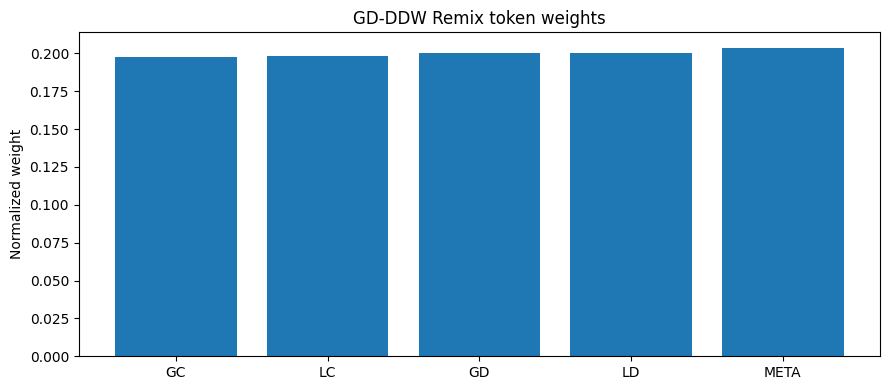

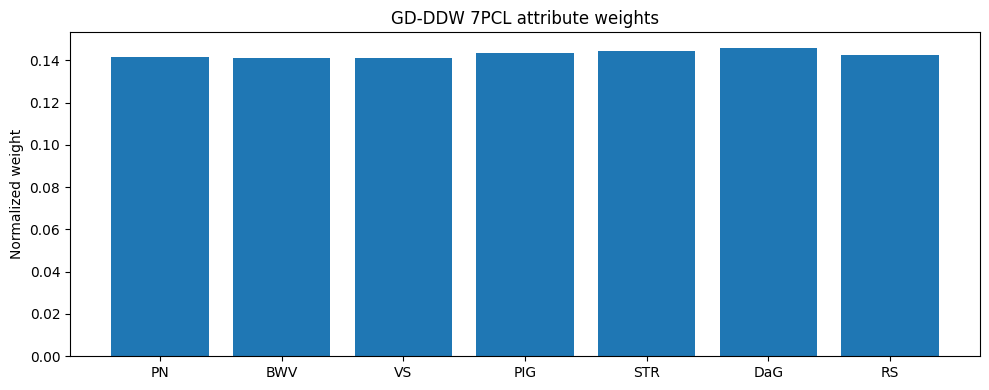

In [43]:
# 29Q. GD-DDW learned weights and intermediate matrices
with torch.no_grad():
    token_weights = F.softmax(hybrid.raw_token_weights, dim=0).cpu().numpy()
    attribute_weights = F.softmax(hybrid.raw_attribute_weights, dim=0).cpu().numpy()

pd.DataFrame({"token":["global_clinical","local_clinical","global_dermoscopy","local_dermoscopy","metadata"], "weight":token_weights}).to_csv(TABLE_DIR/"learned_GDDW_token_weights.csv", index=False)
pd.DataFrame({"attribute":ATTR_NAMES, "weight":attribute_weights}).to_csv(TABLE_DIR/"learned_GDDW_attribute_weights.csv", index=False)
print("GD-DDW token weights"); display(pd.DataFrame({"token":["global_clinical","local_clinical","global_dermoscopy","local_dermoscopy","metadata"], "weight":token_weights}))
print("GD-DDW attribute weights"); display(pd.DataFrame({"attribute":ATTR_NAMES, "weight":attribute_weights}))
plt.figure(figsize=(9,4)); plt.bar(["GC","LC","GD","LD","META"], token_weights); plt.title("GD-DDW Remix token weights"); plt.ylabel("Normalized weight"); plt.tight_layout(); plt.savefig(PLOT_DIR/"GDDW_token_weights.png",dpi=220); plt.show()
plt.figure(figsize=(10,4)); plt.bar(ATTR_NAMES, attribute_weights); plt.title("GD-DDW 7PCL attribute weights"); plt.ylabel("Normalized weight"); plt.tight_layout(); plt.savefig(PLOT_DIR/"GDDW_attribute_weights.png",dpi=220); plt.show()
# Mean node-attention matrix over the test set, with labels.
mean_node_attention = predictions["test"]["node_attention"].mean(axis=0)
pd.DataFrame([mean_node_attention], columns=GRAPH_NODES).to_csv(TABLE_DIR/"test_mean_node_attention.csv", index=False)


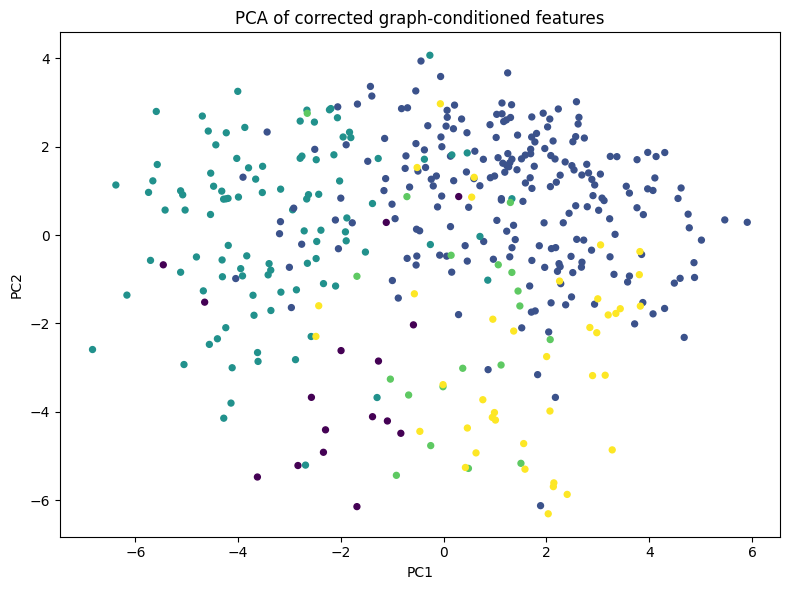

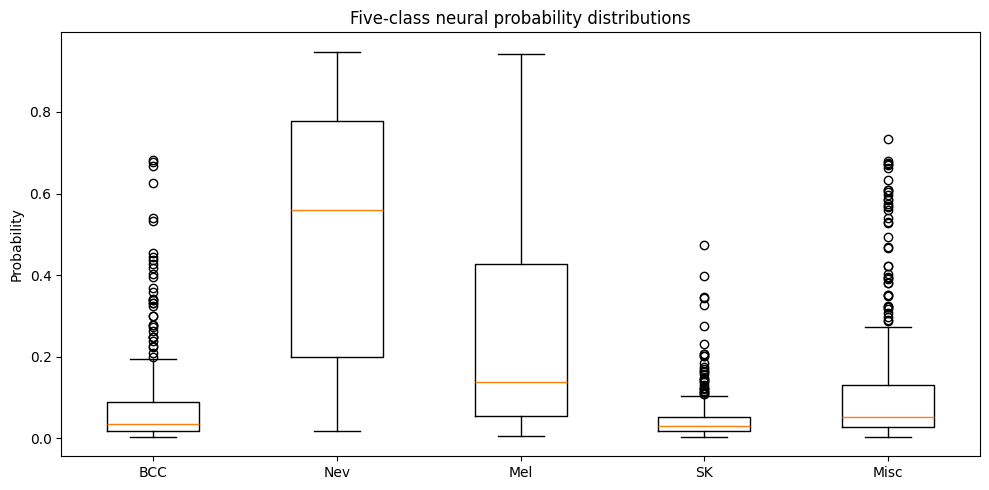

In [44]:

# 29R. PCA and probability plots for intermediate representations
from sklearn.decomposition import PCA
Z=predictions["test"]["feature"]
if len(Z)>=2:
    z2=PCA(n_components=2,random_state=SEED).fit_transform(Z)
    plt.figure(figsize=(8,6)); plt.scatter(z2[:,0],z2[:,1],c=predictions["test"]["y_diag"],s=18); plt.title("PCA of corrected graph-conditioned features"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.tight_layout(); plt.savefig(PLOT_DIR/"pca_graph_conditioned_features.png",dpi=220); plt.show()
plt.figure(figsize=(10,5)); plt.boxplot([predictions["test"]["diag_prob"][:,i] for i in range(NUM_CLASSES)],labels=CLASS_NAMES); plt.title("Five-class neural probability distributions"); plt.ylabel("Probability"); plt.tight_layout(); plt.savefig(PLOT_DIR/"five_class_probability_distributions.png",dpi=220); plt.show()



## End-to-end deployment checkpoint

The saved package contains the downstream graph encoder, hybrid diagnosis model, graph matrices, semantic node matrix, class names, heuristic priors, selected heuristic lambda, and the frozen RemixFormer++ checkpoint state when available. The exact Python definitions of `RemixFormerPP` must remain available when reconstructing the upstream model locally.


In [45]:
# 29S. Save one end-to-end checkpoint and JSON result package
upstream_state = None
if "model" in globals():
    upstream_state = {k:v.detach().cpu() for k,v in model.state_dict().items()}
end_to_end = {
    "format_version":"remixformerpp_7pcl_GDDW_5class_graph_integrated_heuristic_v3",
    "class_names":CLASS_NAMES, "attribute_names":ATTR_NAMES, "graph_nodes":GRAPH_NODES,
    "token_dim":768, "num_remix_tokens":5, "semantic_dim":SEM_DIM,
    "graph_hidden":GRAPH_HIDDEN, "graph_order":GRAPH_K,
    "A_internal":A_internal, "A_attr_to_class":A_attr_to_class, "A_class_to_attr":A_class_to_attr,
    "A_full":A_full, "A_sparse":A_sparse, "P":P, "semantic_matrix":semantic_matrix,
    "class_attr_prior":class_attr_prior, "attr_pair_prior":attr_pair_prior, "reliability":reliability,
    "contradiction_mask":contradiction_mask, "heuristic_lambda":best_lam,
    "heuristic_components":["attribute_evidence","graph_support","contradiction_penalty","interaction_bonus"],
    "hybrid_state_dict":{k:v.detach().cpu() for k,v in hybrid.state_dict().items()},
    "graph_encoder_state_dict":{k:v.detach().cpu() for k,v in graph_encoder.state_dict().items()},
    "upstream_remix_state_dict":upstream_state,
    "upstream_checkpoint_info":globals().get("checkpoint_info",{}),
}
final_ckpt = CKPT_DIR / "RemixFormerPP_7PCL_GDDW_5Class_Heuristic_END_TO_END.pt"
torch.save(end_to_end, final_ckpt)
result_json = {
    "format_version": end_to_end["format_version"], "classes":CLASS_NAMES, "attributes":ATTR_NAMES,
    "graph_nodes":GRAPH_NODES, "graph_shape":list(A_full.shape), "graph_order":GRAPH_K,
    "best_epoch":int(best_state.get("epoch",-1)), "best_val_loss":float(best_state.get("val_loss",float("nan"))),
    "heuristic_lambda":float(best_lam), "heuristic_reliability":reliability.tolist(),
    "metrics":metrics_df.replace({np.nan:None}).to_dict(orient="records"),
    "neural_vs_heuristic":comparison.to_dict(orient="records"),
    "learned_GDDW_token_weights":token_weights.tolist(), "learned_GDDW_attribute_weights":attribute_weights.tolist(),
    "artifacts":{"checkpoint":str(final_ckpt),"plots":str(PLOT_DIR),"tables":str(TABLE_DIR),"arrays":str(ARRAY_DIR),"graphs":str(GRAPH_DIR)}
}
(ROOT/"results.json").write_text(json.dumps(result_json, indent=2, default=lambda x:x.item() if hasattr(x,"item") else str(x)))
print("Saved end-to-end checkpoint:", final_ckpt)
print("Saved results:", ROOT/"results.json")


Saved end-to-end checkpoint: /kaggle/working/remixformerpp_7pcl_paper_aligned/checkpoints/RemixFormerPP_7PCL_GDDW_5Class_Heuristic_END_TO_END.pt
Saved results: /kaggle/working/remixformerpp_7pcl_paper_aligned/results.json


In [46]:
# 29T. Local deployment helper
class RemixFormerPP7PCLFiveClassDeployment:
    """Loads the downstream package. The original RemixFormerPP class definition and
    preprocessing must also be present when reconstructing the upstream model locally."""
    def __init__(self, checkpoint_path, device=None):
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        self.package = torch.load(checkpoint_path, map_location="cpu")
        self.graph_encoder = MultiOrderGraphEncoder(in_dim=self.package["semantic_dim"], hidden=self.package["graph_hidden"], orders=self.package["graph_order"]).to(self.device)
        self.graph_encoder.load_state_dict(self.package["graph_encoder_state_dict"]); self.graph_encoder.eval()
        self.hybrid = CorrectedHybrid7PCL(token_dim=self.package["token_dim"], graph_dim=self.package["graph_hidden"], num_tokens=self.package["num_remix_tokens"], num_classes=len(self.package["class_names"]), num_attr=len(self.package["attribute_names"])).to(self.device)
        self.hybrid.load_state_dict(self.package["hybrid_state_dict"]); self.hybrid.eval()
        self.proximity = {int(k):torch.tensor(v,dtype=torch.float32,device=self.device) for k,v in self.package["P"].items()}
        self.class_attr_prior = np.asarray(self.package["class_attr_prior"]); self.reliability = np.asarray(self.package["reliability"]); self.lam=float(self.package["heuristic_lambda"])
        self.class_names=self.package["class_names"]
    @torch.no_grad()
    def heuristic_probs(self, diag_prob, attr_prob, graph_attr_prob=None, graph_nodes=None, node_attention=None):
        # Reuse the same graph-integrated heuristic used during validation/test evaluation.
        hp, terms = graph_integrated_heuristic_probs(
            diag_prob, attr_prob, graph_attr_prob, graph_nodes, node_attention, lam=self.lam)
        return hp, terms
    def predict_from_remix_tokens(self, remix_tokens, case_node_features):
        t=torch.as_tensor(remix_tokens,dtype=torch.float32,device=self.device)
        n=torch.as_tensor(case_node_features,dtype=torch.float32,device=self.device)
        if t.ndim==2: t=t[None,:]
        if n.ndim==2: n=n[None,:,:]
        gn=self.graph_encoder(n,self.proximity); out=self.hybrid(t,gn)
        p=out["diagnosis_prob"].cpu().numpy(); a=out["attribute_prob"].cpu().numpy()
        ga=out["graph_attribute_prob"].cpu().numpy()
        gnodes=gn.cpu().numpy()
        natt=out["node_attention"].cpu().numpy()
        hp, terms=self.heuristic_probs(p, a, ga, gnodes, natt)
        return {"neural_probabilities":p,"attribute_probabilities":a,
                "graph_attribute_probabilities":ga,
                "heuristic_probabilities":hp,
                "heuristic_terms":terms,
                "prediction":[self.class_names[int(i)] for i in hp.argmax(1)]}

print("Deployment helper defined. It expects RemixFormer++ tokens shaped [B,5,768] and 12-node case features.")


Deployment helper defined. It expects RemixFormer++ tokens shaped [B,5,768] and 12-node case features.



## Scientific caution

- The 12-node five-class graph and the post-hoc heuristic are proposed extensions for this research, not the original melanoma-only graph.
- Graph statistics and heuristic priors are computed from the training split only.
- The checkpoint is deployable only when the original `RemixFormerPP` class and its preprocessing pipeline are available to reconstruct the upstream model and generate the required feature vector/case-node inputs.
- Validate the five-class label mapping and the exact 7PCL equations against the source paper before reporting final scientific claims.


## Final validation checklist
Before training, verify the upstream checkpoint architecture, token order, dataset paths, and label mappings. This notebook is a five-class research extension; the original 7PCL paper is melanoma-centered.
